# Wildfire Drone Fleet — main technical notebook

**Consolidated through 11 October 2026 · archive review, no new training**

This notebook contains the implemented MDP, the three RL methods, pseudocode linked to executable source, historical tuning and failure diagnostics, and the frozen 40×40 main study. Tables and figures are regenerated from committed records. Saved outputs allow review without fitting models again.

**Main finding:** the masked DQN, REINFORCE and A2C controllers retained all three drones in every final evaluation mission. They did not pass the predeclared learned-contribution or Greedy performance gates. Masked random also preserved the fleet. Safety supplied by feasibility rules must be distinguished from learned surveillance quality.

This is a technical record and private planning aid. The supplied COMP6008 brief prohibits generative AI in assessed submissions; the group must independently prepare and understand its assessed work. Contributor names and section attribution remain to be supplied by the group.

| Evidence | Meaning |
| --- | --- |
| Historical 20×20 experiments | Dated development, validation, tuning and test evidence; original revisions retained |
| Supervised diagnostics | Tests of fitting, representation, coverage and ranking; zero RL updates unless explicitly labelled RL |
| Frozen 40×40 study | Nine independently initialized RL fits, final checkpoints, 20 fresh worlds per policy, complete replay audit |
| This execution | Rebuilds analysis, figures and code listings; performs no fits and opens no new evaluation worlds |

Navigate by the numbered sections: setup; problem and MDP; baselines and mask; algorithms; experiment history; 20×20 results; 40×40 results; grid comparison; interpretation; reproducibility; implementation appendix; references and deliverables.

## 1. Setup and evidence provenance

Open this notebook from a complete checkout of the repository. The simulator and learners are our own Python implementations in `src/wild_drone`; no Stable Baselines `.learn()` implementation is used.

Local setup, with Python 3.11 or 3.12:

```bash
python -m pip install -r requirements.txt
python -m pip install -e .
python -m jupyter notebook Wildfire_Drone_Fleet.ipynb
```

In Colab, first place or clone the complete repository in `/content/wild-drone-appeared`, change to that directory and install the requirements in the active kernel (`%pip install -r requirements.txt`, then `%pip install -e .`). Restart the kernel after installing PyTorch if necessary. Review uses CPU and does not need a GPU. The separate Colab training helper remains a historical workflow, not the main final-results notebook.

**Run All is review only.** Training and audit commands are documented later as text. The final study used source `855e5510ff46b16082ab7d551e7c228acab6f572`. The historical 20×20 study was not rerun after the October 10 correctness fixes. Execution package versions printed below identify this analysis runtime, not the original training runtimes.

In [1]:
from pathlib import Path
import sys, json, inspect, hashlib, html, platform, re
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, HTML, display

REPO = Path.cwd()
candidates = [REPO, REPO.parent, Path('/content/wild-drone-appeared')]
REPO = next((p for p in candidates if (p/'src/wild_drone/environment.py').exists()), None)
if REPO is None:
    raise FileNotFoundError('Open the notebook from a complete repository checkout; see setup above.')
sys.path.insert(0, str(REPO/'src'))
from wild_drone.config import EnvConfig
from wild_drone.environment import WildfireFleetEnv, encode_action, decode_action
from wild_drone import learning, masked_learning, baselines, experiments

ARCHIVES = REPO/'docs/experiments'
HISTORICAL = ARCHIVES/'final-2026-10-05'
MAIN = ARCHIVES/'rl-main-2026-10-11'
ALGORITHMS = ['dqn', 'reinforce', 'a2c']
POLICIES = ALGORITHMS + ['greedy', 'sweep', 'random', 'masked_random']
FROZEN_SOURCE = '855e5510ff46b16082ab7d551e7c228acab6f572'
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 16)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 90, 'savefig.dpi': 90, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})
print('Mode: committed archive review; no training calls')
print('Analysis Python:', platform.python_version())
print('Analysis packages:', {p: importlib.metadata.version(p) for p in
      ['numpy','pandas','matplotlib','gymnasium','torch','nbformat','ipykernel']})

Mode: committed archive review; no training calls
Analysis Python: 3.12.14
Analysis packages: {'numpy': '2.3.5', 'pandas': '2.2.3', 'matplotlib': '3.10.8', 'gymnasium': '1.4.0', 'torch': '2.5.1+cpu', 'nbformat': '5.11.1', 'ipykernel': '7.4.0'}


In [2]:
def show_source(obj):
    lines, first = inspect.getsourcelines(obj)
    filename = Path(inspect.getsourcefile(obj)).relative_to(REPO).as_posix()
    numbered = ''.join(f'{first+i:4d}  {line}' for i, line in enumerate(lines))
    display(HTML(f'<details><summary>{html.escape(filename)} — '
                 f'{html.escape(obj.__qualname__)} (lines {first}–{first+len(lines)-1})'
                 f'</summary><pre>{html.escape(numbered)}</pre></details>'))

def map_steps(obj, anchors):
    lines, first = inspect.getsourcelines(obj)
    path = Path(inspect.getsourcefile(obj)).relative_to(REPO).as_posix()
    rows = []
    for step, marker in anchors:
        matches = [first+i for i, line in enumerate(lines) if marker in line]
        if not matches:
            raise AssertionError(f'Pseudocode mapping no longer matches source: {marker}')
        rows.append({'pseudocode step': step, 'implementation': path,
                     'line(s)': ', '.join(map(str, matches)), 'source anchor': marker})
    display(pd.DataFrame(rows))

def finish_plot(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 2. Problem, scope and Markov decision process

One central controller commands three drones simultaneously. The task is persistent inspection of a synthetic changing fire field while sharing a single charger. The goal is recent inspection of important locations with low energy use, few blocked movements and no drone loss. Finishing a fit, retaining the fleet and performing useful surveillance are separate outcomes.

This is a **fully observable finite-horizon MDP**, not a partially observed field deployment. Terrain, fuel, fire, inspection ages, priority, all drone batteries and locations, wind, charger ownership and remaining time are available to the policy. Decisions trade immediate inspection against travel, battery reserve and charger contention. RL is investigated as a learned decision rule; strong planning baselines are essential because full state is available.

Let $S_t=(F_t,U_t,T,P,A_t,X_t,B_t,L_t,w_t,o_t,H-t)$. Here $F$ is burning status, $U$ fuel, $T$ terrain, $P$ static priority, $A$ inspection age, $X$ the three positions, $B$ batteries, $L$ loss flags, $w$ wind and $o\in\{-1,0,1,2\}$ the charger owner. Given $S_t$ and a joint action, the next-state distribution does not require earlier history. The complete random-generator state is used for reproducible simulation, not exposed as an observation.

| Observation | Raw state and normalization | Shape |
| --- | --- | --- |
| Map planes | burning, fuel/max fuel, terrain, priority/3, age/age limit | $5\times N\times N$ |
| Drone rows | row/(N−1), column/(N−1), battery/capacity, loss flag | $3\times4$ |
| Globals | wind one-hot (5), charger one-hot (4), base coordinates (2), remaining time (1) | 12 |
| Neural spatial augmentation | one location plane per live drone and one base plane | 4 additional maps |

Ages are capped at $\max(H,D+1)$, where $D$ is the inspection deadline. Three priority zones have priority 3, elsewhere 1. Terrain and initial fuel/fire/priority placement vary by scenario seed; all drones start at the central base with full batteries. Fuel at base is zero. These dimensionless settings are a simplified cellular model, not calibrated fire physics or aircraft endurance.

Each drone command is stay/up/down/left/right, indexed 0–4. The joint action is
$$a=25c_0+5c_1+c_2\in\{0,\ldots,124\}.$$
This is one simultaneous fleet decision, not three environment steps.

### Transition order and reward

The implemented step order matters:

1. Decode the action; resolve off-grid proposals and iterative same-cell/swap conflicts. Multiple drones may occupy base. Off-grid proposals revert; the collision count records blocked moving drones in conflicts, not all invalid commands.
2. Apply charging, energy use and new losses. Charging requires a live drone to have been at base and to stay there. Arrivals cannot charge on the arrival step. A retained eligible owner charges; otherwise lowest battery then drone ID chooses an owner. A full charge releases ownership.
3. Increase inspection ages with the cap. Compute hazard-weighted priorities using the fire **before** its evolution. Inspect the union of live drones' square footprints, clipped at boundaries, and reset those ages to zero. Overlap is counted once per step; grounded drones also inspect.
4. Compute reward and inspection metrics, then evolve fire/wind and advance time. The returned observation contains the evolved fire; reported inspection freshness/overdue retain the pre-fire evaluation weights.
5. End at $H$ or when all drones are lost. The environment reports this as termination, with remaining time included in state; it does not report an external truncation.

For $W_t(x)=P(x)(1+2F_t(x)+\mathbf1_{\mathrm{frontier}}(x))$, aged values $A_t^+(x)$ and inspection union $I_t$,
$$g_t=\frac{\sum_{x\in I_t}W_t(x)\min(A_t^+(x)/D,1)}{\sum_x W_t(x)}.$$
With post-inspection ages $\widetilde A_t$, freshness and overdue are
$$f_t=\frac{\sum_x W_t(x)[1-\min(\widetilde A_t(x)/D,1)]}{\sum_xW_t(x)},\qquad
u_t=\frac{\sum_x W_t(x)\mathbf1[\widetilde A_t(x)>D]}{\sum_xW_t(x)}.$$
The reward uses **inspection gain**, not the full freshness score:
$$r_t=\alpha g_t-\beta u_t-\lambda E_t/B_{\max}-\kappa C_t-\mu\Delta L_t
-\beta(H-t-1)\mathbf1[\text{all lost after this action}].$$
Main-study weights are $(\alpha,\beta,\lambda,\kappa,\mu)=(1,0.1,0.02,0.2,5)$. $E_t$ is actual energy spent, $C_t$ counts blocked movers and $\Delta L_t$ is newly lost drones. Commanded non-stay moves still cost move energy when blocked; a ground stay costs zero, an airborne stay costs hover energy. Batteries empty away from base cause permanent loss.

Each burning orthogonal neighbour contributes clipped ignition probability $p_j=\mathrm{clip}(p_0\,T(x)\,b_j,0,1)$, with wind multiplier $b_j$ in the wind direction. Ignition probability is $1-\prod_j(1-p_j)$. Existing burning cells consume one unit of fuel; newly ignited cells start consuming on the next step. A wind change redraw may choose the existing wind. Random samples are drawn every step independently of drone actions, enabling paired-world comparisons.

Metrics use the full planned horizon: after early fleet failure, remaining freshness is zero and overdue is one. Safe returns and charge completions are event counts, not “all drones finished at base.” Inspection visits are not unique land coverage. A freshness value of 0.08 is not 8% of land covered.

In [3]:
from gymnasium.utils.env_checker import check_env
frozen = json.loads((REPO/'configs/rl-main-frozen.json').read_text())
development = json.loads((REPO/'configs/development.json').read_text())
main_env = EnvConfig(**frozen['environment'])
check_env(WildfireFleetEnv(main_env), skip_render_check=True)
assert all(encode_action(decode_action(a)) == a for a in range(125))
map_steps(WildfireFleetEnv.step, [
    ('1. decode and resolve movement', 'collisions = self._resolve_moves'),
    ('2. energy, charge and losses', 'self._energy_and_charging'),
    ('3. age then compute gain and inspect', 'self.ages[:] = np.minimum'),
    ('4. reward before fire', 'reward = float(sum(components.values()))'),
    ('5. evolve, advance and terminate', 'self._evolve_fire()')])
print('Gymnasium check and all 125 action encodings passed; these are simulator checks, not fits.')

,pseudocode step,implementation,line(s),source anchor
0,1. decode and resolve movement,src/wild_drone/environment.py,203,collisions = self._resolve_moves
1,"2. energy, charge and losses",src/wild_drone/environment.py,204,self._energy_and_charging
2,3. age then compute gain and inspect,src/wild_drone/environment.py,205,self.ages[:] = np.minimum
3,4. reward before fire,src/wild_drone/environment.py,222,reward = float(sum(components.values()))
4,"5. evolve, advance and terminate",src/wild_drone/environment.py,223,self._evolve_fire()


Gymnasium check and all 125 action encodings passed; these are simulator checks, not fits.


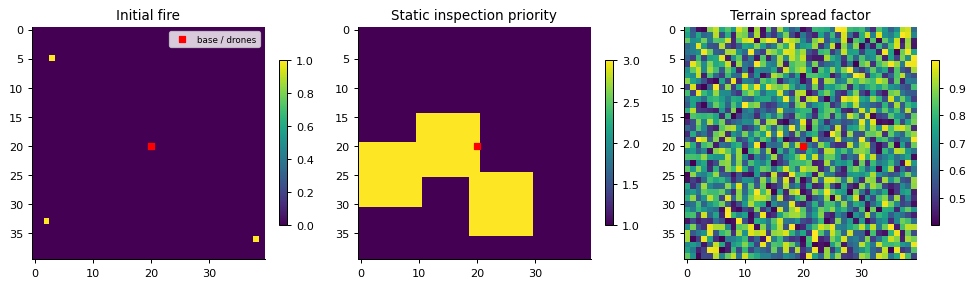

In [4]:
env = WildfireFleetEnv(main_env)
env.reset(seed=0)  # existing training world; illustration only
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, data, title in zip(axes, [env.burning, env.priority, env.terrain],
                         ['Initial fire', 'Static inspection priority', 'Terrain spread factor']):
    im = ax.imshow(data, origin='upper', cmap='viridis')
    ax.scatter([env.base[1]], [env.base[0]], marker='s', color='red', s=25, label='base / drones')
    ax.set_title(title); fig.colorbar(im, ax=ax, shrink=0.7)
axes[0].legend(fontsize=7)
finish_plot(fig)

## 3. Baselines and feasibility mask

| Controller | Decision rule | Role |
| --- | --- | --- |
| Random | Uniform over all 125 commands | Unrestricted reference |
| Masked random | Uniform over feasible joint commands | Isolates the contribution of feasibility rules |
| Greedy | Scores native candidate actions by immediate inspection value | Strong surveillance baseline |
| Sweep | Follows a systematic route with battery-aware native candidates | Structured nonlearned patrol |
| All stay | Keeps every drone at base | Historical trivial safe control |
| Rolling-horizon planner | Short lookahead over candidates and sampled transitions | Historical 20×20 planning reference |

The main 40×40 comparison uses the first four. All stay and the rolling-horizon planner remain in the historical evidence; they were not silently added to the frozen final comparison.

The learned mask first uses `candidate_actions`, which checks movement, collisions and battery reserve. If the only feasible proposal is all stay while an away drone has low battery, `emergency_return_mask` prioritizes collision-free baseward movement by battery margin. The mask is a deterministic state-dependent restriction on the policy, not a learned module or a formal safety proof. Greedy and sweep retain their own native preferences; do not claim all controllers have identical proposal rules.

Infeasible actor logits become the lowest finite representable value, producing zero probability and finite entropy. DQN excludes infeasible actions both from action choice and the next-state target. Masked random uses exactly the learners' mask. Final learned evaluation uses deterministic first-index argmax for Q values or actor logits; stochastic actor sampling during training is not the evaluation rule.

In [5]:
show_source(baselines.candidate_actions)
show_source(baselines.GreedyPolicy)
show_source(masked_learning.action_mask)
show_source(masked_learning.emergency_return_mask)
show_source(masked_learning.MaskedRandomPolicy)
mask = masked_learning.action_mask(env)
assert mask.shape == (125,) and mask.any()
print('Example feasible commands at reset:', int(mask.sum()), 'of 125')

Example feasible commands at reset: 73 of 125


## 4. Three implemented RL methods

### Shared network and training conventions

The neural input is nine map channels plus a 24-value vector. Two $3\times3$ convolutions (16 then 32 channels, stride 2, padding 1) feed a flattened map representation concatenated with the vector. A 128-unit ReLU encoder feeds 125 joint scores. REINFORCE with a learned baseline and A2C also have a scalar value head. The grid size changes the flattened dimension; no 20×20 checkpoint transfer into 40×40 is claimed.

Each fit seeds Python, NumPy, PyTorch and the independent sampler, uses one PyTorch CPU thread and deterministic algorithms, initializes from scratch and uses Adam. Gradients are clipped at norm 0.5. Main-study shaping weight is zero. The three training seeds vary initialization and stochastic decisions; they share the declared training scenario sequence. Evaluation uses final checkpoints only.

Source listings below and in the appendix show the actual shared implementation. Mapping tables resolve line numbers at execution time and fail if an anchor disappears, avoiding stale hard-coded line references.

In [6]:
show_source(learning.tensor_observations)
show_source(learning.FleetNetwork)
map_steps(masked_learning.train_masked, [
    ('Shared optimizer: clear gradients', 'optimiser.zero_grad()'),
    ('Shared optimizer: differentiate', 'loss.backward()'),
    ('Shared optimizer: clip gradient norm', 'clip_grad_norm_'),
    ('Shared optimizer: Adam update', 'optimiser.step()')])
network = learning.FleetNetwork(40, critic=True)
maps, vector = learning.tensor_observations(env._observation())
with learning.torch.no_grad():
    scores, values = network(maps, vector)
assert maps.shape == (1,9,40,40) and vector.shape == (1,24) and scores.shape == (1,125)
print('Input/output shapes:', tuple(maps.shape), tuple(vector.shape), tuple(scores.shape))
print('40×40 actor + critic parameters:', sum(p.numel() for p in network.parameters()))

,pseudocode step,implementation,line(s),source anchor
0,Shared optimizer: clear gradients,src/wild_drone/masked_learning.py,204,optimiser.zero_grad()
1,Shared optimizer: differentiate,src/wild_drone/masked_learning.py,205,loss.backward()
2,Shared optimizer: clip gradient norm,src/wild_drone/masked_learning.py,206,clip_grad_norm_
3,Shared optimizer: Adam update,src/wild_drone/masked_learning.py,207,optimiser.step()


Input/output shapes: (1, 9, 40, 40) (1, 24) (1, 125)
40×40 actor + critic parameters: 435006


### 4.1 DQN

For feasible next-action set $\mathcal A_f(s')$, standard masked DQN uses
$$y=r+\gamma(1-d)\max_{a'\in\mathcal A_f(s')}Q_{\theta^-}(s',a'),\quad
L=\mathrm{Huber}(Q_\theta(s,a),y).$$
Here $d$ is environment termination. The target is detached. The optional corrected Double DQN selects with online $Q_\theta$ and evaluates with target $Q_{\theta^-}$; **the final main study uses standard DQN**.

```text
D1 Initialize online network, copied target, Adam and replay.
D2 Reset each declared scenario and compute feasible mask.
D3 Choose uniform feasible action with epsilon; otherwise feasible Q argmax.
D4 Step environment; store state, action, original reward, next state, terminal and next mask.
D5 After warmup, sample a minibatch without replacement and form detached feasible TD targets.
D6 Minimize Huber loss, clip gradients and take one Adam update.
D7 Copy online weights to target every 100 interactions; continue to terminal.
D8 Save final checkpoint and complete histories; do not select on final worlds.
```

Main settings: learning rate $10^{-4}$, $\gamma=0.99$, replay 2,000, batch 32, warmup 128, epsilon 1 to 0.05 over 40,000 interactions. Replay is deliberately small relative to the completed 90,000 interactions per fit; this is a declared choice, not evidence of optimality.

In [7]:
show_source(learning.td_targets)
show_source(masked_learning.masked_dqn_next_values)
map_steps(masked_learning.train_masked, [
    ('D1 initialize model / copied target / replay', 'target.load_state_dict(model.state_dict())'),
    ('D2 reset scenario and mask', 'env.reset(seed=t.scenario_seed_start+episode)'),
    ('D3 epsilon feasible choice', 'if rng.random() < epsilon:'),
    ('D4 store transition and next mask', 'replay.append('),
    ('D5 sample and detached TD target', 'targets = td_targets('),
    ('D6 Huber, gradient clip and Adam', 'optimise(nn.functional.smooth_l1_loss'),
    ('D7 synchronize target', 'if steps % t.target_update_steps == 0:'),
    ('D8 final checkpoint', 'atomic_torch_save(checkpoint(t.episodes)')])

,pseudocode step,implementation,line(s),source anchor
0,D1 initialize model / copied target / replay,src/wild_drone/masked_learning.py,"186, 282",target.load_state_dict(model.state_dict())
1,D2 reset scenario and mask,src/wild_drone/masked_learning.py,219,env.reset(seed=t.scenario_seed_start+episode)
2,D3 epsilon feasible choice,src/wild_drone/masked_learning.py,230,if rng.random() < epsilon:
3,D4 store transition and next mask,src/wild_drone/masked_learning.py,263,replay.append(
4,D5 sample and detached TD target,src/wild_drone/masked_learning.py,275,targets = td_targets(
5,"D6 Huber, gradient clip and Adam",src/wild_drone/masked_learning.py,280,optimise(nn.functional.smooth_l1_loss
6,D7 synchronize target,src/wild_drone/masked_learning.py,281,if steps % t.target_update_steps == 0:
7,D8 final checkpoint,src/wild_drone/masked_learning.py,328,atomic_torch_save(checkpoint(t.episodes)


### 4.2 REINFORCE with a Monte Carlo baseline

Complete discounted reward-to-go is $G_t=\sum_{k=t}^{T-1}\gamma^{k-t}r_k$. A learned state-value baseline reduces variance without bootstrapping $G_t$:
$$L_\pi=-\frac1H\sum_{t=0}^{T-1}\gamma^t\log\pi_\theta(a_t|s_t)
[G_t-\mathrm{stopgrad}(V_\theta(s_t))],$$
$$L_V=\mathrm{mean}_t(V_\theta(s_t)-G_t)^2,\quad
L=L_\pi+0.5L_V-c_{ent}\,\mathrm{mean}_t\mathcal H(\pi_\theta(\cdot|s_t)).$$
The actor uses absolute-time discounts and the fixed planned horizon, not the realized duration. Advantages are not centered or standardized. Values are detached only in the actor term; the critic trains separately on Monte Carlo returns. Main entropy coefficient is zero and learning rate is 0.001.

```text
R1 Initialize shared encoder, categorical actor and scalar baseline.
R2 Reset scenario; sample each action from masked categorical logits.
R3 Store each log probability, entropy, baseline and original reward until terminal.
R4 Compute full reward-to-go backwards with zero terminal bootstrap.
R5 Form detached-baseline actor loss weighted by gamma^t and divided by H; form critic MSE.
R6 Combine terms, clip gradients and take one Adam update per complete episode.
R7 Save the final checkpoint and histories.
```

In [8]:
show_source(learning.discounted_returns)
show_source(learning.discounted_policy_loss)
show_source(learning.monte_carlo_terms)
map_steps(learning.monte_carlo_terms, [
    ('R4 backwards reward-to-go', 'returns = torch.from_numpy'),
    ('R5 detach baseline in actor', 'advantage = returns'),
    ('R5 fixed-horizon actor', 'actor = discounted_policy_loss'),
    ('R5 critic MSE', 'nn.functional.mse_loss')])
map_steps(masked_learning.train_masked, [
    ('R1 actor and baseline architecture', "'critic': algorithm == 'a2c'"),
    ('R2 masked categorical sampling', 'distribution = Categorical('),
    ('R3 store log probability, entropy, value', 'logs.append('),
    ('R4–R5 complete Monte Carlo loss helpers', 'actor, critic = monte_carlo_terms('),
    ('R6 one combined clipped update', 'optimise(actor + t.value_weight*critic'),
    ('R7 final checkpoint', 'atomic_torch_save(checkpoint(t.episodes)')])

,pseudocode step,implementation,line(s),source anchor
0,R4 backwards reward-to-go,src/wild_drone/learning.py,146,returns = torch.from_numpy
1,R5 detach baseline in actor,src/wild_drone/learning.py,147,advantage = returns
2,R5 fixed-horizon actor,src/wild_drone/learning.py,148,actor = discounted_policy_loss
3,R5 critic MSE,src/wild_drone/learning.py,150,nn.functional.mse_loss


,pseudocode step,implementation,line(s),source anchor
0,R1 actor and baseline architecture,src/wild_drone/masked_learning.py,178,'critic': algorithm == 'a2c'
1,R2 masked categorical sampling,src/wild_drone/masked_learning.py,238,distribution = Categorical(
2,"R3 store log probability, entropy, value",src/wild_drone/masked_learning.py,241,logs.append(
3,R4–R5 complete Monte Carlo loss helpers,src/wild_drone/masked_learning.py,298,"actor, critic = monte_carlo_terms("
4,R6 one combined clipped update,src/wild_drone/masked_learning.py,301,optimise(actor + t.value_weight*critic
5,R7 final checkpoint,src/wild_drone/masked_learning.py,328,atomic_torch_save(checkpoint(t.episodes)


### 4.3 Synchronous A2C

A2C samples masked actor actions and updates after up to $n=32$ steps. For a segment ending at time $b$,
$$G_t^{(n)}=\sum_{k=t}^{b-1}\gamma^{k-t}r_k+\gamma^{b-t}(1-d_b)V_\theta(s_b),\qquad A_t=G_t^{(n)}-\mathrm{stopgrad}(V_\theta(s_t)).$$
The bootstrap is computed without gradients. The actor loss is
$$L_\pi=-\frac1n\sum_{t\in\mathrm{segment}}\gamma^t\log\pi_\theta(a_t|s_t)A_t,$$
and the total loss adds $0.5$ times critic MSE and subtracts $0.05$ times mean entropy. The denominator stays at configured $n$, including the final short segment. Main learning rate is $10^{-4}$. With horizon 300, full missions require ten updates: nine 32-step segments and a final 12-step segment.

This is one synchronous environment, not asynchronous A3C or a vectorized multi-worker implementation.

```text
A1 Initialize shared categorical actor and scalar critic.
A2 Reset scenario; sample masked actions and retain segment log probabilities, values and rewards.
A3 At n steps or terminal, compute detached bootstrap; use zero for terminal.
A4 Compute backwards n-step returns and detached-baseline advantages.
A5 Combine absolute-time-discounted actor loss, critic MSE and entropy; clip and optimize.
A6 Clear segment buffers and continue; save final checkpoint and histories.
```

In [9]:
map_steps(masked_learning.train_masked, [
    ('A1 initialize actor / critic', 'model = FleetNetwork('),
    ('A2 sample and store rollout', 'distribution = Categorical('),
    ('A3 segment boundary and bootstrap', "elif algorithm == 'a2c' and"),
    ('A3 terminal bootstrap is zero', 'bootstrap = 0.0 if terminal'),
    ('A4 backwards returns', 'returns = torch.from_numpy(discounted_returns('),
    ('A5 discounted actor / critic / entropy', 'policy_loss = discounted_policy_loss('),
    ('A6 clear rollout segment', 'logs, values, entropies, rewards = [], [], [], []'),
    ('A6 final checkpoint', 'atomic_torch_save(checkpoint(t.episodes)')])

,pseudocode step,implementation,line(s),source anchor
0,A1 initialize actor / critic,src/wild_drone/masked_learning.py,181,model = FleetNetwork(
1,A2 sample and store rollout,src/wild_drone/masked_learning.py,238,distribution = Categorical(
2,A3 segment boundary and bootstrap,src/wild_drone/masked_learning.py,283,elif algorithm == 'a2c' and
3,A3 terminal bootstrap is zero,src/wild_drone/masked_learning.py,286,bootstrap = 0.0 if terminal
4,A4 backwards returns,src/wild_drone/masked_learning.py,287,returns = torch.from_numpy(discounted_returns(
5,A5 discounted actor / critic / entropy,src/wild_drone/masked_learning.py,290,policy_loss = discounted_policy_loss(
6,A6 clear rollout segment,src/wild_drone/masked_learning.py,"221, 295","logs, values, entropies, rewards = [], [], [], []"
7,A6 final checkpoint,src/wild_drone/masked_learning.py,328,atomic_torch_save(checkpoint(t.episodes)


## 5. Experiment history and preserved negative results

The work progressed from unrestricted RL failures to safety masking, fitting/representation diagnostics, corrected learning experiments and a frozen main comparison. The detailed dated records below are embedded in this notebook, including their numerical outcomes. Supervised teacher-label and inspection-score studies are not counted as DQN, REINFORCE or A2C fits. Success on training labels or one-step rankings did not automatically establish autonomous mission capability.

Historical “selected” checkpoints reuse validation worlds and have selection bias. Historical source revisions, runtimes and launch deviations remain recorded. Statements about a then-unused split apply at that experiment's date. The current main worlds are now used test evidence; they are not available for future tuning.

The original October 5 explanatory hypotheses are revisited in Section 10. In particular, a small reward signal, insufficient training or representation difficulty is not an established unique cause. More training, alternative targets and supervised treatments often also failed. No negative record is replaced by a favorable seed.

In [10]:
records = []
for p in sorted(ARCHIVES.glob('*/README.md'), key=lambda p: (re.search(r'20\d{2}-\d{2}-\d{2}', p.parent.name).group(0), p.parent.name)):
    records.append({'archive': p.parent.name, 'record': p.relative_to(REPO).as_posix()})
display(pd.DataFrame(records))
print('Historical final-2026-10-05 results have a separate FINDINGS.md and tables below.')

,archive,record
0,colab-2026-10-03,docs/experiments/colab-2026-10-03/README.md
1,dqn-rate-probe-2026-10-03,docs/experiments/dqn-rate-probe-2026-10-03/REA...
2,dqn-stability-2026-10-03,docs/experiments/dqn-stability-2026-10-03/READ...
3,exploration-2026-10-03,docs/experiments/exploration-2026-10-03/README.md
4,imitation-2026-10-03,docs/experiments/imitation-2026-10-03/README.md
5,action-2026-10-04,docs/experiments/action-2026-10-04/README.md
6,coverage-2026-10-04,docs/experiments/coverage-2026-10-04/README.md
7,fitting-budget-2026-10-04,docs/experiments/fitting-budget-2026-10-04/REA...
8,recovery-2026-10-04,docs/experiments/recovery-2026-10-04/README.md
9,representation-2026-10-04,docs/experiments/representation-2026-10-04/REA...


Historical final-2026-10-05 results have a separate FINDINGS.md and tables below.


### 5.1 Original T4 study and checkpoint diagnosis

The original nine 1,000-episode unrestricted fits, short CPU/CUDA throughput benchmark, selected/final results and recovered stale export are retained below. These are historical validation results; they are not the corrected main study.

*Preserved dated record: [docs/colab1000-results.md](docs/colab1000-results.md). Statements and commands below describe that archived experiment, not new runs.*

## Completed T4 pilot: execution works, coordinated learning remains weak

All nine 20×20 fits completed 1,000 episodes. The original notebook's study subprocess
returned exit code 0. The archive contains 9,000 training rows, 2,250 periodic validation
rows and 110 final/selected/baseline comparison rows. The optional 40×40 run stayed disabled.
The T4 successfully ran the workload, but none of the learned policies outperformed greedy
or sweep on these validation scenarios. Longer training has not solved recharge coordination.

### Run and provenance

- Original source: `93716b264ad568c0a7c9c754f140f4969880d8ba`, recorded clean.
- Python 3.13.15, PyTorch 2.11.0+cu130, NumPy 2.1.3, Tesla T4, device `cuda`.
- Development environment: 20×20, horizon 160, battery 80, three drones, 125 joint actions.
- Independent network/training seeds 0, 1, 2; the same training scenarios 0–999 for each fit.
- Validation scenarios 5000–5004 every 20 episodes, 50 selection boundaries per fit.
- Both final and maximum-mean-validation checkpoints retained. Planner budget: horizon 3,
  eight candidates, two independently simulated samples.
- Spatial location channels and REINFORCE's Monte Carlo baseline enabled; reward and
  physical rules unchanged. Learned controllers have no battery shield or action mask.

The executed notebook predates the kernel-import fix in PR #3 and used the manual source-path
activation in its benchmark cell. Its metadata identifies the actual learning-code revision;
replacing its outputs with the updated notebook would lose that execution record.
The notebook's install/check cell returned successfully, but its child pytest output/counts
were not saved. CUDA training itself is confirmed by all nine run metadata records.

[Upload destinations and archive checksums](docs/experiments/colab-2026-10-03/README.md) preserve
this dated experiment separately from future studies. The owner uploads the raw ZIP,
extracted files and executed notebook; derived analysis is committed here.

### Validation results

| Policy | Return mean ± SD | Freshness | Drone losses | Blocked attempts |
|---|---:|---:|---:|---:|
| random | −28.337 ± 0.797 | 0.097 | 3.00 | 2.6 |
| sweep | −12.142 ± 0.499 | 0.110 | 0.00 | 0.0 |
| greedy | −4.922 ± 0.588 | 0.313 | 0.00 | 0.0 |
| planner | −5.024 ± 0.656 | 0.312 | 0.00 | 0.0 |
| final DQN | −27.944 ± 2.662 | 0.070 | 2.67 | 4.5 |
| selected DQN | −19.576 ± 0.282 | 0.051 | 1.00 | 0.0 |
| final REINFORCE | −41.382 ± 33.163 | 0.035 | 1.00 | 106.7 |
| selected REINFORCE | −21.539 ± 2.445 | 0.040 | 1.33 | 0.0 |
| final A2C | −51.528 ± 28.716 | 0.040 | 2.00 | 133.5 |
| selected A2C | −23.026 ± 2.561 | 0.047 | 1.67 | 0.0 |

RL means first average five scenarios per fitted network, then average three fits. RL SD
is across three fits; baseline SD is across five scenarios. These are different uncertainty
units, not confidence intervals. Freshness is priority-weighted and averaged over the complete
mission, including an unserved remainder after fleet loss. Higher return is better.
Selected scores reuse the same scenarios for checkpoint selection and reporting. They are
selection-biased, particularly after searching 50 boundaries; no final-test claims follow.

[Completed T4 validation comparison](docs/assets/colab1000-comparison.png)

Selected episode boundaries for seeds 0, 1, 2:

| Method | Seed 0 | Seed 1 | Seed 2 |
|---|---:|---:|---:|
| DQN | 680 | 760 | 180 |
| REINFORCE | 1000 | 60 | 440 |
| A2C | 400 | 640 | 340 |

The last 100 stochastic training episodes still lose approximately all three drones per
mission. REINFORCE and A2C training returns remain near −29, close to random performance.
Several selected deterministic policies obtain a better return by retaining stationary drones
while inspecting very little. Their low loss count is not evidence of effective patrol.

### Checkpoint diagnosis

Checkpoint configurations, seeds and source histories were checked against the archive
and loaded with `weights_only=True`. One Drive export was stale: REINFORCE seed 1
`policy.pt` declared episode 820. Its authoritative `training_state.pt` contains all 1,000
completed rows and the final weights; the final policy was recovered from that state before
recomputing diagnostics. All other 17 policy boundaries match their expected final or selected
episodes. The cause of the stale external Drive export is not established here; retain the
original archive unchanged. Checkpoint SHA-256 and selected episode boundaries are retained in
[the diagnostic manifest](docs/experiments/colab-2026-10-03/diagnostic-manifest.json).
CPU replay using PyTorch 2.5.1, including the recovered final weights, reproduced all 90
deterministic RL returns exactly. The stale export also gave the same argmax score, so score
agreement alone was insufficient to verify checkpoint identity. The recovery and original
state hash are recorded in the diagnostic manifest. This replay is validation diagnosis,
not a new independent fit.

**DQN value instability:** the maximum predicted Q over each selected policy's validation
trajectories was 73,980.56, 7,916.49 and 3,422.39 for seeds 0, 1, 2. Final maxima were
35,129.54, 9,538.77 and 49,156.47. Under this reward configuration, per-step reward cannot
exceed 1: inspection gain is normalised by total priority, while all other terms are
nonpositive. Therefore true remaining discounted return is bounded above by
`(1 − gamma**remaining_steps) / (1 − gamma)`, at most 79.97 for horizon 160 and gamma 0.99.
These large positive predictions establish value-estimation instability, including at the
selected checkpoints; a good-looking selected return does not establish stable DQN learning.
The median logged DQN loss over the last 100 episodes was 619.36, 33.54 and 778.61,
versus 2.07, 1.31 and 1.04 over the first 100.

**Argmax actor behaviour:** selected REINFORCE uses its dominant joint action for 89.3%
of mission steps on average; selected A2C uses it for 98.6%. Mean joint-action entropy is
3.81 and 4.09 nats, respectively (uniform over 125 actions is 4.83). Thus repetitive argmax
commands do not imply that the stochastic distribution has concentrated on one action.
Final REINFORCE seed 1 and A2C seed 1 each accumulate 320 blocked proposals per mission.

As a separately declared diagnostic, evaluate the **same actor checkpoints** by categorical
sampling with `numpy.random.default_rng` (PCG64), using three fixed action-sampling
repetitions per scenario, without training or changing reward/safety rules.
The CSV records both repetition and actual RNG seed. NumPy categorical sampling uses seed
`100000 + 100*scenario_seed + repetition`. Average repetitions and scenarios within each fit
before computing SD across fits. This does not replace the original deterministic comparison.

| Actor checkpoint | Sampled return mean ± fit SD | Freshness | Drone losses |
|---|---:|---:|---:|
| selected REINFORCE | −28.548 ± 0.162 | 0.093 | 3.00 |
| final REINFORCE | −28.481 ± 0.072 | 0.094 | 3.00 |
| selected A2C | −28.810 ± 0.169 | 0.085 | 3.00 |
| final A2C | −29.020 ± 0.235 | 0.085 | 3.00 |

Sampling removes most repeated blocked actions but still loses all three drones in every
sampled mission. Changing only evaluation from argmax to sampling does not recover learned
recharge coordination. All 270 diagnostic missions use validation scenarios 5000–5004.
Raw diagnostic rows preserve both modes, action counts, entropy and Q bound violations.

### Runtime and workflow

Recorded cumulative training/periodic-validation/checkpoint time: DQN 52.96 minutes,
REINFORCE 30.52, A2C 28.04; total 111.52 minutes. This excludes root baseline/final evaluations,
setup and plotting, so it is not the notebook's complete wall time.
The five-episode benchmark measured CPU/CUDA steps per second as DQN 88.45/106.22,
REINFORCE 352.53/189.81 and A2C 326.79/190.87. It is a short runtime probe, not a full-study
prediction. There is no measured A100 comparison.

The reusable notebook now streams stdout/stderr into cell output using unbuffered Python.
It displays each existing 20-episode progress message. Stopping the cell terminates and reaps
the training child, escalating to kill if needed, before returning; the next run resumes from
the last atomic checkpoint. Tests use real children to check delivery before child exit,
nonzero exit propagation, stderr, interruption and a child that ignores termination.
This change does not alter model updates or the completed experiment.

### Continued work: controlled DQN learning-rate screen

After diagnosing the T4 checkpoints, run a bounded CPU screen on unchanged learning code:
200 episodes, training seed 0, the same environment/scenarios/validation intervals,
and learning rates 0.0003, 0.0001 and 0.00003. All settings except learning rate match
within this screen. This is one fitted network per rate, not repeated-fit evidence; it
uses a different runtime from Colab and cannot isolate a GPU effect.

| Learning rate | Selected episode | Selected return | Final return | Maximum final Q |
|---|---:|---:|---:|---:|
| 0.0003 | 100 | −24.398 | −83.764 | 14,419.00 |
| 0.0001 | 40 | −20.069 | −65.311 | 444.79 |
| 0.00003 | 200 | −27.769 | −27.769 | −0.60 |

Maxima are over Q outputs along final-policy validation trajectories. The lowest rate
does not show the excessive positive values seen in the other two fits at this boundary,
but this check alone cannot establish value accuracy or sustained stability. Its final
freshness is only 0.081 and mean drone loss is 2.6. Lowering the rate is a candidate for
further controlled testing, not a demonstrated solution. A small training loss is not
substituted for mission quality.

[Screen CSVs, protocol and runtime metadata](docs/experiments/dqn-rate-probe-2026-10-03/README.md)
preserve all three trials, including the poor control and final policies. Metadata records
a dirty checkout because report/notebook changes were present; the learner remained identical
to merged revision `a9108df`, with its file hash recorded separately. There are no binary
checkpoints in Git.

Continue with longer repeated-seed stability checks and actor learning/entropy diagnostics
on validation before scaling to 40×40. A new learning setting needs a new output folder;
the old 1,000-episode states cannot resume with a changed rate. Keep this original run intact.
No further user GPU run is requested from this screen yet. Final 20×20 scenarios 10000+
remain unused, and final generalisation, RL superiority and simulator calibration remain open.

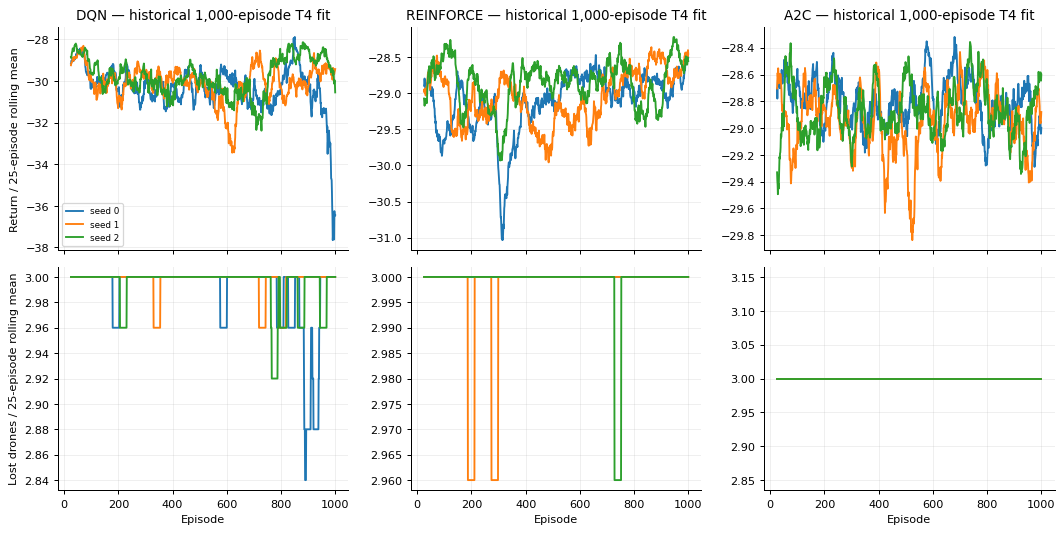

In [11]:
fig, axes = plt.subplots(2,3,figsize=(12,6),sharex=True)
for col, algorithm in enumerate(ALGORITHMS):
    for seed in range(3):
        h = pd.read_csv(ARCHIVES/'colab-2026-10-03/raw/validation20-v2'/algorithm/
                        f'seed-{seed}'/'training.csv')
        for row, metric in enumerate(['return','total_losses']):
            axes[row,col].plot(h['episode'],h[metric].rolling(25,min_periods=25).mean(),
                               label=f'seed {seed}')
    axes[0,col].set_title(f'{algorithm.upper()} — historical 1,000-episode T4 fit')
    axes[1,col].set_xlabel('Episode')
for ax in axes.flat: ax.grid(alpha=0.2)
axes[0,0].set_ylabel('Return / 25-episode rolling mean')
axes[1,0].set_ylabel('Lost drones / 25-episode rolling mean')
axes[0,0].legend(fontsize=7)
finish_plot(fig)

### dqn-rate-probe-2026-10-03

*Preserved dated record: [docs/experiments/dqn-rate-probe-2026-10-03/README.md](docs/experiments/dqn-rate-probe-2026-10-03/README.md). Statements and commands below describe that archived experiment, not new runs.*

## One-fit DQN learning-rate screen

This is a validation-only follow-up to the T4 failure diagnosis, not final held-out
evidence or a three-fit comparison. See [the report](docs/colab1000-results.md).
Each rate has one network seed (0), 200 episodes, training scenarios 0–199 and validation
5000–5004 every 20 episodes. All other environment and learning settings are identical.
Final and selected outcomes are both retained. The code is unchanged DQN, without a mask,
shield, reward change or modified target rule.

`summary.csv` aggregates scenarios; `comparison.csv` retains 30 per-scenario rows.
Each rate folder retains training/validation CSVs and complete config/runtime metadata.
`manifest.json` identifies the unchanged learning source by SHA-256. Source metadata records
the notebook/report edits as dirty; CPU PyTorch 2.5.1 and NumPy 2.3.5 differ from the T4 run.
Binary policy/replay files remain local, outside Git.

To reproduce the fits from the repo root, with the RL dependencies installed:

```python
import json
from dataclasses import replace
from pathlib import Path
from wild_drone.config import EnvConfig
from wild_drone.learning import TrainConfig, train

raw = json.loads(Path('configs/development.json').read_text())
env = EnvConfig(**raw['environment'])
settings = TrainConfig(**(raw['training'] | {
    'episodes': 200, 'seed': 0, 'device': 'cpu',
    'validation_seeds': tuple(range(5000, 5005)),
    'checkpoint_interval': 20, 'validation_interval': 20, 'progress_interval': 20,
}))
for rate in [0.0003, 0.0001, 0.00003]:
    train('dqn', env, replace(settings, learning_rate=rate),
          Path('runs/dqn-rate-reproduction') / f'lr-{rate:g}')
```

Use a fresh output directory for a new screen. The best score is the largest five-scenario
mean in `validation.csv`; final is the episode-200 mean. For `max_q` diagnostics, load the
corresponding policy, run deterministic validation trajectories, and record the maximum
of its 125 model outputs at each decision, then the maximum across those decisions/scenarios.
The learning-rate screen does not justify changing the default or running final test seeds.

### dqn-stability-2026-10-03

*Preserved dated record: [docs/experiments/dqn-stability-2026-10-03/README.md](docs/experiments/dqn-stability-2026-10-03/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Lower-rate DQN and Double DQN validation screen

All six fits completed the [predeclared 200-episode comparison](docs/dqn-stability-plan.md).
Neither method learned useful inspection/recharge coordination. The short validation
rollouts did not reproduce the excessive Q values seen in the original T4 run, but this
does not establish stability at 1,000 episodes, value calibration, or an RL advantage.

Both arms use learning rate 0.00003, training seeds 0/1/2, training scenarios 0–199,
validation scenarios 5000–5004, and otherwise identical development settings. Standard
DQN remains the default. The target-rule split is the only learning difference between
arms. Validation every 20 episodes selects over ten boundaries; the selected results
are biased. Final test scenarios 10000+ were not used.

Each fitted model is averaged over five scenarios before calculating mean and sample
SD across three fits. Baseline SD is across five scenarios, a different unit.

| Policy | Return mean ± SD | Freshness mean | Fleet losses mean | Blocked attempts mean |
|---|---:|---:|---:|---:|
| Greedy | −4.922 ± 0.588 | 0.313 | 0.000 | 0.000 |
| Planner | −5.024 ± 0.656 | 0.312 | 0.000 | 0.000 |
| Sweep | −12.142 ± 0.499 | 0.110 | 0.000 | 0.000 |
| Random | −28.337 ± 0.797 | 0.097 | 3.000 | 2.600 |
| Final DQN | −38.016 ± 6.901 | 0.052 | 3.000 | 43.800 |
| Selected DQN | −29.333 ± 0.886 | 0.068 | 3.000 | 3.600 |
| Final Double DQN | −32.548 ± 2.961 | 0.060 | 2.933 | 19.600 |
| Selected Double DQN | −26.863 ± 2.048 | 0.063 | 2.400 | 4.333 |

The Double DQN sample means are less negative, but the small fit count, shared validation
set, short training budget and selection bias do not justify declaring a winner. Both
final means are worse than random; all fits are far behind greedy. The selected policies
inspect little and frequently lose drones. A low TD loss does not mean a useful controller.

### Value and checkpoint checks

All 12 portable exports matched authoritative episode counts, metadata and exact tensors.
All 60 diagnostic mission returns, freshness, losses and collision counts exactly replayed
the corresponding comparison rows. Checkpoint hashes bind diagnostics to the verified bytes.

| Export group | Maximum observed Q | Bound violations / visited states |
|---|---:|---:|
| Final DQN | −0.0083 | 0 / 1,785 |
| Selected DQN | 1.0351 | 0 / 1,789 |
| Final Double DQN | 17.6289 | 0 / 1,854 |
| Selected Double DQN | 1.1835 | 0 / 2,056 |

The upper bound is `freshness_reward * sum(gamma**t for t in range(remaining_steps))`.
Inspection gain is at most one and other reward terms are nonpositive. Diagnostics test
the largest of all 125 Q values at each visited state against its remaining-horizon bound.
No violations in these 7,484 visited states cannot rule out failures elsewhere or later.
The positive final Q of 17.63 in Double DQN seed 1 deserves monitoring in longer fits.

Selected episodes for seeds 0/1/2 were 140/120/180 for DQN and 160/40/160 for Double DQN.
The last 100 training episodes had median Huber losses around 0.14–0.15 in all fits.
This is substantially different from the original high-rate T4 loss explosion, but that
older study also used a longer budget and different runtime. It is historical context,
not a matched rate-effect control. The earlier one-fit lower-rate screen also is not
included as an extra independent fit or required to reproduce an identical trajectory.

### Reproduction and provenance

The README's two `run_validation_pilot.py` commands and `diagnose_dqn.py` command reproduce
this protocol. Completed runs remain locally under `runs/dqn-stability-v3`; they can resume
with a larger total budget in a separately declared follow-up experiment. Binary training
states and policies are excluded from Git; verified hashes and raw records are retained.

The run launched from a dirty working tree based on `f312eecc`, using Python 3.12.14,
PyTorch 2.5.1 CPU and NumPy 2.3.5. Per-fit metadata records the observed revision/runtime.
`source-manifest.json` records hashes of the training/runtime/environment files in use.
The launch version of the runner is preserved in `source-launch/`: the final runner adds
a preflight guard against changing a study's fit roster, without changing learning.
Both arms ran concurrently in separate directories with one Torch thread per process;
elapsed times are not a CPU/GPU or target-rule throughput benchmark.

Records comprise 1,200 training rows, 300 periodic validation rows, two 50-row comparisons
(the baseline rows are duplicated between arms), and 60 diagnostic replay rows.
`archive-manifest.json` checksums the copied records. `per-fit.csv` averages diagnostic
metrics by variant, training seed and selection; `summary.json` then aggregates those
three fitted-model means, using sample SD (`ddof=1`). Its Q maxima and violation counts
are maximum/sum across the same rows. Baselines come from the comparison CSVs.

Next research work should diagnose exploration, repeated blocked commands, learned battery
return behaviour and value targets before a larger 40×40 study. A separately fixed longer
budget is needed to assess whether the lower rate remains stable. Reward changes, shields
and architectural changes should remain explicit ablations, not score-driven fixes.

### exploration-2026-10-03

*Preserved dated record: [docs/experiments/exploration-2026-10-03/README.md](docs/experiments/exploration-2026-10-03/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Return behavior and slower exploration: completed validation screen

Slower uniform exploration broadened replay coverage, but did not produce a useful
controller. Keep the original epsilon schedule. This is a short diagnostic experiment,
not a final generalisation result or a claim that all exploration strategies fail.

The [predeclared plan](docs/exploration-plan.md) fixes standard DQN, learning rate
0.00003, 200 episodes, three training seeds 0/1/2, scenarios 0–199 for training,
validation scenarios 5000–5004 every 20 episodes, and unchanged development mechanics.
The sole learning difference is epsilon decay over 10,000 versus 40,000 steps.
Both arms were trained fresh. Neither final test scenarios nor the original T4 archive
were changed or used for tuning in this phase.

### What the behavior trace reveals

Before this experiment, the previous lower-rate DQN/Double DQN exports were replayed
with observational diagnostics: 60 fitted-policy missions plus 20 control missions.
Final DQN averaged 102.6 wall commands per mission; final Double DQN averaged 126.1.
These differ from collision blocks (43.8 and 19.6): boundary commands are clamped
by the kernel and still cost movement energy, but are not counted as collisions.
Repeated unchanged moves are not successful inspection coordination.

A necessary return-energy bound is Manhattan distance to base times move cost.
We classify live, away-from-base states with margin 0 through three move costs as
critical, using a 0.0001 battery-unit tolerance. Negative margins imply insufficient
energy for even the shortest return path. Nonnegative margins do not guarantee safety;
collisions and hovering can consume more. This diagnostic does not intervene in actions.

For the previous final policies, actual distance-reducing moves occurred in 50/226
critical drone steps for DQN and 21/183 for Double DQN. Greedy and sweep moved toward
base in every observed critical drone step. They use explicit battery-aware proposal
rules; these rules are part of their conventional controllers and are not supplied
to RL. The all-stay diagnostic control returned −15.559, lost no drones and inspected
little. Its survival alone is not coordination; it still outscored the final RL policies.

[Battery versus necessary return energy in the first declared example mission](docs/experiments/exploration-2026-10-03/return-energy.svg)

This is the final 10,000-step-decay DQN policy, seed 0, scenario 5000, selected as the
first diagnostic job rather than by inspecting outcomes. Each drone eventually falls
below the necessary return-energy bound and is lost. The CSV records the final loss
transition as well as pre-action states; lost drones are excluded from later live counts.

### Matched experiment results

Average each fitted model over its five scenarios, then compute mean and sample SD
over three fits. Selected checkpoints maximise scenario-mean return over ten validation
boundaries and are biased. Baseline SD is across five scenarios, a different unit.

| Policy | Return mean ± fit SD | Freshness mean | Losses mean | Collision blocks mean | Wall commands mean |
|---|---:|---:|---:|---:|---:|
| Final 10k decay | −38.016 ± 6.901 | 0.0524 | 3.000 | 43.800 | 102.600 |
| Final 40k decay | −37.904 ± 5.019 | 0.0449 | 3.000 | 42.133 | 124.333 |
| Selected 10k decay | −29.333 ± 0.886 | 0.0682 | 3.000 | 3.600 | 126.267 |
| Selected 40k decay | −27.699 ± 3.984 | 0.0656 | 2.533 | 6.000 | 141.267 |

Greedy returned −4.922 ± 0.588 with freshness 0.3131 and no losses. Random returned
−28.337 ± 0.797 with all three drones lost. Every final learned-policy mission in both
arms lost the entire fleet. The 0.112 difference in final mean return does not justify
a performance claim. The selected-policy difference is also insufficient to claim
improvement, particularly after checkpoint selection on these same five scenarios.

The mean per-fit fraction of critical drone steps with an actual distance-reducing
return move was 19.2% for final 10k decay and 14.1% for final 40k decay. For each fit,
this ratio pools opportunities over its five missions; the three fit ratios are then
averaged. This differs from pooling opportunities across every fitted model. Mere
commands toward base can be blocked, so actual and intended counts are both retained.

#### Replay coverage and value checks

| Final retained 2,000-transition buffer statistic, mean over fits | 10k decay | 40k decay |
|---|---:|---:|
| Distinct joint-action labels | 103.0 | 125.0 |
| Live pre-state fraction with negative return margin | 17.07% | 14.07% |
| Transitions with a safe return | 17.0 | 32.0 |
| Transitions with battery increase from charging | 5.33 | 11.00 |
| Last action's random-selection probability | 0.050 | 0.519 |
| Schedule-implied expected random fraction over completed steps | 0.269 | 0.760 |

Replay statistics describe the final retained buffer, not complete training history.
Action-label coverage does not imply coverage of coordinated trajectories. Safe-return
and charging counts are transitions containing at least one such event, not drone-event
counts. Expected epsilon selections are calculated probabilities, not observed counts
of random branches. Broader coverage and more return/charging transitions did not
translate into safer deterministic final policies in this experiment.

| Checkpoint group | Maximum visited Q | Upper-bound violations / decisions |
|---|---:|---:|
| Final 10k decay | −0.0083 | 0 / 1,785 |
| Selected 10k decay | 1.0351 | 0 / 1,789 |
| Final 40k decay | 8.2019 | 0 / 1,448 |
| Selected 40k decay | 6.5959 | 11 / 2,046 |

The bound uses the remaining mission horizon and the maximum one-step freshness reward.
Violations in the selected 40k policies occur near the horizon: nine visited states
for seed 0 and two for seed 2. Maximum excess is 1.9945 battery-independent reward units.
These are smaller than the original high-rate T4 Q explosion, but still contradict a
claim of calibrated values. Lack of violations in another group also does not prove
calibration or long-run stability. Selected episodes were 140/120/180 (10k) and
160/100/160 (40k), in seed order.

### Integrity and reproduction

All 12 new exports matched authoritative metadata and exact model tensors. All 60
new fitted-policy diagnostic mission returns, freshness, losses, returns and completed
charges exactly match comparison records. The three fresh 10k controls reproduced
the previous standard-DQN model tensors exactly. The previous controls are retained
as reproducibility evidence and are not counted as additional independent fitted models.

The new runs contain 1,200 training rows, 300 periodic validation rows and two 50-row
comparison files, including duplicated baseline rows. Each diagnostic study contains
80 missions, six final-buffer records and one example trace. `per-fit.csv` aggregates
mission metrics by fit/selection; `summary.json` calculates sample SD with `ddof=1`.
Q maxima/violations aggregate by maximum/sum, and critical-return ratios use the
within-fit opportunity pooling described above. `archive-manifest.json` checksums
46 copied raw, diagnostic, provenance and chart records.

Run from the repository root:

```bash
python scripts/run_validation_pilot.py --episodes 200 --training-seeds 0 1 2 --algorithms dqn --learning-rate 0.00003 --no-double-dqn --epsilon-decay-steps 10000 --out runs/exploration-v4/default
python scripts/run_validation_pilot.py --episodes 200 --training-seeds 0 1 2 --algorithms dqn --learning-rate 0.00003 --no-double-dqn --epsilon-decay-steps 40000 --out runs/exploration-v4/slow
python scripts/diagnose_behavior.py runs/exploration-v4/default/dqn/seed-* runs/exploration-v4/slow/dqn/seed-* --out runs/behavior-v4/exploration
python scripts/plot_return_energy.py --trace runs/behavior-v4/exploration/example-trace.csv --protocol runs/behavior-v4/exploration/protocol.json --out runs/behavior-v4/exploration/return-energy.svg
```

Python 3.12.14, PyTorch 2.5.1 CPU and NumPy 2.3.5 were used. Each process used one
Torch thread; arms ran concurrently in separate folders. Training times total 741.3
seconds across fits, including periodic validation/persistence, and are not a throughput
benchmark. Source hashes match the training files in the final implementation; per-fit
metadata records local revisions `300af7e`/`d33abba` and clean/dirty status during execution.
The launch manifest records the preceding base revision and uncommitted changes at launch.
Binary checkpoints remain under ignored local run folders; the repository contains
verified hashes, CSV/JSON records and the diagram rather than binary training states.

These diagnostics locate recurrent command/energy failures. They do not prove a single
architectural root cause. Rate, target-rule and uniform-exploration tweaks have not
solved coordination in the tested budgets. The next design discussion should compare
explicitly ablated action/value representations or a separately labeled demonstration
warm start, with plain RL controls preserved. A larger grid or final held-out claim
would be premature without a useful, reproducible validation policy.

### imitation-2026-10-03

*Preserved dated record: [docs/experiments/imitation-2026-10-03/README.md](docs/experiments/imitation-2026-10-03/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Greedy imitation capability probe: completed validation diagnostic

The unchanged network fits demonstrated decisions, including battery-return and charging
examples, but does not generalize into a useful controller under this budget. Final models
agree with 96.4% of training joint actions and 9.6% of held-out teacher joint actions.
Every final and selected autonomous validation mission loses all three drones. This is a
supervised diagnostic, not evidence of successful RL, a warm-start experiment, or a proof
that the architecture cannot generalize.

### Fixed protocol

The [predeclared plan](docs/imitation-probe-plan.md) uses the unchanged 20×20 development
environment, 160-step horizon, nine spatial channels, 24-vector input, CNN16/32 plus dense128
encoder and 125 joint-action outputs. Collect real GreedyPolicy trajectories on scenarios
0–19 (3,200 states) and 5000–5004 (800 states). All three fits share these datasets and use
seeds 0/1/2, 100 epochs, batch size 64, Adam rate 0.001 and gradient norm clip 0.5.
There are 5,000 optimizer updates per fit. Ordinary cross-entropy uses only training labels.
There is no critical-state oversampling, class weighting, action shield, RL fine-tuning or
change to simulator physics, rewards, RL trainers or defaults. Final test scenarios remain unused.

Validation label metrics are measured every ten epochs. Selected checkpoints maximize
validation joint-action agreement, with the earliest measured epoch retained on ties;
untrained initialization is ineligible. Selected epochs are 40/90/50, with agreement
9.25%/9.875%/11.625%. Their estimates are subject to selection on the same five scenarios.
Each initial, final and selected model independently controls five full validation missions;
the teacher controls five more, totaling 50 missions.

### Fitting and generalization

Numbers below are means over three fits. All teachers remain alive. Training data contain
623 critical drone states and 1,717 charging drone states; validation contains 134 and 488.
Critical means alive and away from base, with battery minus Manhattan return cost between
zero and three move costs. These are observed subset counts, not independently sampled trials.

| Final teacher-state metric | Training | Validation |
|---|---:|---:|
| Exact joint-action agreement | 96.38% | 9.63% |
| Per-live-drone command agreement | 98.39% | 40.10% |
| Critical joint-action agreement | 97.32% | 4.84% |
| Critical per-drone command agreement | 98.66% | 34.83% |
| Critical proposed command reduces base distance | 99.41% | 46.02% |
| Hold command while at base needing charge | 99.84% | 76.64% |
| Cross-entropy | 0.145 | 15.810 |

[Training and held-out teacher-state agreement across all three fits](docs/experiments/imitation-2026-10-03/label-agreement.svg)

Training agreement rises while held-out agreement stays low and final cross-entropy is high.
The most common training label is all-stay (action 0): 5.34% of training states and 10.0%
of validation states. Thus a constant all-stay predictor reaches 10.0% joint agreement on
these teacher states, compared with the final models' 9.63% mean. This is a descriptive
label-frequency reference; survival or label agreement alone does not establish coordination.
Training covers all 125 labels, validation 89. Labels record one deterministic greedy choice;
disagreement can include equally good alternatives and is not itself a reward optimality test.

The training return/charging subsets demonstrate that the present network can fit many such
examples under direct supervision. That does not show that the RL objective or its visited
state distribution can learn them. Poor held-out fitting is already present on teacher
trajectories; additional drift when the model controls the fleet could compound failures.
This study does not isolate that drift or prove a single cause. The sequential-distribution
issue is discussed by [Ross, Gordon and Bagnell (2011)](https://proceedings.mlr.press/v15/ross11a.html);
this probe does not implement DAgger.

### Autonomous missions

For fitted policies, first average the five missions for each model, then compute mean and
sample SD over three fits. Baseline SD is over five scenarios, a different unit.

| Policy | Return mean ± fit SD | Freshness mean | Losses mean | Wall commands mean | Collision blocks mean |
|---|---:|---:|---:|---:|---:|
| Untrained network | −39.175 ± 10.413 | 0.0451 | 2.867 | 136.467 | 51.200 |
| Final imitation | −27.461 ± 0.288 | 0.1048 | 3.000 | 37.667 | 1.267 |
| Selected imitation | −28.851 ± 1.361 | 0.1012 | 3.000 | 49.467 | 7.733 |
| Greedy teacher | −4.922 ± 0.588 (scenario SD) | 0.3131 | 0.000 | 0.000 | 0.000 |

Final imitation models execute distance-reducing return moves in 31.7% of critical drone
steps on average across fits; selected models execute 30.7%, versus the teacher's pooled
100%. For each fit, pool opportunities across its five missions before computing the ratio.
These executed-move fractions differ from proposed commands on teacher-generated states.
Final policies average 0.333 safe returns and 0.133 completed charges per mission; the teacher
averages 3.2 of each. All 15 final and all 15 selected missions lose the full fleet.

[Battery and necessary return energy in the first declared final-policy mission](docs/experiments/imitation-2026-10-03/return-energy.svg)

The example is final seed 0 on scenario 5000, chosen by runner order rather than by its outcome.
The recorded final transition is included. The distance-based energy requirement is necessary,
not sufficient: blocked moves or hovering can consume additional battery. Wall commands are
clamped and consume energy; they differ from collision blocks. Instrumented decision times
include tracing overhead and should not be used as policy throughput benchmarks.

### Records and reproduction

Run from the repository root with the CPU PyTorch and project dependencies installed:

```bash
python scripts/run_imitation_probe.py --out runs/imitation-v5
python scripts/plot_return_energy.py --trace runs/imitation-v5/example-trace.csv --protocol runs/imitation-v5/protocol.json --out runs/imitation-v5/return-energy.svg
```

Use a fresh folder if that output already exists; this diagnostic has no resume interface.
Python 3.12.14, PyTorch 2.5.1 CPU and NumPy 2.3.5 were used with one Torch thread. Fitting,
label evaluation and persistence totaled 69.9 seconds across the three models; this excludes
autonomous mission evaluation and teacher collection and is not a throughput benchmark.
Per-fit metadata records clean local source revision `1770c33dfb41e121541adea7e86c4643aab07fa3`.
Protocol source hashes bind the implementation and predeclared plan independently of git history.

`raw/` preserves 66 label-metric rows, 50 autonomous mission rows, one full example trace,
per-fit metadata, checkpoint manifests and summaries, the root dataset/source protocol and
fit timings. `per-fit.csv` and `summary.json` preserve the aggregation; `archive-analysis.py`
regenerates them and the label plot from archived raw records. `archive-manifest.json` binds
raw and derived artifacts. Binary datasets and nine checkpoints remain in ignored local runs;
byte and semantic dataset hashes, and exact checked checkpoint hashes, are retained in the repo.
Checkpoints use an explicit supervised format and cannot be silently evaluated as DQN policies.

The next useful experiment is a separately declared test of broader demonstration coverage
and labels on states reached by the learner, with this plain imitation result kept as its
control. Compare held-out decision fitting and autonomous coordination before adding an RL
warm start or changing architecture. More GPU time or a larger grid alone is not supported
as a remedy by these results.

### action-2026-10-04

*Preserved dated record: [docs/experiments/action-2026-10-04/README.md](docs/experiments/action-2026-10-04/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Conditional action learning: completed diagnostic

The fixed final 20,000-update comparison returns -28.213 ± 0.816 for
the original joint head and -27.811 ± 1.385 for the conditional head.
Whole-fleet losses are 15/15 and
15/15 missions respectively. These are autonomous
learners; no teacher or action override runs during the flights. The conditional recipe
modestly improves label fitting and mean return, but does not establish useful autonomous
competence. It is retained as a diagnostic and is not promoted into RL defaults or scaled.

### Comparison and competence gate

The [predeclared protocol](docs/action-protocol.md) changes the output-head recipe while
retaining the original observation transform, nine map channels, 24-value vector,
convolutional body and 128-unit encoder. Within each seed, initial encoder tensors and
training sampler seeds match. The `joint` arm is the exact original FleetNetwork with one
125-way head, 127,677 parameters. The `conditional` arm models
p(a0|state), p(a1|state,a0), p(a2|state,a0,a1) in fixed drone order 0/1/2. Its first head is
linear 128→5; later heads concatenate preceding command one-hots with encoder features,
then use a 64-unit ReLU layer and five logits. It has 130,319
parameters. Head initialization, depth and parameter count differ; this is a complete
recipe comparison, not an equal-capacity factorization ablation. Unused original-head
parameters are removed. Neither representation, reward nor environment physics changes.

Conditional fitting minimizes the sum of three cross-entropies using preceding teacher
commands from the same labeled joint action. This is complete joint negative log
likelihood, without division by three. Deployment enumerates every combination and
chooses global argmax of summed conditional log probabilities. These commands form one
simultaneous fleet action; the factorization does not introduce extra simulator steps.
No sequential greedy decoder, feasibility filtering, safety override, privileged state
or teacher execution is added. Tests verify normalized probabilities, complete action
ordering, joint-MAP behavior and equality of sparse teacher-context/full-joint loss and
gradients. The original-head fitter matches the existing fixed fitter on a same-runtime
small test. This diagnostic is supervised imitation, not an RL advantage.

Before the larger study, both arms fit only world 0 (160 Greedy states), with three seeds,
2,000 updates each and unchanged 20×20 physics. All six fits reach 100% training joint
agreement and exactly reproduce Greedy's training-world flight: return −5.0201, freshness
0.3042, zero drone losses, three safe returns and three completed charges. All seven
training-world flights and 65 validation flights are preserved separately under `sanity/`.
Both arms' 15 final validation flights lose the fleet. The gate establishes known-trajectory
competence only; its success does not establish transfer or unseen-state recovery. No
successful world or checkpoint was selected after seeing outcomes. This gate was fixed
before fitting, and the broader comparison started only after it passed.

The larger study gives all six fits the same 15,864 real teacher states from worlds 0–99
and 800 teacher validation states on worlds 5000–5004. Both semantic dataset identities
match prior full-corpus studies. Keep Greedy's failures and all labels; do not manufacture
successful transitions. Six fits use seeds 0/1/2, Adam 0.001, uniform batch 64 with replacement,
norm clip 0.5, five continuous rounds of 4,000 updates. No curriculum, recovery collection,
class weighting or new inputs belong to this arm comparison. Physics remain 20×20,
horizon 160, three drones and one charger. Final worlds 10000+ remain unused.

### Autonomous missions and teacher decisions

Each fit averages its five missions before mean/sample SD over three fits. Checkpoints
within a fit are nested, not independent fitted models. Whole-fleet losses count all
three drones lost. Greedy is a shared five-world reference with scenario SD, a different
unit. Reused development validation supports exploratory tuning, not final generalization,
significance or a universal claim about conditional heads.

| Updates | Joint return ± fit SD | Conditional return ± fit SD | Joint fleet losses | Conditional fleet losses |
|---|---:|---:|---:|---:|
| 4,000 | -29.795 ± 2.325 | -27.949 ± 0.974 | 15/15 | 15/15 |
| 8,000 | -27.595 ± 1.418 | -28.372 ± 0.973 | 15/15 | 15/15 |
| 12,000 | -27.302 ± 0.518 | -27.647 ± 0.763 | 15/15 | 15/15 |
| 16,000 | -27.998 ± 1.123 | -26.913 ± 0.936 | 15/15 | 14/15 |
| 20,000 | -28.213 ± 0.816 | -27.811 ± 1.385 | 15/15 | 15/15 |
| Agreement-selected | -29.818 ± 2.378 | -27.803 ± 1.032 | 15/15 | 15/15 |
| Greedy reference | -4.922 ± 0.588 (scenario SD) | Shared reference | 0/5 | Shared reference |

The paired final conditional-minus-joint return difference is
0.402 ± 1.979 over three seed pairs. Intermediate budget
results remain measurements, not retrospectively validated best controllers.

| Final autonomous metric | Joint | Conditional | Greedy |
|---|---:|---:|---:|
| weighted freshness | 0.1028 | 0.1154 | 0.3131 |
| total losses | 3.0000 | 3.0000 | 0.0000 |
| safe returns | 0.4667 | 0.5333 | 3.2000 |
| charge completions | 0.0667 | 0.1333 | 3.2000 |
| critical return move fraction | 0.2780 | 0.2071 | 1.0000 |

Actual critical return-move fractions pool opportunities within each fit before averaging
fits; the Greedy fraction pools its five worlds. They measure distance-reducing executed
motion, including blocking effects, separately from teacher-state proposals:

| Final teacher-state metric | Joint | Conditional |
|---|---:|---:|
| train joint accuracy | 86.82% | 88.74% |
| validation joint accuracy | 14.79% | 17.79% |
| validation live command accuracy | 44.08% | 47.08% |
| validation critical command accuracy | 35.82% | 36.82% |
| validation critical toward base command fraction | 46.02% | 49.50% |
| validation charging hold fraction | 90.64% | 96.99% |

Teacher agreement targets one heuristic label including ties; it is not reward optimality.
Both arms use the same dataset here. Selected rounds are [1, 2, 5]
for joint and [3, 3, 1] for conditional, maximizing validation
joint agreement over trained rounds 1–5 with earliest ties and initialization ineligible.
Selection never uses autonomous return and remains biased by repeated validation.

### Decision and next correction

At 20,000 updates, training joint agreement is
86.8% versus
88.7%;
validation agreement is
14.8% versus
17.8%.
Changing how simultaneous commands are modeled is insufficient under this fixed recipe.
The small mean-return difference varies across seed pairs; it does not establish a reliable
advantage. Both final and agreement-selected arms lose every fleet. Conditional flights
complete only 0.133 charges per mission,
versus 3.2 for Greedy, and execute a smaller
critical distance-reducing move fraction than the joint arm despite better agreement on
teacher-state return proposals. Better teacher-state classification does not ensure safe
behavior on the states the learner reaches.

The next correction should isolate return-and-recharge generalization in a small task,
with separately held-out drone/base positions and battery levels, before combining it with
inspection and fleet coordination. A local, drone-centered representation is a testable
candidate, not a demonstrated cause or fix. Require autonomous return and completed
recharge across those held-out configurations, then useful full-fleet inspection, before
spending more on data, training duration or the 40×40 main experiment. The observation
contains the required positions and energy; these results do not identify a unique reason
why the network fails to use them reliably. No new Colab GPU run is needed for this decision.

[Decision fitting and autonomous return](docs/experiments/action-2026-10-04/comparison.svg)

[Declared final conditional flight: fit 0, world 5000](docs/experiments/action-2026-10-04/return-energy.svg)

The example is fixed by runner order and includes the terminal transition. Decision times
include recording overhead, not uninstrumented throughput.

### Integrity and reproduction

```bash
python scripts/run_action_probe.py --training-scenarios 0 --budgets 2000 --updates-per-round 2000 --out runs/action-sanity-v11
python docs/experiments/action-2026-10-04/sanity/check-trained-world.py
python scripts/run_action_probe.py --out runs/action-v11
python docs/experiments/action-2026-10-04/archive-analysis.py
python docs/experiments/action-2026-10-04/replay-results.py runs/action-sanity-v11
python docs/experiments/action-2026-10-04/replay-results.py runs/action-v11
```

Install project/PyTorch dependencies and run from repository root into fresh folders;
there is no resume interface. Replay requires the generated binary datasets/checkpoints
in those run folders; the archive contains their identities rather than their binaries. Python 3.12.14, PyTorch 2.5.1 CPU, NumPy 2.3.5 and one Torch
thread were used. Main fitting, round metrics and persistence total 898.6
seconds across six fits, excluding shared collection and autonomous evaluation. These
instrumented timings are not a throughput benchmark.

Main metadata bind clean source revision `b8f4d2c61cf99e85c1567fbdd3c6571195d94907`;
sanity metadata bind `e7a8931c134d3543f624e2edcd2625d12d1e36c8`. The sole runner change
between them corrects the completion-log word from Representation to Action. Original
runner bytes and a hash/transform audit are preserved under sanity/raw; training and
decoding sources are identical. Protocol source hashes independently bind exact files,
including when publication commits differ. Older trained weights may differ across
host runtimes, so historical fits are not current paired replicates.

All 185 main missions, including five baseline rows, are persisted, with 48 checkpoint identities,
two datasets and 72 label rows. Sanity contains 24 checkpoints, two datasets, 24 label rows,
65 validation and seven trained-world missions. Check source, model/shared-encoder,
progress, metadata and data identities; recompute labels and all non-timing mission/trace
fields. Replay verified 4,995 main mission fields and 4,560 main trace fields, plus
1,755 sanity validation fields, 189 training-world fields and 4,560 sanity trace fields.
All 96 label rows were recomputed from the bound checkpoints. Earliest selection and
final export identities are verified. Four ZIP members
preserve original collection CSV bytes. collection-members.json binds members, and
manifest.json binds raw/derived artifacts. archive-analysis.py regenerates numeric
aggregation and the comparison figure. Binary datasets/checkpoints remain ignored;
their byte/semantic hashes preserve provenance. Original RL loaders reject this explicitly
supervised checkpoint format; earlier reports and RL defaults remain intact.

### coverage-2026-10-04

*Preserved dated record: [docs/experiments/coverage-2026-10-04/README.md](docs/experiments/coverage-2026-10-04/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Coverage and learner-state labeling: completed supervised screen

Broader Greedy trajectories improve held-out teacher-state agreement, but do not produce
useful autonomous coordination at this update budget. Final joint agreement is 10.46% for
the fixed-data control, 15.25% for broader teacher data and 8.62% for learner-state labeling.
44 of 45 final flights lose all three drones; one learner-state flight retains one drone.
All 45 selected flights lose the full fleet. This is supervised imitation, not successful
RL, and does not establish that all dataset aggregation methods or architectures fail.

### Fixed comparison

The [predeclared protocol](docs/coverage-probe-protocol.md) keeps the 20×20 development
simulator, 160-step horizon, full observation transform, existing FleetNetwork and 125 joint
outputs. All arms share 3,200 initial Greedy-labeled states from scenarios 0–19. Three fit
seeds 0/1/2 each receive five rounds of 1,000 Adam updates, learning rate 0.001, gradient clip
0.5 and batches of 64 sampled uniformly with replacement. Every fit receives 320,000 label
presentations; the optimizer and independent sampler continue across rounds. There is no
weighting, architecture change, shield, battery rescue, reward change or RL fine-tuning.

| Arm | Added trajectories before rounds 2–5 | Final training labels per fit |
|---|---|---|
| fixed | None | 3,200 / 3,200 / 3,200 |
| teacher | Greedy executes scenarios 20–39, 40–59, 60–79, 80–99 | 15,864 / 15,864 / 15,864 |
| dagger | Previous-round learner executes those same batches; Greedy labels visited pre-action states | 10,881 / 10,485 / 10,268 |

Initial and first-round model tensors are identical across arms within each fit seed.
The matched `fixed` arm uses sampling with replacement; it is a new control, not an exact
reproduction of the preceding probe's shuffled-epoch sampling. Previous fits are not pooled
as additional independent models. Added learner missions often terminate early, so matching
updates does not match oracle queries, state coverage or teacher information. The shared
initial data are collected once and reused by all fits.

The aggregation arm is a bounded DAgger variant: after teacher initialization, collection
uses only learner actions (beta zero), retaining all labels and continuing the optimizer.
It does not solve an exact no-regret optimization problem, and no theoretical guarantee is
claimed. [Ross, Gordon and Bagnell (2011)](https://proceedings.mlr.press/v15/ross11a.html) provide
the primary dataset-aggregation motivation.

Metrics use 800 Greedy teacher states on scenarios 5000–5004 after each round and at
initialization. Those labels never enter updates or added trajectory collection. Selection
maximizes validation joint agreement over rounds 1–5, retaining earliest ties. Selected
rounds are 3/4/4 (fixed), 5/5/5 (teacher), and 1/3/4 (dagger). Autonomous evaluation covers
every trained round plus selected checkpoints, with five shared teacher baseline flights:
275 missions. Selected teacher checkpoints have the same tensors as the final models;
they are duplicated records of the same policies, not additional independent fits.
Final test scenarios remain unused; these repeatedly used scenarios support exploratory
validation, not a final generalization claim.

### Teacher-state decisions

Means below are over three fits. Training joint agreement uses each arm's own final dataset;
those training distributions differ and their accuracies are not directly comparable.
Validation uses the same 800 states for every arm.

| Final metric | fixed | teacher | dagger |
|---|---:|---:|---:|
| Training joint agreement | 94.80% | 46.86% | 69.30% |
| Validation joint agreement | 10.46% | 15.25% | 8.62% |
| Validation live-drone command agreement | 39.76% | 44.35% | 39.72% |
| Validation critical-drone command agreement | 30.85% | 29.85% | 32.09% |
| Validation critical command reduces base distance | 44.28% | 42.79% | 43.03% |
| Validation hold at base when needing charge | 75.89% | 93.17% | 77.53% |
| Validation cross-entropy | 15.327 | 4.881 | 8.137 |

Validation contains 134 critical drone states and 488 charging drone states. The critical
subset comprises alive, away-from-base states with battery minus Manhattan return cost
between zero and three move costs. Proposed commands on these teacher states are separate
from executed moves in autonomous flights. Joint labels record one deterministic Greedy
choice; disagreement can include equally good alternatives and is not a reward-optimality test.
An all-stay predictor agrees with 10.0% of validation joint labels. Broader teacher data
improves overall agreement, charging holds and cross-entropy, while critical-return decisions
remain weak. Its lower training agreement is consistent with less fitting of a larger dataset
under the same update budget; this study does not establish convergence or calibrated confidence.

[Decision agreement and autonomous return across rounds](docs/experiments/coverage-2026-10-04/comparison.svg)

Lines average three fits; shading is sample SD across fits. Each autonomous return first
averages five missions within the fit. The teacher reference is its five-scenario mean.
There is no uncertainty band or performance guarantee for that horizontal reference.

### Autonomous flights

For fitted policies, average scenarios within each fit before computing mean and sample SD
across the three fits. Teacher baseline SD is across five scenarios, a different unit.

| Final policy | Return mean ± fit SD | Freshness mean | Losses mean | Wall commands mean | Collision blocks mean |
|---|---:|---:|---:|---:|---:|
| fixed | −27.635 ± 0.413 | 0.0987 | 3.000 | 43.000 | 1.067 |
| teacher | −27.765 ± 0.319 | 0.0979 | 3.000 | 63.933 | 1.467 |
| dagger | −27.081 ± 0.449 | 0.0975 | 2.933 | 55.867 | 0.133 |
| Greedy baseline | −4.922 ± 0.588 (scenario SD) | 0.3131 | 0.000 | 0.000 | 0.000 |

The paired final-return differences, using the same fit seeds and validation missions, are
−0.130 ± 0.095 for teacher minus fixed and +0.554 ± 0.247 for dagger minus fixed (sample SD
across three seed pairs). The latter is a small measured improvement in return, but still
leaves nearly the whole fleet lost and inspection freshness far below Greedy. It does not
establish a useful controller, an RL advantage or general performance superiority.
Selected returns are −27.765 ± 0.675 (fixed), −27.765 ± 0.319 (teacher), and
−27.450 ± 0.316 (dagger). Selection uses teacher-state agreement, not autonomous return,
and the selected estimates remain biased by reuse of validation scenarios.

Mean within-fit fractions of critical opportunities with an actual distance-reducing return
move are 43.8%, 17.2% and 31.2% for fixed/teacher/dagger, versus the baseline's pooled 100%.
Pool opportunities across a fit's five missions before averaging those three fit ratios.
Mean completed charges are 0, 0 and 0.067 per mission; Greedy completes 3.2. Lower collision
counts or partial survival do not demonstrate sustained inspection/recharge coordination.

[First declared final dagger-policy mission, seed 0 and scenario 5000](docs/experiments/coverage-2026-10-04/return-energy.svg)

The example is chosen by runner order, includes the terminal transition, and shows the
necessary distance-based return-energy bound. Nonnegative margins do not guarantee safety:
hovering and blocked moves can consume more battery. Wall commands are clamped and cost
energy; they differ from collision blocks. Decision times include diagnostic overhead and
are not uninstrumented throughput measurements.

### What the added trajectories contain

Added Greedy trajectories contain 12,664 labels per fit, 2,411 critical and 6,973 charging
drone states. Their datasets and audits are deterministic duplicates across fit seeds,
not independently sampled teacher corpora. They contain 42 unreachable live-drone states
(0.11% of 37,992 live-drone states). Greedy terminates early with full fleet loss on added training scenarios 20 and 98
(step 92 in each), even though it loses no drones on the five validation scenarios.

The three learner collections add 7,681/7,285/7,068 labels. Of their live-drone states,
16.63%/16.18%/15.83% already have negative necessary return margins. Their critical drone-state
counts are 933/1,036/898; charging counts are only 133/60/87, compared with 6,973 in the teacher
collection. These counts exclude the shared initial dataset and describe collection, not
independent experimental trials. No synthetic initial states or post-termination states are used to manufacture recovery
examples; records contain real pre-action states only.

This evidence shows that the tested learner collection supplies few successful charging
examples and many states already below a necessary return bound. It motivates examining
collection quality and fitting budget, but does not isolate either as the cause of failure.
Greedy supplies conventional heuristic labels and can fall back to all-stay when its proposal
set is empty; it is not an optimal recovery oracle. All-stay labels are logged, but those
counts alone do not identify fallback occurrences.

### Integrity and reproduction

```bash
python scripts/run_coverage_probe.py --out runs/coverage-v6
python scripts/plot_return_energy.py --trace runs/coverage-v6/example-trace.csv --protocol runs/coverage-v6/protocol.json --out runs/coverage-v6/return-energy.svg
```

Run from the repository root after installing project/PyTorch dependencies. Use a fresh
folder if the output exists; this diagnostic has no resume interface. Python 3.12.14,
PyTorch 2.5.1 CPU and NumPy 2.3.5 were used with one Torch thread. Fitting, round metrics,
persistence and added collection total 237.7 seconds across nine fits; this excludes shared
initial/validation collection and autonomous evaluation and is not a throughput benchmark.
All fit metadata record clean local source revision `2eece0127de31d4e63e29ec5775d260ff9e328fc`.
The protocol binds exact source hashes independently of the eventual remote commit history.

`raw/` preserves 108 label-metric rows, 275 flight rows, per-fit metadata, dataset/checkpoint
manifests, collection summaries, timing and one full example trace. Seven `collection-records.zip`
files preserve the 26 original collection CSVs without changing their bytes; `collection-members.json`
binds member hashes and locations. `per-fit.csv`, `per-round.csv` and `summary.json` preserve
aggregation; `archive-analysis.py` regenerates these and the comparison chart from raw records.
The archive manifest binds raw and derived artifacts. All 26 binary datasets and 72 checkpoints
remain in ignored local run folders; verified byte/semantic/model hashes stay in the repo.
Initial and first-round tensor identities, selected-round identity, and final-round identity
are checked. The coverage format is explicitly supervised and rejected by ordinary RL loaders.
Earlier experiment records and plain RL defaults are preserved.

Broader teacher coverage improves some held-out decisions but autonomous return coordination
remains unresolved. The next bounded question should test fitting more of this broader corpus
and inspect whether battery-return decisions benefit, before treating demonstration weights as
an RL initialization. Changes to state/action representations or safer collection can then be
explicitly ablated if supervised fitting still fails to produce useful validation flights.
Larger grids or final test reporting would be premature at this stage.

### fitting-budget-2026-10-04

*Preserved dated record: [docs/experiments/fitting-budget-2026-10-04/README.md](docs/experiments/fitting-budget-2026-10-04/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Fixed-corpus fitting budget: completed supervised diagnostic

Four times as many updates does not fix fleet-return coordination. At 20,000 updates,
all 15 autonomous validation missions lose all three drones, with mean return −27.807
versus Greedy's −4.922. Training joint-action agreement rises from 46.38% to 85.39%,
while validation agreement falls from 16.83% to 14.67%. More fitting of this corpus
improves training decisions without producing a useful autonomous controller.

### Controlled comparison

The [predeclared protocol](docs/fitting-budget-protocol.md) supplies the complete Greedy
corpus on training scenarios 0–99 from the first update: 15,864 real pre-action states,
including 3,034 critical and 8,690 charging drone states. Greedy loses the fleet on training
scenarios 20 and 98 at step 92; no battery restoration or post-termination labels are added.
Validation contains 800 Greedy states from scenarios 5000–5004, including 134 critical and
488 charging drone states. Every fit uses the same training and validation datasets.

Three seeds 0/1/2 train the existing FleetNetwork and 125 joint-action outputs, with unchanged
observations, 20×20 development physics and 160-step horizon. Adam uses learning rate 0.001,
batch size 64 sampled uniformly with replacement and gradient norm clip 0.5. Optimizer and
sampler state continue for twenty rounds of 1,000 updates. Budgets 5k/10k/15k/20k are nested
checkpoints of each fit, not twelve independently trained models. No masks, shields, new
collection, weighting, reward change or RL updates are included.

The original agreement-selected exports remain separate: maximum validation joint agreement
among rounds 1–20, earliest ties, initialization ineligible. Selected rounds are 4/1/2 for
seeds 0/1/2. Selection uses teacher-state agreement, not autonomous return. The 5k control
receives all data upfront, unlike the earlier progressive teacher arm; historical fits
are context, not additional matched replicates. Final test scenarios 10000+ remain unused.

### Decisions and autonomous missions

Each fitted policy is evaluated on the same five validation missions. Returns first average
those missions within each fit, then show mean and sample SD over three fits. Greedy's SD
uses five scenarios, a different unit. Loss counts below are missions losing the entire fleet.

| Updates | Training joint agreement | Validation joint agreement | Return mean ± fit SD | Full-fleet losses |
|---|---:|---:|---:|---:|
| 5,000 | 46.38% | 16.83% | −27.186 ± 1.005 | 14/15 |
| 10,000 | 63.76% | 15.62% | −27.981 ± 0.524 | 15/15 |
| 15,000 | 77.36% | 14.38% | −26.877 ± 0.592 | 13/15 |
| 20,000 | 85.39% | 14.67% | −27.807 ± 0.701 | 15/15 |
| Agreement-selected | — | — | −29.752 ± 3.022 | 14/15 |
| Greedy | — | — | −4.922 ± 0.588 (scenario SD) | 0/5 |

[Decision fitting and autonomous return](docs/experiments/fitting-budget-2026-10-04/budget-comparison.svg)

Shading/error bars represent sample SD across fits. The Greedy line is a shared scenario
mean without an uncertainty band. These repeatedly used validation scenarios support an
exploratory comparison, not final generalization or significance claims. The paired 20k
minus 5k return difference is −0.621 ± 0.625 over three seed pairs. The small non-monotonic
changes at intermediate budgets do not establish a reliable controller or a best budget.

At 20k, validation critical-command agreement is 31.09%, and only 46.77% of predicted
commands on critical teacher states reduce distance to base. Validation charging holds
are 92.96%, yet autonomous missions complete only 0.267 charges and 0.533 safe returns on
average, versus Greedy's 3.2 each. Freshness is 0.1059 versus 0.3131. Pooling critical
opportunities within each fit, then averaging fit ratios, only 25.80% have an actually
executed return move. A proposed return command can be blocked; these metrics distinguish
teacher-state decisions from autonomous execution.

Training critical-command agreement reaches 93.07% and charging holds 99.90%, but validation
cross-entropy rises from 4.607 at 5k to 13.798 at 20k. The growing fit/validation gap is
consistent with overfitting this corpus. It does not identify a unique cause, establish
convergence, or prove that all imitation methods fail. Greedy is a deterministic heuristic,
not an optimal oracle, and agreement penalizes alternative joint choices too.

[First declared 20k mission, fit seed 0 and validation scenario 5000](docs/experiments/fitting-budget-2026-10-04/return-energy.svg)

This example is fixed by runner order and includes the terminal transition. The Manhattan
return-energy margin is necessary, not sufficient: hovering and blocked commands consume
energy. Wall commands differ from collision blocks. Instrumented decision times include
recording overhead and are not uninstrumented throughput measurements.

### Post-hoc familiar-world diagnostic

After inspecting the declared budget results, final 20k policies were flown on training
scenarios 0–4, with five Greedy reference flights. This is an explicitly post-hoc, overlapping
training diagnostic, separate from the 80 declared validation missions. It updates no models
and does not select a checkpoint. All 15 learned missions lose the entire fleet; mean return
is −27.490, freshness 0.1124 and completed charges 0.067. Greedy loses no drones in these
five worlds, with return −4.988, freshness 0.3081 and 3.0 completed charges.

The failure therefore occurs even on familiar worlds. Accurate decisions along teacher
trajectories do not imply stable autonomous behavior after the learner takes different
actions. This overlap check does not isolate representation, joint-action coupling,
label quality or accumulated decision errors as the cause, and is not held-out evidence.

### Integrity and reproduction

```bash
python scripts/run_fitting_budget_probe.py --out runs/fitting-budget-v7
python docs/experiments/fitting-budget-2026-10-04/replay-diagnostics.py
python docs/experiments/fitting-budget-2026-10-04/archive-analysis.py
```

Install project/PyTorch dependencies and run from the repository root. The first command
requires a fresh output directory; there is no resume interface. The replay helper requires
the matching ignored checkpoints. Python 3.12.14, PyTorch 2.5.1 CPU and NumPy 2.3.5 were used
with one Torch thread. Fit/round-metric/persistence time totals 251.6 seconds across three
fits, excluding shared collection and autonomous evaluation; it is not a throughput benchmark.
All metadata record clean implementation revision `1ca6589420de9d9893345458e16e756c54defefd`.
Exact source hashes bind the run independently of later publication commit identities.

One persistence discrepancy remains documented: the run log reports 80 missions, but the
saved CSV contains the complete 75 learned-policy rows and omits five Greedy rows. The cause
is unresolved. The original CSV and log are archived unchanged. All 75 learned flights were
replayed with exact agreement in every non-timing mission/behavior field. The five declared
baseline flights were replayed into a separate `baseline-replay.csv`; no learned rows were
replaced, and the missing rows were not treated as measured original timing records.
`replay-verification.json` preserves the discrepancy and reconstruction details.

`raw/` contains 126 label-metric rows, 75 original learned validation flight rows, five
baseline replays, 20 post-hoc training-world flights, fit metadata, data/checkpoint manifests,
source hashes, timing and an example trace. Two ZIPs preserve original collection CSV bytes;
`collection-members.json` binds their locations and hashes. `archive-analysis.py` regenerates
numeric summaries and the comparison figure; `archive-manifest.json` binds archived raw and
derived artifacts. Two binary datasets and 69 checkpoints remain in ignored run folders;
verified byte, data and model identities are recorded in the repository. Round/final/selected
identities are checked, and the format remains explicitly supervised, rejected by RL loaders.

More updates alone have failed this test. The next bounded experiment should isolate an
explicit representation of drone-to-base displacement and return-energy margin, while
keeping physics and action authority fixed and comparing against the current input transform.
It should separately report label decisions and autonomous return/recharge behavior. A
supervised RL warm start or larger-grid experiment would be premature without useful flights.

### recovery-2026-10-04

*Preserved dated record: [docs/experiments/recovery-2026-10-04/README.md](docs/experiments/recovery-2026-10-04/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Teacher-assisted recovery collection: completed diagnostic

The assisted collection recipe changes the experience, but the autonomous improvement
gate remains unmet. At the fixed final 20,000 updates, learner-only collection loses the
whole fleet in 14/15 missions and assisted collection in
15/15. Mean return is
-27.060 ± 1.073 versus -28.515 ± 1.311.
Keep this as a diagnostic; do not promote it into RL defaults or scale the grid/GPU budget.

### Fixed comparison

The [predeclared protocol](docs/recovery-protocol.md) retains the original FleetNetwork,
nine map channels, 24 vector values and 125 joint outputs. Six fits use seeds 0/1/2,
the same initial Greedy corpus of 15,864 states from worlds 0–99, and 800 teacher validation
states on worlds 5000–5004. All initial and first-round tensors match within arm pairs.
Adam rate is 0.001, uniform batch size 64 with replacement, norm clip 0.5, five continuous rounds
of 4,000 updates. Environment remains 20×20, horizon 160, three drones, one charger.

Before rounds 2–5, revisit training worlds 0–24, 25–49, 50–74, 75–99 once. Both arms label
every real pre-action state with Greedy and propose actions with the preceding-round
learner. `learner` executes only learner actions. `assisted` executes Greedy whenever
any live drone is away with necessary return-energy margin at most six move costs, or
at base below full charge; otherwise an independent coin chooses teacher with probability 0.5.
Coins are drawn every step from seed 100000+100*fit_seed+round, separately from environment RNG.
Record executed source, both proposals, gates, coins and actual transition events.

Assistance uses a joint action and combines mixture/energy/charging gates; component
effects are not isolated. It cannot rescue physically impossible returns. Keep failures,
duplicate states and all labels. Append to the fixed corpus with uniform sampling.
Updates and world IDs match; label counts, trajectory lengths and teacher queries do not.
Deployment uses a plain argmax learner with no teacher, coin, gate or action intervention.
This is supervised imitation, not an RL result.

### Autonomous outcomes

Average five worlds within each fit, then report mean/sample SD over three fits.
Nested checkpoints are not independent fits. The shared Greedy reference has five worlds
and scenario SD, a different statistical unit. Fleet-loss counts mean all three drones lost.

| Updates | Learner collection return ± fit SD | Assisted collection return ± fit SD | Learner fleet losses | Assisted fleet losses |
|---|---:|---:|---:|---:|
| 4,000 | -29.795 ± 2.325 | -29.795 ± 2.325 | 15/15 | 15/15 |
| 8,000 | -27.817 ± 0.468 | -27.637 ± 1.227 | 15/15 | 14/15 |
| 12,000 | -28.544 ± 1.223 | -26.302 ± 1.023 | 15/15 | 13/15 |
| 16,000 | -29.096 ± 2.648 | -29.360 ± 1.945 | 14/15 | 15/15 |
| 20,000 | -27.060 ± 1.073 | -28.515 ± 1.311 | 14/15 | 15/15 |
| Agreement-selected | -29.377 ± 2.841 | -29.327 ± 2.707 | 14/15 | 15/15 |
| Greedy reference | -4.922 ± 0.588 (scenario SD) | Shared reference | 0/5 | Shared reference |

The paired final assisted-minus-learner return difference is
-1.455 ± 2.291 over three seed pairs. Reused validation
worlds support exploratory tuning only. Do not retrospectively call an intermediate
checkpoint a validated best controller. Final worlds 10000+ remain unused.

| Final autonomous metric | Learner collection | Assisted collection | Greedy |
|---|---:|---:|---:|
| weighted freshness | 0.1142 | 0.1006 | 0.3131 |
| total losses | 2.9333 | 3.0000 | 0.0000 |
| safe returns | 0.4000 | 0.5333 | 3.2000 |
| charge completions | 0.0667 | 0.1333 | 3.2000 |
| critical return move fraction | 0.3624 | 0.2578 | 1.0000 |

Critical return moves count actual distance-reducing motion, including collision/wall
effects. Fractions pool opportunities within each fit then average fits. Teacher-state
proposals are separate measurements:

| Final teacher-state metric | Learner collection | Assisted collection |
|---|---:|---:|
| train joint accuracy | 69.59% | 57.86% |
| validation joint accuracy | 13.58% | 15.67% |
| validation critical command accuracy | 37.56% | 31.34% |
| validation critical toward base command fraction | 51.24% | 43.78% |
| validation charging hold fraction | 92.08% | 94.26% |

Training agreement is measured on different accumulated corpora, so its arm difference
is not a common-dataset accuracy comparison. Validation uses the same 800 states.
Joint agreement targets one heuristic action including tie choices, not reward optimality.
Selected rounds are [1, 1, 4] for learner and
[1, 5, 5] for assisted, chosen by maximum validation joint agreement
among rounds 1–5 with earliest ties, never autonomous return. Repeated selection is biased.

[Decision fitting and autonomous return](docs/experiments/recovery-2026-10-04/comparison.svg)

### Collection quality, separate from deployment

Totals over 100 revisited training worlds per fit, averaged over three seeds:

| Added collection statistic | Learner collection | Assisted collection |
|---|---:|---:|
| states | 8685.333 | 15864.000 |
| critical drone states | 1149.333 | 3013.667 |
| charging drone states | 130.333 | 8559.667 |
| safe returns | 40.667 | 364.000 |
| charge completions | 10.333 | 350.000 |
| losses | 296.000 | 6.000 |
| teacher execution fraction | 0.000 | 0.730 |
| unreachable live fraction | 0.144 | 0.001 |

Assisted return/charge events are produced while Greedy can execute. They establish that
the training experience contains those transitions; they do not establish that the
exported learner can perform them. Survival without useful inspection is insufficient.

[Declared final assisted flight, fit0 world5000](docs/experiments/recovery-2026-10-04/return-energy.svg)

This example is fixed by runner order and includes the terminal transition. Recorded
decision latency includes diagnostic overhead and is not a throughput benchmark.

### Post-hoc single-world competence check

After inspecting the failed collection comparison, fix a narrow check before fitting:
train on world 0 alone (160 real Greedy states), original 20×20 physics/network,
three seeds, Adam 0.001, uniform batch 64, norm clip 0.5, 2,000 updates each.
Evaluate only final exports on trained world 0 and the same five validation worlds,
with six Greedy reference flights. No selected checkpoint or successful-world search.
This is a separate post-hoc diagnostic, not a third matched arm or scaling result.

| Measurement | Trained world 0 | Five validation worlds |
|---|---:|---:|
| Autonomous learner fleet losses | 0/3 | 15/15 |
| Learner mean return | −5.0201 | −28.6599 |
| Learner weighted freshness | 0.3042 | 0.0635 |
| Learner safe returns per mission | 3.000 | 0.067 |
| Learner completed charges per mission | 3.000 | 0.000 |

All three fits reach 100% training joint agreement and exactly reproduce every
non-timing Greedy mission metric on world 0. The control establishes basic trajectory
learning and closed-loop return/recharge on this one known trajectory. It does not
establish unseen-state recovery, reliable behavior across worlds or an RL advantage.
Validation teacher joint agreement is only about 1%; memorization does not transfer.
The particular encoder/head, data distribution, objective and coordinated-action
learning remain candidates for the next controlled correction. This check does not
isolate which of them causes the broader failure.

The [competence-check archive](docs/experiments/recovery-2026-10-04/competence-check/protocol.json) preserves its conditions,
runner, 12 metric rows, 24 missions and 12 checkpoint identities. Both dataset semantic
hashes match the corresponding subset/full validation data of the main study. All
24 missions replay exactly in 648 non-timing fields. Binary data/checkpoints stay ignored.
Reproduce separately from the repository root into a fresh folder:

```bash
python docs/experiments/recovery-2026-10-04/competence-check/run-check.py --out runs/competence-v10
```

### Integrity and reproduction

```bash
python scripts/run_recovery_probe.py --out runs/recovery-v9
python docs/experiments/recovery-2026-10-04/archive-analysis.py
```

Run from repository root with project/PyTorch dependencies into a fresh folder; no resume.
Python 3.12.14, PyTorch 2.5.1 CPU, NumPy 2.3.5, one Torch thread were used. Fitting, round
metrics, collection and persistence total 1031.1 seconds across six fits,
excluding shared initial collection and autonomous evaluation. Source metadata record clean
revision `e465a226539d5f508beb7e8909fb1da245018712`; protocol binds exact source hashes.

The host reset interrupted an earlier run, preserved separately and excluded from every
aggregation here. Restart used no saved optimizer/model state. Corpus, initial tensors,
source and package versions match the earlier runtime, but trained 4k tensors differ.
The precise reset-related numerical cause is unresolved; prior CPU details were not
recorded. On the current runtime, the original fixed fitter exactly matches recovery
after 4k updates for seed 0, and all three arm pairs match through their first round.
`raw/runtime-restart-audit.json` preserves evidence. Do not pool historical/partial runs
as current replicates or promise trained tensor equality across hosts.

All 185 missions, including five Greedy rows, are persisted and bound by completion.json.
Integrity verifies 26 dataset byte/semantic hashes, 48 checkpoint identities/progress/
source/collection/data bindings, final/earliest-selected identities and historical
initial tensors. All 24 added collections replay exactly: 73,648
real states, semantic datasets and every audit field. All 185 autonomous missions replay
exactly in 4,995 non-timing fields; the example trace matches in
4,560 fields. Raw 72 label rows, manifests, metadata, fit timings,
trace and 26 original collection CSV members are archived. ZIPs and collection-members.json
preserve byte identity. Binary tensors remain ignored; hashes preserve their provenance.
archive-analysis.py recomputes aggregation/figure; manifest.json binds raw/derived files.
Original RL loaders reject these explicitly supervised checkpoints.

The next correction should test how the learner represents and learns coordinated actions
and recovery sequences, with a small controlled competence check before a broad run.
The evidence rejects scaling this particular recipe now; it does not prove that all
teacher assistance, derived inputs, imitation or larger training budgets are ineffective.

### representation-2026-10-04

*Preserved dated record: [docs/experiments/representation-2026-10-04/README.md](docs/experiments/representation-2026-10-04/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Derived navigation/energy inputs: completed matched diagnostic

The tested derived inputs do not fix autonomous coordination. Both final arms lose the
entire fleet in 15/15 validation missions. The relative-energy arm returns −28.914 versus
−27.754 for the matched padded control, completes no charges and has lower freshness.
Training joint agreement improves to 88.49%, but validation agreement remains 15.17%.
Do not promote this input change into the RL defaults or scale it to the full grid.

### Fixed comparison

The [predeclared protocol](docs/representation-protocol.md) isolates twelve derived inputs
using a new matched control. Both networks have 129,213 parameters, the original nine map
channels, 24 observation-vector values, CNN, 128 hidden units and 125 joint outputs. Each
encoder has twelve extra inputs: zeros for `padded-control`, or per-drone base-relative row,
column, normalized Manhattan distance and normalized necessary return-energy margin for
`relative-energy`. Derivation uses existing observations in the same forward path during
training and deployment. Deficits remain signed; lost-drone additions are zero.

These features add no new information, privileged oracle or action intervention. Manhattan
return energy excludes hovering and blocked-move costs, so its bound is not a safety guarantee.
The padded control differs from the preceding 24-input network in size and initialization;
historical fits are context, not extra matched replicates. Within each current seed, all
initial tensors are identical across arms. The control's zero-input weight columns stay
unchanged during fitting, as expected.

Both arms receive the same full Greedy corpus from training worlds 0–99: 15,864 real states,
3,034 critical and 8,690 charging drone states. Validation uses 800 teacher states on worlds
5000–5004, with 134 critical and 488 charging drone states. Both semantic dataset hashes match
the preceding budget study. Greedy can fail during training collection; no batteries are
restored or post-termination labels invented. Six fits use seeds 0/1/2, Adam rate 0.001,
batch size 64 uniformly sampled with replacement, norm clip 0.5 and twenty rounds of 1,000
updates with continuous optimizer/sampler state. Physics, reward and deployment action
authority are fixed; this is supervised imitation, not an RL improvement.

### Decisions and autonomous missions

Each fitted policy averages five missions before mean and sample SD over three fits.
Greedy SD is across five scenarios, a different unit. Budgets within a fit are nested,
not independent fitted models. Fleet-loss counts mean all three drones were lost.

| Updates | Padded-control return ± fit SD | Relative-energy return ± fit SD | Control fleet losses | Treatment fleet losses |
|---|---:|---:|---:|---:|
| 5,000 | −27.547 ± 0.800 | −27.194 ± 0.592 | 15/15 | 14/15 |
| 10,000 | −28.795 ± 1.502 | −26.484 ± 0.645 | 15/15 | 13/15 |
| 15,000 | −28.573 ± 0.840 | −28.651 ± 1.592 | 15/15 | 15/15 |
| 20,000 | −27.754 ± 0.397 | −28.914 ± 1.530 | 15/15 | 15/15 |
| Agreement-selected | −27.281 ± 0.626 | −27.372 ± 1.374 | 15/15 | 13/15 |
| Greedy reference | −4.922 ± 0.588 (scenario SD) | Shared reference | 0/5 | Shared reference |

The paired final treatment-minus-control return difference is −1.160 ± 1.136 over three
seed pairs. Intermediate and selected treatment flights show limited partial survival,
but almost the whole fleet is still lost and sustained inspection/recharge is absent.
Do not retrospectively promote the 10k budget as a validated best controller.

| Final metric | Padded control | Relative energy | Greedy |
|---|---:|---:|---:|
| Training joint agreement | 84.11% | 88.49% | — |
| Validation joint agreement | 15.54% | 15.17% | — |
| Validation critical-command agreement | 31.34% | 32.59% | — |
| Validation critical proposed command reduces base distance | 48.51% | 44.28% | — |
| Validation hold at base while needing charge | 92.90% | 94.26% | — |
| Autonomous weighted freshness | 0.1007 | 0.0965 | 0.3131 |
| Safe returns per mission | 0.400 | 0.400 | 3.200 |
| Completed charges per mission | 0.133 | 0.000 | 3.200 |
| Executed critical-return move fraction | 40.59% | 36.74% | 100% |

Fit fractions pool critical opportunities across the five missions before averaging fits;
the Greedy fraction pools its five reference missions. Teacher-state proposals and autonomous
executed moves are distinct. High charging-hold accuracy is insufficient when the learner
does not reliably arrive at base. Agreement measures one heuristic teacher choice, including
ties with other useful actions; it is not reward optimality.

[Decision fitting and autonomous return](docs/experiments/representation-2026-10-04/comparison.svg)

Lines/shading and error bars show mean/sample SD over fits. Greedy is a shared scenario mean
without an uncertainty band. Selected rounds are 1/7/5 for control and 4/3/2 for treatment,
maximizing validation joint agreement among rounds 1–20 with earliest ties and initialization
ineligible. These reused validation worlds support exploratory tuning, not final
generalization, significance or universal claims that derived representations cannot help.
Final worlds 10000+ remain unused.

[First declared final treatment flight, seed 0 and scenario 5000](docs/experiments/representation-2026-10-04/return-energy.svg)

The example follows runner order and includes the terminal transition. Wall commands can
waste energy while staying in place and differ from collision blocks. Instrumented decision
times include recorder overhead and do not measure uninstrumented throughput.

### Integrity and reproduction

```bash
python scripts/run_representation_probe.py --out runs/representation-v8
python docs/experiments/representation-2026-10-04/archive-analysis.py
```

Install project/PyTorch dependencies and run from the repository root into a fresh output
folder; there is no resume interface. Python 3.12.14, PyTorch 2.5.1 CPU and NumPy 2.3.5 with
one Torch thread were used. Fitting, round metrics and persistence total 478.9 seconds across
six fits, excluding shared collection and autonomous evaluation; this is not a throughput
benchmark. Metadata record clean source revision `683f3481e06f7b8ddd7ad45326b43cdb0fd936d4`;
protocol hashes bind exact sources independently of remote publication commits.

All 155 missions, including five Greedy rows, are persisted and bound by `completion.json`.
Verification checks both dataset byte/semantic hashes, all 138 checkpoint byte/model/progress
identities, paired initial identity, final/selected round identities and the unchanged control
padding columns. All 155 missions replay exactly in 4,185 non-timing fields; the example
trace matches in 4,560 fields. The archive contains all 252 teacher-state metric rows, flight
rows, manifests, metadata, timings and trace. Two ZIPs preserve the original collection CSV
bytes; `collection-members.json` binds members. `archive-analysis.py` regenerates numeric
aggregation and the comparison chart; the archive manifest binds raw and derived artifacts.
Binary datasets/checkpoints remain in ignored run folders. Original RL loaders reject this
explicitly supervised format, and earlier reports/defaults remain intact.

The next correction should improve learner-relevant training experience while retaining
successful teacher return/recharge trajectories. The earlier pure-learner collection often
reached insufficient-return-energy states and supplied few successful charging examples.
Compare collection with some teacher execution against pure learner execution, record the
actual execution source, and deploy both learned policies without teacher intervention.
Do not scale the grid or compute budget until autonomous coordination improves usefully.

### centered-inspection-2026-10-10

*Preserved dated record: [docs/experiments/centered-inspection-2026-10-10/README.md](docs/experiments/centered-inspection-2026-10-10/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Matched inspection-input comparison at 20×20

Drone-centered inspection planes improved fresh-world action rankings under
the same model size, training corpus and fitting budget. They beat both matched
controls in all three seeds, but **none passed the full prospective capability
criterion**. These are supervised one-step inspection results; there is no
RL, long-term mission or 40×40 success claim.

Protocol and source were published before fresh collection/fitting at
`2cebf052f6fc6f0a4a3b57c87c41591ac4a421db` on `sr`.
See [the prospective protocol](docs/centered-inspection-protocol.md).
The parent diagnostic source is `2ff35318b67ceaa8a7bd186b85650095771e083d`.
Collection, nine fits and evaluation took 154.99 seconds on one CPU thread.
No Colab GPU run was needed.

### Primary fresh-development result

Means ± sample SD across three fitted seeds, with 125 informative states per
fit. All 128 planned natural snapshots were observed; three zero-gain-range
states are excluded from informative means. Fresh worlds 6200–6215 were fixed
before fitting. Their results are development evidence, not a final test.

| Input arm | Normalized gain regret ↓ | Tied-best match ↑ | Masked regression MSE ↓ |
|---|---:|---:|---:|
| Current | 0.448607 ± 0.016381 | 11.20% ± 2.88 pp | 0.118404 ± 0.004457 |
| Absolute field | 0.437609 ± 0.009952 | 10.40% ± 1.60 pp | 0.120934 ± 0.005700 |
| Drone-centered field | **0.292269 ± 0.023170** | **17.87% ± 0.92 pp** | **0.079665 ± 0.005417** |

The shared training-action-mean control has regret 0.496501 and best match 5.60%.
Uniform feasible random has expected regret 0.608362 and best match 5.06%.
An exact inspection reference has zero regret; it is a label-based diagnostic
reference, not a deployable learned policy or a mission baseline.

| Seed | Current regret | Absolute regret | Centered regret | Centered − current | Centered − absolute | Centered best match |
|---|---:|---:|---:|---:|---:|---:|
| 0 | 0.449037 | 0.438660 | 0.273671 | −0.175365 | −0.164989 | 18.40% |
| 1 | 0.432016 | 0.427173 | 0.318224 | −0.113792 | −0.108949 | 16.80% |
| 2 | 0.464769 | 0.446993 | 0.284912 | −0.179857 | −0.162081 | 18.40% |

Centered inputs reduce mean regret by about 34.85% relative to current inputs.
The absolute-field arm alone yields little primary improvement. This supports
the specific translation/cropping treatment in this experiment, beyond simply
making the cell inspection field explicit. Paired differences are descriptive;
three fits do not support a general significance or architecture superiority claim.

### Criterion and remaining gap

Every centered seed passed training regret ≤0.05 and improvement ≥0.10 over
both matched controls. Every seed failed fresh regret ≤0.20 and best match ≥25%.
See `completion.json` for each condition, without rounding.

All arms fit the same 303 informative training states closely. Mean training
regrets are approximately 0.001392 (current), 0.001665 (absolute), and 0.001623
(centered). The remaining train-to-fresh gap is substantial. More fitting on
these exact states is not established as a solution by this comparison.

Reused worlds 6000–6015 remain secondary development evidence: mean final
regrets 0.462413, 0.431406 and 0.304933 for current, absolute and centered.
They were previously examined and are not fresh tests. Full denominators,
initial controls, losses and per-state metrics are preserved.

Secondary common-mask preferred-action changes on 32 constructed pairs:

| Arm | Urgency changes, seeds 0 / 1 / 2 | Position changes, seeds 0 / 1 / 2 |
|---|---|---|
| Current | 5 / 4 / 8 | 9 / 14 / 10 |
| Absolute | 21 / 17 / 12 | 0 / 0 / 1 |
| Centered | 19 / 22 / 23 | 10 / 10 / 10 |

Every no-op pair has exactly identical score vectors. A changed preferred
action does not itself establish correct responsiveness: the full before/after
gain regret, order changes and deployment-mask effects are in the pair archive.
These artificial urgency/position maps are separate from natural outcomes.

The next useful experiment is broader training-state coverage while holding
centered inputs, model and update budget fixed, with newly declared evaluation
worlds. Check whether held-out ranking quality improves before changing RL or
scaling the mission. Confirmation worlds 5800–5819 and final-test worlds 10000+
remain unopened. No additional fitting, RL default promotion or 40×40 run is
part of this comparison.

### Matching and verification

- Exact parent dataset SHA-256/bytes and case/gain/mask identities verified.
- Each arm has 127,677 parameters; per-seed initial tensors are identical.
- All arms use identical sampled batch sequences, recorded in `matching.json`.
- Every current-arm final tensor and all 6,000 losses reproduce the parent fits.
- No action labels, footprints, feasible masks or hidden simulator state enter
  the input transform. Both derived arms use observation-only cell urgency.
- Independent field-formula calculation checked all 734 dataset states with
  maximum tolerance 1e-7. Translation, cropping and zero padding checked exactly.
- All 18 checkpoints verified; 13,212 complete score vectors reproduced exactly.
- All 128 fresh states replayed with original collector seeds; all 16,000 actual
  simulator action rewards agree with archived labels to tolerance 1e-13.
- Separate scalar/action-pair recomputation checks all 11,480 natural rows,
  1,920 pair rows, 60 fit/control rows, summaries, paired differences and criterion.
- Local validation: 198 tests passed, five CUDA-only skips; Ruff passed.

The numerical audit uses separate implementations in this repository; it is
not an independent human review or statistical replication.

### Archive and reproduction

`natural.csv.gz`, `pairs.csv.gz` and `inputs.json.gz` use lossless compression.
The 18 `*-scores.npz` files retain complete float32 vectors for all four datasets;
open with `numpy.load(path, allow_pickle=False)`. `per-fit.csv`, `summary.csv`,
`pair-summary.csv`, `completion.json` and all nine `training.csv` files preserve
unrounded numeric results. Source, dataset, input, sampler and checkpoint
identities and audit outputs are included. `checksums.json` covers every archive
file other than itself.

Run numerical verification from a checkout with NumPy; no model binaries needed:

```bash
python docs/experiments/centered-inspection-2026-10-10/recompute.py
```

Binary datasets/weights remain ignored under `runs/`; their identities are
archived. Generate the parent diagnostic from its frozen source/protocol first,
then run this frozen comparison in a fresh output directory:

```bash
PYTHONPATH=src OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 python scripts/run_centered_inspection.py \
  --parent-root runs/inspection-targets-2026-10-10 \
  --out runs/centered-inspection-2026-10-10 \
  --source-revision 2cebf052f6fc6f0a4a3b57c87c41591ac4a421db
PYTHONPATH=src python docs/experiments/centered-inspection-2026-10-10/replay.py \
  --run runs/centered-inspection-2026-10-10 \
  --parent-root runs/inspection-targets-2026-10-10
```

Exact parent binary identities are enforced; a different Python/Torch/NumPy
environment or serializer can differ. This run used Python 3.12.14,
Torch 2.5.1+cpu and NumPy 2.3.5. Keep the archived identities rather than replacing
them to make a reproduction pass.

### coordination-2026-10-10

*Preserved dated record: [docs/experiments/coordination-2026-10-10/README.md](docs/experiments/coordination-2026-10-10/README.md). Statements and commands below describe that archived experiment, not new runs.*

## 20×20 training-only coordination signal: negative pilot

**The predefined improvement gate failed.** The shaped candidate was worse than
unshaped Double DQN on both original mission return and freshness. It had a return
gain over masked random, but essentially the same freshness. No confirmation or
40×40 scale-up was launched. This is a one-seed development screen, not a final test.

The [protocol](docs/coordination-pilot-protocol.md) and implementation were
published on `sr` at `503189cc66d137aefadebba933573a233d13bbb9` before fitting.
Two corrected masked Double DQN fits used 100 episodes, training seed 0, worlds
0–99, the complete development environment and identical settings except shaping
weight 0 versus 10. Monitoring worlds 5000–5004 were separate from the fresh
screening worlds 5700–5719. Only final checkpoints were evaluated for this gate.
There was no launch deviation, checkpoint choice or candidate retuning.

| Policy | Mean original return | Scenario return SD | Mean freshness | Losses |
|---|---:|---:|---:|---:|
| Shaped masked Double DQN | -10.7591 | 0.6115 | 0.1485 | 0 |
| Unshaped masked Double DQN | -10.4835 | 0.5727 | 0.1560 | 0 |
| Masked random | -11.3204 | 0.8302 | 0.1465 | 0 |
| Greedy | -4.7986 | 0.7135 | 0.3102 | 0 |

There are 20 complete missions per policy. SD is across scenarios, not training
seeds. Relative to unshaped Double DQN, shaping changed mean return by -0.2757
and freshness by -0.0074. Relative to masked random, changes were +0.5613 and
+0.0021. The gate required ≥0.5 return and ≥0.01 freshness over both references,
plus zero candidate losses. It therefore failed against both references.

### What changed and what the result establishes

The potential combines priority-weighted freshness with proximity to stale cells,
counting each cell only once across drones. Training rewards add
`10*(gamma*Phi(next)-Phi(current))`, with terminal potential zero. Environment
reward, action masking, network, optimizer and deployment are unchanged. Validation
selection and evaluation use the original reward. Training logs retain original
`return`/`episode_return` and report separate `learning_return`, `shaping_return`,
`discounted_shaping_return` and `initial_potential`.

The discounted shaping identity held over all 100 candidate training missions
with maximum absolute residual 2.67e-15. The new zero-weight 100-episode model
matched every tensor of the earlier corrected Double DQN fit exactly. A separate
small pre-change reference also matched every tensor and every pre-existing CSV
field. These checks support implementation fidelity, not a performance benefit.

Each fit took approximately two minutes on CPU (two fits ran concurrently).
Safety remained strong on the screened missions, while Greedy still achieved
much better inspection quality. This candidate does not demonstrate that a denser
signal solves coordination. It also does not identify training budget, network
representation or exploration as the sole remaining cause. Increasing GPU size or
moving to 40×40 is not supported by this result.

### Post hoc behavior check

`behavior.csv` contains nonintervening replays of all 80 screening missions. Every
original mission metric matched the screen exactly, excluding machine-dependent
decision timings. This diagnosis was run after the failed screen and did not tune
the candidate. See `behavior_protocol.json` and `diagnose.py`.

The shaped and unshaped policies used means of 22.6 and 24.2 distinct joint actions
per mission, versus 82.75 for masked random and 59.3 for Greedy. The dominant-action
fractions were 0.1244 and 0.1422; shaping did not produce a simple all-stay collapse.
Action diversity is descriptive and does not prove good coordination. A useful
next bounded diagnosis is whether the learned action ranking responds to local
inspection urgency and each drone's position, before changing representation or
training budget. The previous imitation probes should be considered before
introducing another teacher-assisted recipe.

### Archived evidence and reproduction

- `screening.csv`: 80 missions; `paired.csv`: 40 scenario-paired differences;
  `summary.csv` and `gate.json`: aggregates and the frozen gate outcomes.
- `raw/`: complete 100-row training logs and 5-row monitoring logs for each fit,
  metadata and training summaries. There are no incomplete fits in this archive.
- `unshaped.json`, `shaped.json`, `launch.json`: exact expanded input settings,
  prelaunch source hashes, world splits, checkpoint choice and launch timestamp.
- `checkpoints.json`: SHA-256 and byte sizes of final/selected checkpoint files.
  Binary weights are excluded from git; exact checkpoint replay requires those
  files or a reproduced fit. Selected checkpoints were not used in the screen.
- `verification.json`: tests, lint scope, compatibility and numerical checks;
  `artifacts.sha256.json`: checksum inventory for all other archive files.

The restored working snapshot was verified against the published Git tree, and
`PYTHONPATH` explicitly selected its `src` directory. Raw metadata has a null local
Git revision because the snapshot was not a local checkout; `launch.json` records
the independently verified published source revision. No historical archive was
changed. Five CUDA-only tests were skipped; all 176 other tests and the CI lint
scope (`src tests scripts`) passed. Broad notebook lint still reports 58 existing
style violations; notebooks were outside this change.

From the source revision above, install the RL/dev extras and run:

```bash
PYTHONPATH="$PWD/src" OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 \
python scripts/run_coordination_probe.py \
  --source-revision 503189cc66d137aefadebba933573a233d13bbb9 \
  --out runs/coordination-reproduction
```

The output directory must be new. The runner writes the launch manifest before
fitting, then produces original-metric screening results and gate outcomes.
Optional post hoc diagnosis:

```bash
python docs/experiments/coordination-2026-10-10/diagnose.py \
  --run-root runs/coordination-reproduction
```

The fresh 5800–5819 confirmation split remains reserved. It was not opened after
this failed pilot. Forty-by-forty training remains conditional on a future
candidate's improvement and repeated-seed confirmation.

### double-dqn-2026-10-10

*Preserved dated record: [docs/experiments/double-dqn-2026-10-10/README.md](docs/experiments/double-dqn-2026-10-10/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Corrected masked Double DQN: 20×20 development screen

The six study-integrity fixes were merged in PR #22. This follow-up checks whether
the corrected Double DQN option improves coordination. It does not justify 40×40 scaling.
See [the protocol](docs/double-dqn-pilot-protocol.md), including the launch deviation.

Two masked DQN fits: 100 episodes, training seed 0, worlds 0–99, learning rate 0.001,
identical complete development environment and other training settings. Only the
Double DQN flag differs. Each final checkpoint was evaluated on worlds 5600–5619,
alongside masked random and Greedy (20 missions per policy).

| Policy | Mean return | Mean freshness | Drone losses |
|---|---:|---:|---:|
| Standard masked DQN | -11.1353 | 0.1378 | 0 |
| Corrected masked Double DQN | -10.5512 | 0.1574 | 0 |
| Masked random | -11.0199 | 0.1554 | 0 |
| Greedy | -4.5168 | 0.3183 | 0 |

Double DQN gained 0.5841 return and 0.0196 freshness over standard DQN. Relative
to masked random, the gains were only 0.4687 return and 0.0020 freshness. The
predefined gate requires at least 0.5 return and 0.01 freshness over both references,
plus zero losses. **The gate failed.** The relative gain over standard DQN is one
development fit, not evidence of robust learned coordination or an RL advantage.
The candidate will not be scaled to 40×40 on this evidence.

### Evidence and limits

- `screening.csv`: all 80 final-policy/baseline missions; `paired.csv`: 40 scenario-paired
  comparisons. `summary.csv` and `gate.json` contain the aggregates and gate calculation.
  Return SD in this pilot is across scenarios, not across training seeds.
- `raw/`: both complete 100-row training logs, 20-row final-validation logs, metadata
  and summaries. `standard.json` and `double.json` are the input configurations;
  the CLI overrides episodes and validation settings as shown below.
- `identities.json`: source and checkpoint hashes. The restored source snapshot was
  verified against the published code; runner metadata has no local git revision.
  Binary checkpoints are excluded from git. Exact checkpoint replay requires those
  binaries; the archived results can be checked independently without them.
- The launch used the screening worlds as validation with interval 100. There was
  one validation checkpoint, at the final episode, and no choice among checkpoints.
  This deviation is recorded explicitly; these worlds are development evidence.
  Neither the earlier final-test split nor the reserved confirmation split was used.
- After both fits finished and wrote their exports, the runner's parent evaluation
  was interrupted. Screening was executed separately with one PyTorch CPU thread;
  only those separately completed screening outputs are reported here.

### Reproduce

From the repository root at source revision `4abd41c694541855fcb4d6b27b87dd0d81123d9c`
(or the results commit, whose learning source is identical), install the RL/dev extras.
For each input configuration, run the existing masked-study runner:

```bash
OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 python scripts/run_masked_study.py \
  --config docs/experiments/double-dqn-2026-10-10/standard.json \
  --episodes 100 --training-seeds 0 --algorithms dqn --jobs 1 \
  --validation-interval 100 \
  --validation-seeds 5600 5601 5602 5603 5604 5605 5606 5607 5608 5609 5610 5611 5612 5613 5614 5615 5616 5617 5618 5619 \
  --out runs/double-dqn-reproduction/standard
```

Repeat with `double.json` and a separate `double` output folder. The runner's
`final masked dqn`, `masked random` and `greedy` comparison rows correspond to this
screen. Ignore its selected-policy rows for this gate. Compute scenario means and
subtract each reference from Double DQN for return and weighted freshness; apply
the thresholds in the protocol; `gate.json` records their pass/fail outcomes.
Timing is machine-dependent.

The next improvement should address inspection/coordination learning directly.
Changing the TD target rule alone has not produced a useful gap over safe random
actions. Retain the fresh confirmation split and require repeated-seed gains before
the proposed 40×40 retraining study.

### inspection-targets-2026-10-10

*Preserved dated record: [docs/experiments/inspection-targets-2026-10-10/README.md](docs/experiments/inspection-targets-2026-10-10/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Exact inspection targets: strong fitting, weak held-out rankings

**The existing network fits the training inspection targets, but its ranking
quality transfers poorly to new worlds. All three fits failed the predeclared
capability criterion.** Training regret is almost zero and mean tied-best match
is 92.74%; held-out regret is 0.4624 and match is 7.80%. This is a supervised
capability diagnostic, not an RL or autonomous-mission improvement.

The [protocol](docs/inspection-target-protocol.md) and implementation were
published at `2ff35318b67ceaa8a7bd186b85650095771e083d` before collection/fitting.
Three fresh copies of the unchanged FleetNetwork (seeds 0/1/2) each received
2,000 Adam updates on one shared corpus. Physics, observations, nine spatial
channels, 24-vector values, 125 outputs and action feasibility were unchanged.
No prior weights, reward change, representation change, checkpoint selection,
RL update or budget extension was used. Held-out predictions were read only
after all three fixed fits finished. No larger-grid or autonomous run followed.

### What was fitted

Natural states were collected by independent masked-random and Greedy policies
on training worlds 0–39 and held-out development worlds 6000–6015, at elapsed
steps 16/32/64/96. Every feasible action received an exact original one-step
inspection-gain target from an isolated environment clone. Targets were
normalized within each state to [0,1], preserving tied best actions; loss was
squared error averaged within each state's feasible actions, then across states.
This differs from earlier studies of one Greedy label per state.

There are 319/320 observed training states (303 informative) and 127/128
held-out states (124 informative). Greedy terminated before step 96 on training
world 20 and held-out world 6000. Those missing snapshots are logged, with no
invented post-termination states. Sixteen training and three held-out states
had zero feasible gain range and were excluded from fitting/informative means.
World splits are disjoint; the previous diagnosis, confirmation and final-test
worlds were not opened in this experiment.

### Training and held-out quality

Normalized regret is `(best_gain-selected_gain)/(best_gain-worst_gain)`: zero
selects a one-step best action, one a worst action. Match uses the full tied-best
set, rather than agreement with one teacher command. Means below average
informative observed states within each fit; SD is sample SD across three fits,
not across independent states or worlds.

| Policy | Training regret | Held-out regret | Training best match | Held-out best match |
|---|---:|---:|---:|---:|
| Initial networks, mean ± fit SD | 0.5994 ± 0.0564 | 0.5781 ± 0.0627 | 3.74% ± 1.33 pp | 4.57% ± 2.83 pp |
| Fitted networks, mean ± fit SD | 0.0014 ± 0.0005 | 0.4624 ± 0.0082 | 92.74% ± 2.31 pp | 7.80% ± 1.86 pp |
| State-blind training-action mean | 0.4678 | 0.5032 | 9.24% | 6.45% |
| Uniform random, analytical expectation | 0.6038 | 0.6036 | 4.42% | 5.25% |
| Exact one-step inspection reference | 0 | 0 | 100% | 100% |

The state-blind control averages each action's normalized target over informative
training states where it is feasible; it uses no held-out targets. It is one
shared control, not three independent fits. The exact reference uses target
information and confirms gain alignment, not long-term optimality.

| Fit seed | Final training regret | Final held-out regret | Held-out best match |
|---|---:|---:|---:|
| 0 | 0.001880 | 0.464116 | 8.87% |
| 1 | 0.001470 | 0.469648 | 5.65% |
| 2 | 0.000825 | 0.453477 | 8.87% |

The trained models improve held-out regret over initialization by 0.1157 on
average, and over the action-mean control by only 0.0408. All three satisfy the
training-regret criterion <= .05; none satisfies held-out regret <= .20,
improvement >= .15 over the shared action-mean control, or best match >= .25.
Only seed 2 improves over its own initialization by >= .15. The complete
predeclared checks are in `completion.json`; no threshold was changed afterward.

Masked regression error also separates fit from transfer: final training
0.000297 ± 0.000237, held-out 0.127106 ± 0.008783. The state-blind control's
held-out error is lower, 0.088349. These errors compare scores to normalized
supervised targets; they are not Q-value calibration or mission returns.

### Position and urgency responses

All 32 planned secondary cases were collected on held-out worlds 6000–6007,
both collectors, steps 16 and 64. The previous model-blind rules constructed
32 balanced urgency and 32 one-cell position contrasts before fitting. All
had at least two shared feasible actions and disjoint reference best sets.
No contrast entered training or the primary capability criterion.

| Fit seed | Initial → final urgency preferred-action changes | Initial → final position preferred-action changes |
|---|---:|---:|
| 0 | 1/32 → 5/32 | 0/32 → 9/32 |
| 1 | 0/32 → 4/32 | 3/32 → 14/32 |
| 2 | 0/32 → 8/32 | 0/32 → 10/32 |

These changes use the common feasible set. Increased preferred-action
responsiveness does not establish that the response is useful: final urgency
regrets are 0.5647/0.5773/0.5723. Natural held-out, position and artificial
urgency results remain separate. Artificial age distributions may be outside
training support. The state-blind common-set rankings never change, inspection
reference tops change in all contrasts by construction, and all initial/final
and control no-op vectors/rankings are exactly unchanged.

### What this changes about the diagnosis

This network has capacity to fit the narrow target on these training examples
under this budget. The large training/held-out gap is consistent with poor
generalization under the current corpus and inductive bias. It does not identify
representation, data coverage, optimization, collection distribution or RL signal
as the sole cause, and does not establish a universal architectural limitation.
Simply extending fitting time is not the first supported remedy: training
ranking fit is already very strong. More CPU/GPU compute alone was not tested.

Read this alongside the previous [imitation](docs/experiments/imitation-2026-10-03),
[fitting-budget](docs/experiments/fitting-budget-2026-10-04) and
[navigation/energy input](docs/experiments/representation-2026-10-04) studies; their fits are
context, not extra replicates. The present supervision removes arbitrary teacher
tie choices but still shows a substantial held-out decision gap.

A next bounded comparison could test drone-local inspection information or
action-relative inspection features against this unchanged input transform,
using matched seeds, source observations, target corpus and fitting budget.
That would test a spatial inductive-bias hypothesis rather than presume a fix.
Only a useful held-out result would support considering an RL experiment;
mission improvements and repeated-seed validation would still be needed before
40×40 scaling. This archive implements no such representation change.

### Evidence and reproduction

`launch.json` binds the prelaunch source, full environment and fixed recipe.
`datasets.json` and `checkpoints.json` bind all three tensor datasets and six
initial/final supervised checkpoints by byte size and SHA-256. Original binary
observation datasets and weights remain in ignored local run folders; these
explicitly supervised exports are rejected by the RL loaders.

`inputs.json.gz` contains every input case, observation hash, all 125 action
gains and masks. Each `seed-N/{initial,final}-scores.json.gz` contains all
unrounded 125-action vectors, including natural and counterfactual states.
`probe-plan.json` records exact intervention locations, pairing and eligibility.
`natural.csv`, `pairs.csv`, `per-fit.csv` and the three 2,000-row training logs
preserve every measured numeric record. Gzip JSON can be read with Python's
`gzip` and `json` modules; compression does not round values.

`recompute.py` independently regenerates scalar selection/tie metrics and
action-pair orders, without importing production metrics or fitting functions.
`metric-verification.json` records that check; `replay-verification.json`
records full collector/counterfactual/target and score replay.
`verification.json` records tests/provenance, and `checksums.json` binds all
other archive members. Metric recomputation requires the archived vectors;
score replay additionally requires the original ignored binaries.

From a checkout of the frozen source revision, use a fresh output directory:

```bash
PYTHONPATH=src OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 python scripts/run_inspection_targets.py \
  --source-revision 2ff35318b67ceaa8a7bd186b85650095771e083d \
  --out runs/inspection-targets-replay
```

From the final repository checkout, audit numeric results with:

```bash
python docs/experiments/inspection-targets-2026-10-10/recompute.py
```

The complete collection, three fits and evaluation took 163.94 seconds on one
CPU thread. No Colab/GPU run was required.

### mission-validation-2026-10-10

*Preserved dated record: [docs/experiments/mission-validation-2026-10-10/README.md](docs/experiments/mission-validation-2026-10-10/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Fixed inspection scorers in full 20×20 missions

Broader training coverage improved full-mission inspection quality at the same
fixed model and fitting budget. All three expanded-data models passed both
prospective mission data-effect and Greedy-relative capability checks. This
validates the improvement beyond one-step ranking on these development worlds;
it does not demonstrate trained RL, 40×40 performance or a final-test result.

### Frozen experiment

Source/protocol were published before rollout at
`558c31d1c01b99c20bca5b4141fac813325a8531` in PR #29, based on PR #28 merge
`227f125d5cff1447aa39bba660cd1253e27d5d4c`.
See [the prospective protocol](docs/mission-validation-protocol.md).
All parent archive Git blobs/checksums, source hashes, and six final checkpoint
identities/metadata were verified before launch. The models retain their
original supervised format, centered inputs, seeds 0/1/2 and 2,000 completed
updates. No fitting or RL updates occurred in this experiment.

Configuration is exactly the preceding 20×20 environment: horizon 160,
battery 80, recharge 5, radius 1, inspection deadline 25 and max fuel 100,
with all other fields in `launch.json`. Every policy ran on fresh development
worlds 6600–6619, disjoint from training 0–199 and previous development worlds
6200–6215/6400–6415. Confirmation 5800–5819 and final-test 10000+ remain unopened.
No world was dropped. The 11 conditions completed all 220 episodes and 35,200
steps, taking 130.8 seconds on one CPU thread; no GPU was required.

Small/expanded models and their two fixed training-action-mean controls use
first-index argmax under the unchanged feasible action mask and its emergency
return fallback. Native Greedy/Sweep use their original candidate-action rule,
which lacks that fallback; masked-random uses the common mask and a fresh RNG
seeded by each world. These rules are disclosed rather than attributing safety
to the learned scores alone. The primary small/expanded comparison shares the
same feasibility rule. Scores remain inspection predictions, not Q values;
deployment uses observations and the mask without labels or simulator lookahead.

### Mission results

Network entries are mean ± sample SD across three fitted-seed means, each based
on the same 20 worlds. Greedy/control/baseline SDs are across 20 worlds, a
different unit. All freshness and overdue metrics use the full 160-step horizon;
the runner preserves zero freshness/full overdue padding for failed fleets.

| Metric | Small scorer | Expanded scorer | Native Greedy |
| --- | ---: | ---: | ---: |
| Weighted freshness ↑ | 0.217784 ± 0.011220 | 0.293318 ± 0.005806 | 0.316081 ± 0.028001 |
| Overdue fraction ↓ | 0.652901 ± 0.015563 | 0.538289 ± 0.010736 | 0.504810 ± 0.035106 |
| Original mission return ↑ | −8.133517 ± 0.395989 | −5.478288 ± 0.223666 | −4.689387 ± 0.785230 |
| Energy used | 381.229 ± 3.400 | 386.488 ± 2.672 | 393.250 ± 14.060 |
| Safe returns | 3.533 ± 0.076 | 3.250 ± 0.132 | 3.750 ± 0.851 |
| Charge completions | 3.483 ± 0.076 | 3.183 ± 0.144 | 3.650 ± 0.745 |
| Drone losses | 0 | 0 | 0 |
| Fleet failures | 0 | 0 | 0 |
| Collision attempts | 0 | 0 | 0 |

Expanded freshness improved 34.7% over small, and overdue inspections fell
11.46 percentage points. Expanded freshness was 92.8% of Greedy's mean. Energy
use increased about 1.4% while freshness increased; fewer charge completions
alone are not a claim of better charging. Greedy still had higher freshness and
lower overdue fraction. The expanded overdue fraction remains 53.8%, so passing
the declared relative benchmark does not establish sufficient inspection of
every cell or a deadline guarantee. No statistical significance claim is made.

| Seed | Small freshness | Expanded freshness | Freshness difference | Small overdue | Expanded overdue | Both decisions |
| --- | ---: | ---: | ---: | ---: | ---: | --- |
| 0 | 0.230696 | 0.299930 | +0.069234 | 0.635156 | 0.525979 | Pass |
| 1 | 0.212253 | 0.289054 | +0.076800 | 0.659311 | 0.545710 | Pass |
| 2 | 0.210403 | 0.290972 | +0.080568 | 0.664235 | 0.543177 | Pass |

Every seed improved mean freshness by ≥.01 with no increase in overdue, losses
or fleet failures. Every seed reached ≥90% of Greedy freshness, with overdue
≤Greedy+.05, mean losses ≤Greedy+.1 and fleet failures ≤Greedy. `completion.json`
records each per-seed decision separately; `episodes.csv` and `per-fit.csv`
record all 11 policy/seed conditions. There were no losses, fleet failures or
collisions in any of the 220 episodes, and all fleets remained intact.

| Contextual policy | Freshness | Overdue fraction |
| --- | ---: | ---: |
| Small training-action-mean | 0.111768 | 0.814272 |
| Expanded training-action-mean | 0.113162 | 0.816029 |
| Sweep | 0.113429 | 0.822464 |
| Masked-random | 0.137019 | 0.803819 |

### Evidence and reproduction

The archive preserves every episode, per-fit/aggregate row, matched seed/world
difference, and every step's action, pre/post observation hashes, full reward
components, freshness, overdue and resource events. Eight lossless NPZ files
contain all 125 float32 scores and boolean masks for every network/control
decision: 19,200 network vectors and 6,400 control vectors. Baseline decisions
are reproduced from their controllers and world-seeded RNGs. Initial models
were not evaluated and no checkpoint was selected using these results.

`recompute.py` independently sums all 35,200 step records into the 220 episode
metrics, checks all 11 fits, 84 aggregates, 60 paired rows and each separate
decision, including exact row-key coverage. `replay.py` runs the original
simulator for every recorded action, independently reproduces each model/control
score and argmax, and checks masks, observation hashes, reward components,
resource events and unchanged checkpoint identities before/after evaluation.
Both audits report PASS. Replay verified 27 frozen source files and found no
native baseline action outside the common mask in these worlds.
Timing is excluded from exact replay equality. Verification outputs are
archived separately. `trajectory-diagnostics.csv` describes unique positions,
grounded/stationary steps and visited inspection cells from replay; these are
exploratory descriptions, not tuned policy choices or extra promotion criteria.
`checksums.json` covers all other archive files.

From the frozen source checkout and original raw parent checkpoints:

```bash
PYTHONPATH=src OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 python scripts/run_mission_validation.py \
  --parent-root runs/training-coverage-2026-10-10 \
  --out runs/mission-validation-2026-10-10 \
  --source-revision 558c31d1c01b99c20bca5b4141fac813325a8531
python docs/experiments/mission-validation-2026-10-10/recompute.py
PYTHONPATH=src python docs/experiments/mission-validation-2026-10-10/replay.py \
  --parent-root runs/training-coverage-2026-10-10
```

The runner requires a fresh output directory. The first command regenerates a
run under `runs/`; the two audit commands verify
the checked-in archive with the original parent checkpoints, rather than that
new run's files. Raw supervised model binaries remain under ignored `runs/`,
with their original identities archived. Repository
validation passed: 208 tests, five CUDA-only skips, Ruff and the CLI demo.
The result supports designing a separate 40×40 pilot with appropriate training
and mission baselines. It does not automatically transfer this configuration
or these checkpoints to 40×40; the learned scorers remain supervised policies,
and the assignment's RL algorithms still require separate validation.

### rankings-2026-10-10

*Preserved dated record: [docs/experiments/rankings-2026-10-10/README.md](docs/experiments/rankings-2026-10-10/README.md). Statements and commands below describe that archived experiment, not new runs.*

## 20×20 position and urgency ranking diagnosis

**Both learned networks respond to the inputs, but their preferred actions rarely
respond to changed inspection opportunities.** The shaped network changed its
common-feasible-set preferred action in none of the 28 urgency or 27 position
pairs. The unshaped network changed it in two pairs of each kind. This supports
weak decision sensitivity in these checkpoints; it does not establish that the
representation cannot encode coordination or that training budget is the sole cause.

The [protocol](docs/ranking-diagnostic-protocol.md), runner and implementation
were published on `sr` at `2da69d657d0fca901c28af8e35a25e4285311e73` before
execution. No policies were trained, selected or changed. These are the exact
final 100-episode, training-seed-0 corrected masked Double DQN checkpoints from
the [coordination pilot](docs/experiments/coordination-2026-10-10). The complete 20×20
development environment is unchanged. No confirmation or 40×40 worlds were opened.

### Input response

All 32 planned snapshots were collected: worlds 5900–5907, masked-random and
Greedy collectors, elapsed steps 16 and 80. The models did not collect or choose
the states. Urgency pairs change the location of stale inspection ages while
preserving their histogram and priority-weighted global freshness. Position pairs
translate one live drone by one cardinal cell, preserving every other state field.
Pairs are chosen from input/gain information without consulting any model scores.
Both interventions require disjoint one-step freshness-gain best sets.

| Policy | Urgency preferred-action changes | Urgency mean pair-order changes | Position preferred-action changes | Position mean pair-order changes |
|---|---:|---:|---:|---:|
| Unshaped Double DQN | 2/28 | 0.237% | 2/27 | 0.289% |
| Shaped Double DQN | 0/28 | 1.331% | 0/27 | 0.378% |
| Untrained network | 0/28 | 0.157% | 0/27 | 0.386% |
| Fixed state-blind scores | 0/28 | 0% | 0/27 | 0% |
| One-step inspection reference | 28/28 | 73.218% | 27/27 | 28.106% |

Preferred actions and order changes in this table use the intersection of the
two feasible masks. Action-pair order changes include ties created or broken;
fractions are averaged equally over eligible snapshots. Strict-flip counts and
their denominators are also in `pairs.csv`. The reference's complete preferred
action switching is expected from the pair eligibility requirement; it confirms
the intended input contrast, not long-term policy superiority.

Both learned models had nonzero centred score changes in every eligible pair and
some order changes.
The shaped network's extra urgency order changes did not change its top action.
State dependence alone is insufficient evidence of useful coordination: an
untrained network also has order changes. Absolute Q magnitudes are not compared
between recipes.

Actual deployment actions, using each state's own safety mask, changed in 3/27
unshaped position pairs, 0/27 shaped, 2/27 untrained and 1/27 state-blind. The
fixed-score control shows why deployment changes alone cannot demonstrate a
learned position response. All no-op vectors, rankings and preferred actions were
exactly unchanged across 28 eligible no-op pairs for all five policies.

Four Greedy step-80 states had only one feasible action and were ineligible for
pair comparisons. A fifth state, world 5900/masked-random/step 80, had no valid
one-cell position contrast with a shared disjoint optimum. Every exclusion is
logged in `coverage.csv`; no planned snapshot was missing.

### Is the response useful for immediate inspection?

Normalized regret is `(best_gain-selected_gain)/(best_gain-worst_gain)` on the
comparison's feasible set: zero selects a one-step best action, one a worst
action. Uniform-random expectations use that same feasible set. Zero gain-range
states are excluded from these means. Natural states are distinct from the
constructed counterfactuals.

| States | Informative states | Unshaped regret | Shaped regret | Uniform-random expected regret |
|---|---:|---:|---:|---:|
| Natural | 28/32 | 0.603140 | 0.538528 | 0.604007 |
| Urgency pair sides | 56/56 | 0.573973 | 0.573448 | 0.553155 |
| Position pair sides | 54/54 | 0.587383 | 0.492518 | 0.584876 |

Each learned model selected a one-step best action in only 1/28 informative
natural states. The shaped policy's lower natural and position regret is a
descriptive gain-alignment signal. It did not translate into better mission
return/freshness than unshaped in the preceding pilot. Neither model beat the
uniform-random expected regret on the constructed urgency pairs. The raw and
summary files include reference ties, selected actions and all control results.

These results concern two particular checkpoints sharing one training seed and
selected development states. Constructed urgency maps can be outside training
support; position probes are local counterfactuals, not natural rollout steps.
Immediate inspection gain omits long-term coverage, energy and charging value.
Consequently these measurements do not prove an architecture defect or identify
budget, reward or exploration as the sole failure. There is no new improvement
claim and the previous failed scale-up gate remains in force.

Earlier [Greedy imitation](docs/experiments/imitation-2026-10-03),
[fitting-budget](docs/experiments/fitting-budget-2026-10-04) and
[derived navigation/energy input](docs/experiments/representation-2026-10-04) probes already
showed poor held-out decisions and autonomous flights. Repeating those label or
budget experiments is not the recommendation here.

A useful next diagnostic is to fit the existing representation to exact one-step
inspection targets on a development-only state split, then test held-out action
rankings. Targets would cover all feasible actions and tied best sets, rather than
one Greedy command per state. This isolates inspection opportunity learning from
teacher tie choices and autonomous battery-return errors. Success would show
capacity for this narrower target under direct supervision; failure would still
not prove representational impossibility. This archive does not execute that
experiment or change the representation.

### Evidence and reproduction

- `launch.json`: prelaunch source hashes, full environment, checkpoint identities,
  seeds and published source revision.
- `completion.json`, `coverage.csv`: planned/observed counts, eligibility and runtime.
- `natural.csv`, `pairs.csv`, `summary.csv`: unrounded measurements and denominators.
- `raw/<case>/state.json`: masks, natural observation hash and exact interventions.
- `raw/<case>/<policy>.json`: all 125 scores for every available state variant.
- `verification.json`: implementation and evidence checks.
- `independent-audit.json`: independent metric recomputation and full state replay.
- `checksums.json`: SHA-256 and byte sizes for every other archive member.

The 192 raw JSON files permit independent recomputation of the metrics without
binary weights. Deterministic input-state reconstruction uses the frozen source,
collector/world/step and stored observation hash. Learned score replay additionally
requires the original checkpoint binaries, whose identities are in `launch.json`;
binaries are not committed. Keep the original coordination-pilot checkpoint folder
when rerunning:

```bash
PYTHONPATH=src OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 python scripts/diagnose_rankings.py \
  --pilot-root runs/coordination-pilot-2026-10-10 \
  --source-revision 2da69d657d0fca901c28af8e35a25e4285311e73 \
  --out runs/ranking-diagnostic-replay
```

Run from a checkout of that source revision; the output directory must not exist.
The diagnostic completed in 23.24 seconds on one CPU thread. A GPU was not needed.

### training-coverage-2026-10-10

*Preserved dated record: [docs/experiments/training-coverage-2026-10-10/README.md](docs/experiments/training-coverage-2026-10-10/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Broader training coverage at 20×20

Expanding natural training coverage from 40 to 200 worlds improved the fixed
drone-centered inspection scorer on fresh development worlds. All three seeds
passed both prospectively declared data-effect and capability criteria. This
supports a subsequent 20×20 mission/RL validation; it does not establish improved
long-term coordination, mission performance or 40×40 performance.

### Fixed comparison

Source and protocol were published before collection/fitting at
`a2a6b4e7fa68ff71d735542d3e0633eb7a09886a` (PR #28). The preceding centered
experiment used source `2cebf052f6fc6f0a4a3b57c87c41591ac4a421db` (PR #27).
See [the prospective protocol](docs/training-coverage-protocol.md).

Only the training corpus changed. Both arms used the unchanged centered
representation, 127,677-parameter network, normalized inspection targets,
masked-random and Greedy collectors, snapshots at steps 16/32/64/96, seeds 0/1/2,
and 2,000 Adam updates per fit at .001, batch 64 and gradient clip .5. The six
fits ran on one CPU thread and completed before evaluation predictions were
read. Collection and fitting took 331.1 seconds; no GPU was needed.

| Dataset | Worlds | Planned states | Observed | Informative |
| --- | --- | ---: | ---: | ---: |
| Small training | 0–39 | 320 | 319 | 303 |
| Expanded training | 0–199 | 1,600 | 1,591 | 1,521 |
| Primary fresh development | 6400–6415 | 128 | 127 | 121 |
| Reused development | 6200–6215 | 128 | 128 | 125 |

Expanded training retains every original tensor and record unchanged. Missing
states are logged early Greedy terminations: original world 20, appended worlds
98/134/146/147/158/160/174/192, and fresh world 6412, each at snapshot 96.
Zero feasible-gain-range states remain archived and are excluded from fitting
and informative-state means. No favorable-world filtering was performed.
Confirmation worlds 5800–5819 and final-test worlds 10000+ remain unopened.

### Results

Primary results are means ± sample SD over three fitted seeds, each evaluated
on the same 121 informative fresh states. Regret is normalized one-step
inspection gain regret; best match includes all gain-tied optimal actions.

| Fresh metric | Small training | Expanded training |
| --- | ---: | ---: |
| Inspection regret ↓ | 0.285042 ± 0.029209 | 0.064422 ± 0.013474 |
| Best-action match ↑ | 17.91% ± 2.52 pp | 51.79% ± 5.98 pp |
| Masked regression MSE ↓ | 0.081153 ± 0.007284 | 0.032550 ± 0.002959 |

Mean regret fell 77.4%; mean best match rose 33.88 percentage points. These are
descriptive comparisons, without a significance claim.

| Seed | Small fresh regret | Expanded fresh regret | Expanded − small | Small best match | Expanded best match | Expanded own-training regret |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 0 | 0.255138 | 0.050602 | −0.204536 | 20.66% | 58.68% | 0.011972 |
| 1 | 0.286486 | 0.077521 | −0.208964 | 15.70% | 48.76% | 0.009193 |
| 2 | 0.313502 | 0.065144 | −0.248358 | 17.36% | 47.93% | 0.009841 |

Every seed passed both separate decisions: regret improved by at least .05 and
best match did not fall; expanded own-training regret was ≤.05, fresh regret
≤.20 and fresh best match ≥25%. See `completion.json` for every condition.

The secondary, previously examined development set also improved: regret
0.292269 ± 0.023170 → 0.082814 ± 0.013536 and best match
17.87% ± 0.92 pp → 48.53% ± 5.68 pp. It is not a fresh test.
Own-training means use different populations and should not be treated as a
held-out comparison.

Fresh action-mean controls had regret 0.486514 (small) and 0.451717 (expanded);
uniform feasible-random expected regret was 0.595390. Their best-match values
were 6.61%, 8.26% and 5.23%, respectively. The exact inspection-label reference
has zero regret by construction and is a diagnostic reference.

Each fit made 128,000 sample draws. Initial weights matched exactly per seed,
but sampler IDs differ with corpus size. Mean exposure fell from 422.44 draws
per informative small state to 84.16 per expanded state. `sampling.json`
preserves per-state counts, unique exposure and sample-sequence digests.

### Evidence and reproduction

The archive includes all six training histories, 12,865 natural metric rows,
36 per-fit summaries, complete lossless float32 scores for 8,025 network-state
vectors, gain/mask/input records, controls, source/dataset/checkpoint identities,
and separate numerical and simulator replay audits. Gzip and NPZ compression do
not round scores or labels. Initial fresh/reused scores share one file per seed;
initial training scores and small-model scores on appended training states were
not measured. Raw dataset and checkpoint binaries remain under ignored `runs/`;
their hashes are archived, rather than uploading model binaries to Git.

`recompute.py` independently recalculates argmax/ties, normalization, every
natural row, aggregates and both criteria without production metric helpers.
`replay.py` verifies 28 source hashes, four dataset files, 12 checkpoints,
2,165 transformation inputs, and exact original tensor/record prefixes. It
replays 1,399 newly collected states and all 174,875 actual simulator action
rewards, and reproduces all 8,025 exported score vectors exactly. All six small
checkpoint tensor comparisons and 6,000 small-fit losses match their parent.
Both verification JSON files report PASS. Supervised exports are rejected by
RL checkpoint loaders. Repository checks: 202 tests passed, five CUDA-only
tests skipped; Ruff and the CLI demo passed.

From the frozen source checkout with dependencies installed and the preceding
raw runs available:

```bash
PYTHONPATH=src OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 python scripts/run_training_coverage.py \
  --parent-root runs/inspection-targets-2026-10-10 \
  --centered-root runs/centered-inspection-2026-10-10 \
  --out runs/training-coverage-2026-10-10 \
  --source-revision a2a6b4e7fa68ff71d735542d3e0633eb7a09886a
python docs/experiments/training-coverage-2026-10-10/recompute.py
PYTHONPATH=src python docs/experiments/training-coverage-2026-10-10/replay.py \
  --run runs/training-coverage-2026-10-10 \
  --parent-root runs/inspection-targets-2026-10-10 \
  --centered-root runs/centered-inspection-2026-10-10
```

The runner requires a fresh output directory. `checksums.json` covers all other
archive files. Next, validate the learned scorer in full 20×20 trajectories,
checking inspection freshness, fleet survival, energy/charging and mission
performance before RL fine-tuning or promotion to the proposed 40×40 scope.

### scale-loss-2026-10-11

*Preserved dated record: [docs/experiments/scale-loss-2026-10-11/README.md](docs/experiments/scale-loss-2026-10-11/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Frozen loss-only 40×40 comparison

Source: `b6825bbdaa176277f76efb3dc84ffe334cabe289`. Three new supervised fits, zero RL updates
and zero new worlds. All control fits/data are from the audited original pilot.
The original failed regression pilot and exact-reference diagnostic remain intact.

| Policy | Freshness ↑ | Overdue fraction ↓ | Return ↑ |
|---|---:|---:|---:|
| ranking | 0.135589 | 0.787513 | -21.511754 |
| centered | 0.192003 | 0.697632 | -17.844649 |
| greedy | 0.226995 | 0.643557 | -15.649919 |
| masked_random | 0.086493 | 0.885049 | -25.408448 |
| exact_inspection | 0.226350 | 0.644781 | -15.686822 |

Every-seed objective-effect decision: **False**.
Original every-seed ranking capability: **False**.
Original every-seed mission capability: **False**.
See `completion.json` for all separate checks; no best seed is selected.

The only fitting intervention is a tied-best-set log-probability loss, replacing
masked gain MSE. Architecture, initial tensors, exact sample-index sequence,
training packets, optimizer, clipping and 2,000-update budget match the control.
All 60 complete development missions are evaluated under the same feasible mask
and first-index argmax. Greedy's different native candidate/movement rule remains
contextual. Confirmation and final worlds remain unused. Logits are not calibrated
gains; their MSE is a diagnostic export, not comparable calibration evidence.
These descriptive seed/world means establish no significance or unique causal
mechanism. This is not trained DQN, REINFORCE or A2C or assignment completion.

Independent replay passed 5517 ranking rows, all 18000 new mission
steps and 240 paired comparisons. Every action matches exactly; checkpoint/data/
source bytes, initial tensors and sampling counts/digests were verified. Fixed
float32 tolerance: atol=1e-05, rtol=1e-06; gates/hashes/actions stay strict.
`comparison.csv` has every seed mean; `paired.csv` has every matched-world delta.
`summary.csv` reports means/sample SD across fitted seed means separately from
baseline world SD; repeated seed/world rows are not independent replicates.
`rankings/` and `missions/` preserve full compressed scores and action/reward/hash traces.

Full raw checkpoints are retained in Actions artifact
`frozen-40x40-loss-b6825bbdaa176277f76efb3dc84ffe334cabe289`; original training/control inputs
are in `frozen-40x40-pilot-7c9562aa6064f46d96cc9a163de3deb2ecaa3e19`
from run 38111928600. Artifact retention is 90 days. Download both artifacts and
extract their `runs/` folders into the repository, then replay to a fresh output:

```bash
python -m pip install -e '.[rl]'
python scripts/audit_scale_loss.py --run runs/scale-loss-2026-10-11 \
  --parent-root runs/scale-pilot-2026-10-11 --out runs/replayed-scale-loss
```

The prospective recipe is in `docs/scale-loss-protocol.md`. A negative result
stops this objective direction without extra fits. A positive result supports
designing actual RL comparison and separately reserved evaluation, not RL success.

### scale-pilot-2026-10-11

*Preserved dated record: [docs/experiments/scale-pilot-2026-10-11/README.md](docs/experiments/scale-pilot-2026-10-11/README.md). Statements and commands below describe that archived experiment, not new runs.*

## 40×40 prospective supervised inspection pilot

Frozen source: 7c9562aa6064f46d96cc9a163de3deb2ecaa3e19

- Ranking criterion all seeds: **True**
- Full-mission criterion all seeds: **False**
- Complete episodes: 140; steps: 42000
- Independent audit: {'passed': True, 'ranking_rows': 8943, 'mission_episodes': 140, 'mission_steps': 42000, 'all_action_rewards_checked': 214125, 'checkpoint_source_hashes_verified': True, 'simulator_replay': True, 'full_score_vector_reconstruction': True, 'score_reconstruction_atol': 1e-06, 'score_reconstruction_rtol': 0, 'ranking_max_absolute_score_drift': 5.960464477539062e-07, 'mission_max_absolute_score_drift': 0.0, 'reconstructed_feasible_argmax_exact': True}

This is supervised inspection scoring, **not trained reinforcement learning**. A failed predeclared criterion is a negative pilot, not an invitation to retune. Training data and checkpoint binaries are retained in the run artifact, while the exact binary hashes are tracked here. Confirmation and final test worlds were not used.

### scale-pilot-2026-10-11-diagnosis

*Preserved dated record: [docs/experiments/scale-pilot-2026-10-11-diagnosis/README.md](docs/experiments/scale-pilot-2026-10-11-diagnosis/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Saved 40×40 mission diagnosis

This is a **post-hoc development diagnostic**, following the frozen pilot's
negative mission result. It does not replace the original capability gates,
select a fitted seed, add training, or open confirmation/final-test worlds.
All results use the original artifact from Actions run `38111928600`, source
`7c9562aa6064f46d96cc9a163de3deb2ecaa3e19`.

### What completed

Three networks were fit from scratch for 2,000 updates each. All three passed
the frozen ranking gate and failed the full-mission gate. The run contains
140 complete missions and 42,000 steps. This is supervised inspection scoring;
there were **zero RL updates**.

| Policy | Mean inspection freshness | Mean overdue fraction | Mean return | Drone losses |
|---|---:|---:|---:|---:|
| Centered scorer, across three seed means | 0.192003 | 0.697632 | -17.844649 | 0 |
| Greedy, across 20 worlds | 0.226995 | 0.643557 | -15.649919 | 0 |
| Masked random, across 20 worlds | 0.086493 | 0.885049 | -25.408448 | 0 |

Each scorer seed's freshness was only 83.4–85.4% of Greedy, below the frozen
90% threshold. Each also exceeded Greedy's overdue fraction plus 0.05. Every
scorer seed beat masked random and passed the loss/fleet-failure conditions.
No collisions were recorded for these policies. Energy use was similar for
the scorer and Greedy (779.12 versus 786.70 per mission), so low activity or
fleet loss alone does not explain the performance gap.

The gap appears throughout the mission:

| Steps | Scorer freshness | Greedy freshness |
|---|---:|---:|
| 1–100 | 0.200134 | 0.225036 |
| 101–200 | 0.165188 | 0.203952 |
| 201–300 | 0.210687 | 0.251996 |

These are descriptive means from saved traces, not independent observations or
statistical significance tests. The learned group contains 60 missions;
Greedy contains 20 matching world IDs.

### Check rankings on the scorer's own trajectories

Replay the saved actions on all 20 development mission worlds for each seed.
At the original snapshot times 30/60/120/240, inspect the **pre-action state**.
Check its observation hash, saved feasible mask, chosen action and replayed
reward. Use all 125 cloned simulator actions to compute the original one-step
inspection-gain reference. This produces 80 states per seed, 240 overall.
Read the existing score vectors; do not recompute or fit predictions.

| Seed | Original fresh-collector regret | Own-trajectory regret | Own-trajectory best-action match |
|---|---:|---:|---:|
| 0 | 0.099251 | 0.076217 | 31.25% |
| 1 | 0.090526 | 0.077356 | 33.75% |
| 2 | 0.099589 | 0.085199 | 35.00% |

All 240 sampled states are informative. The sampled own-trajectory rankings
show **no deterioration in average normalized regret relative to the fresh
collector packet**. This does not rule out errors between snapshots or prove
that training coverage is sufficient. It does argue against calling the
observed mission gap a demonstrated collapse on the policy's own states.

The scorer still chooses a one-step suboptimal action in roughly two thirds
of these snapshots. Around elapsed step 120, best-action match is only
10%, 5%, and 20% for seeds 0, 1, and 2. Greedy scores immediate inspection
coverage directly, with a small movement tie-break; the model approximates
that reference. Small repeated ranking errors, coverage trajectories and
return/charging decisions are therefore plausible explanations to investigate,
rather than established causal findings. The policies' emergency-mask
difference remains disclosed in the frozen protocol.

### Continuation

Retain this as a negative 40×40 pilot. Before another fit, design a separate
development experiment that distinguishes approximate ranking errors from
return/charging and longer-horizon coordination effects, especially around
the middle of the mission. Keep the current result, thresholds, seeds and
checkpoints fixed. Do not claim that DQN, REINFORCE or A2C improved from this
supervised result.

### Reproduction

Download and extract `frozen-40x40-pilot-7c9562aa6064f46d96cc9a163de3deb2ecaa3e19`
from the original Actions run, then run from the repository root:

```bash
python docs/experiments/scale-pilot-2026-10-11-diagnosis/diagnose-saved-missions.py \
  --run runs/scale-pilot-2026-10-11 --out runs/new-scale-diagnosis
```

`on-policy-ranking.csv` holds all 240 state rows. `on-policy-summary.json`
records the grouping and hashes of the exact trace/score inputs.
`mission-trace-summary.json` records the mission and phase means shown above.
The full frozen-run integrity/replay audit is in the adjacent
`scale-pilot-2026-10-11` evidence archive.

### scale-reference-2026-10-11

*Preserved dated record: [docs/experiments/scale-reference-2026-10-11/README.md](docs/experiments/scale-reference-2026-10-11/README.md). Statements and commands below describe that archived experiment, not new runs.*

## Controlled exact-inspection reference at 40×40

The independent replay **passed**: 20 complete 300-step missions, 6,000 real
decisions and 750,000 cloned action rewards. Every saved full-precision score
vector, feasible mask and first-index chosen action was reconstructed exactly.
All observation hashes, rewards, episode summaries and 100 paired rows matched.
The maximum difference between reference gains and actual cloned reward sums was
1.735e-17. See [audit.json](docs/experiments/scale-reference-2026-10-11/audit.json) and the [frozen protocol](docs/scale-reference-protocol.md).

### Result

| Policy | Inspection freshness ↑ | Overdue fraction ↓ | Mean return ↑ | Drone losses |
|---|---:|---:|---:|---:|
| Exact inspection reference | 0.226350 | 64.48% | -15.686822 | 0 |
| Learned centered scorer, mean of three seed means | 0.192003 | 69.76% | -17.844649 | 0 |
| Native Greedy | 0.226995 | 64.36% | -15.649919 | 0 |
| Masked random | 0.086493 | 88.50% | -25.408448 | 0 |

The exact reference reaches **99.72% of Greedy's freshness**, compared with
84.58% for the learned scorer. It improves freshness by 17.89% relative to the
scorer mean and closes 98.16% of its mean freshness gap to Greedy. Its overdue
fraction is just 0.12 percentage points above Greedy. It reaches the original
90%-Greedy freshness and Greedy-plus-0.05 overdue benchmarks descriptively;
this is not a new capability gate or promotion of a fitted policy.

Paired freshness is higher than the scorer in 58 of 60 seed/world comparisons,
and higher than random in all 20 worlds. It exceeds native Greedy in 7 of 20
worlds and is slightly lower on average. These are descriptive development
results, not independent seed/world observations or significance tests.

All reference missions finish at the full horizon with an intact fleet, no
fleet failures and no collision attempts. Mean energy use is 789.20, safe returns
3.55 and charge completions 3.45 per mission. The simulator-assisted reference
costs about 173.68 ms per decision on this machine; complete rollout wall time is
1,107.01 seconds. Timing includes machine/runtime effects and is not a matched
hardware benchmark against the archived neural policy.

### Controlled comparison and limits

The rollout uses only the original development worlds 7000–7019, the unchanged
40×40 environment and rewards, and the learned scorer's common feasible mask
including emergency return and its first-index tie rule. Each decision evaluates
125 isolated simulator clones using pre-fire inspection urgency and actual
post-transition live-drone footprints. The real state and RNG are untouched by
lookahead. Full float64 gains are used without model normalization rounding.

The three learned seeds, Greedy and random are the frozen parent pilot's archived
missions on these same worlds. No fitted seed is selected. Native Greedy retains
its original candidate rule and small movement penalty, so it is not identical
to the exact reference. The primary exact-versus-scorer comparison holds the
mask and tie rule fixed. Parent source/input hashes are recorded in [launch.json](docs/experiments/scale-reference-2026-10-11/launch.json).
Published rollout source: `be6f7ad61289b605a28843bc598390debbe587fc`.
Published independent-audit source: `c5588b46c09e749ee1ba7ca0ff49b63f7604b17b`.

Removing score approximation closes almost all of the mission gap under the
existing scorer action rule. Thus those return/charging rules do not by
themselves prevent near-Greedy performance, and improving decision rankings is
a supported next target. This does not prove a unique error mechanism: changed
actions also change coverage trajectories and subsequent return/charging
decisions. There is no newly trained model, deployable oracle or RL advantage.
The [original failed pilot](docs/experiments/scale-pilot-2026-10-11/README.md) remains unchanged.
There are **zero new fits, zero RL updates and zero new worlds**; confirmation
5800–5819 and final-test 10000+ were not used.

### Next bounded experiment

Freeze a separate 40×40 comparison of the existing masked gain-regression loss
against a decision-focused ranking loss. Hold the representation, archived
training data, three seeds, sample sequence, update budget, optimizer, mask and
tie rule fixed so that the training objective is the only intervention. Define
ties by the exact gains; avoid treating equivalent optimal actions as errors.
Measure normalized decision regret and complete matched development missions,
not regression loss alone. Publish the protocol before fitting, preserve both
negative pilots and retain the original mission benchmarks.

This is a recommendation for the next experiment, not an experiment already
run. If the change does not improve complete missions, stop that direction and
inspect representation/coverage errors before spending a larger training budget.
Actual DQN, REINFORCE and A2C comparison and reserved confirmation/final evaluation
still remain for the assignment; supervised diagnostics do not fulfill that scope.

### Reproduce and inspect

All result files, including compressed full score vectors and step traces, are
committed beside this report. [checksums.json](docs/experiments/scale-reference-2026-10-11/checksums.json) records every
archive file's byte count and SHA-256, excluding itself.

From the repository root, install the RL extra (the audit imports PyTorch) and
create the output directory:

```bash
python -m pip install -e '.[rl]'
mkdir -p runs
python scripts/audit_scale_reference.py \
  --run docs/experiments/scale-reference-2026-10-11 \
  --out runs/reference-replay-audit.json
```

Re-auditing evaluates all 750,000 cloned
transitions and can take several minutes. [comparison.csv](docs/experiments/scale-reference-2026-10-11/comparison.csv)
contains every seed mean; [episodes.csv](docs/experiments/scale-reference-2026-10-11/episodes.csv) contains all 20 reference
missions; [paired.csv](docs/experiments/scale-reference-2026-10-11/paired.csv) contains all 100 matched differences.
`scores.npz` holds all 6,000 × 125 float64 scores and boolean masks;
`steps.csv.gz` holds actions, observation hashes and every reward component.
[completion.json](docs/experiments/scale-reference-2026-10-11/completion.json) records work counts and rollout runtime.

### 5.2 Correctness fixes before the main study

These checks corrected execution and study integrity; they did not retroactively improve old results.

*Preserved dated record: [docs/verification-2026-10-10.md](docs/verification-2026-10-10.md). Statements and commands below describe that archived experiment, not new runs.*

## Study integrity fixes — 10 October 2026

Addresses issues #16–#21 following PR #15, based on master commit
`653a323128d0024bb76c895c4458a70f01e49d01`.

- Generic checkpoint loading preserves the feasible-action mask and training identity.
  CLI evaluation labels these policies `masked <algorithm>` and rejects unknown masks.
- Completed fit reuse requires matching algorithm, environment, training settings,
  budget, mask, checkpoint architecture and complete training/validation reports.
  Both study runners check all jobs before launching workers. Mismatches fail without
  overwriting old results; use a new output folder for a different experiment.
- Final-study training and validation cannot overlap the reserved final-test scenarios.
- Masked Double DQN selects a feasible action with the online network and evaluates
  it with the target network. Standard masked DQN remains the default. New exports
  record the target rule; legacy masked checkpoints claiming Double DQN without that
  marker are rejected because the earlier implementation ignored the flag.
- Notebook rerun mode reads its new outputs, including learning curves and validation
  references. Archived mode continues to display the historical study. Current-run
  review uses current metrics; the archived interpretation is shown in archived mode.
  The documented sensitivity command explicitly selects DQN.

Validation on CPU: **156 tests passed, 5 CUDA-only tests skipped**; Ruff passed;
all 16 notebook code cells executed in archived mode without errors. Regression tests
also execute rerun table cells using distinguishable fresh result fixtures. The full
300-episode study was not rerun as part of these correctness checks.

The new regressions failed on the original implementation before the corresponding
fixes. Independent review approved the final code after report-schema/finite-value
preflight and legacy Double DQN checks were added.

These are correctness and reproduction fixes, not evidence of better learned
coordination. Historical experiment artifacts have not been changed. Scale-up to the
proposed 40×40 task remains conditional on demonstrated 20×20 improvement.

## 6. Historical 20×20 masked and unrestricted comparison

The October 5 final study used three fit seeds, 300 episodes per method and final scenarios 10000–10019, alongside masked and unrestricted controls. Development settings: grid 20, horizon 160, battery 80, recharge 5, sensor radius 1, deadline 25, maximum fuel 100. The test table is historical evidence from its recorded code, not a new corrected 20×20 fit or a complete modern replay audit.

Below are the complete archived test and tuning tables, learning curves for the nine masked fits and nine unrestricted test fits, and the sensitivity analysis. Tuning is a one-seed 200-episode development screen with final and best validation outcomes retained. It does not estimate robust hyperparameter effects. Frozen main DQN uses a different declared learning rate; the complete current settings are displayed in Section 7.

In [12]:
historical_summary = pd.read_csv(HISTORICAL/'test_summary.csv')
tuning = pd.read_csv(HISTORICAL/'tuning.csv')
sens = pd.read_csv(HISTORICAL/'sensitivity_summary.csv')
display(historical_summary)
display(tuning)

,policy,return_mean,return_sd,weighted_freshness_mean,overdue_fraction_mean,energy_used_mean,total_losses_mean,safe_returns_mean,charge_completions_mean,collision_attempts_mean,decision_ms_mean
0,masked dqn,-10.9188,0.3275,0.1459,0.7740,352.6208,0.00,4.4833,4.4167,0.0000,0.8140
1,masked reinforce,-11.4903,0.4364,0.1334,0.7999,351.2708,0.00,7.0000,6.9667,0.0000,0.8087
2,masked a2c,-11.1970,0.2806,0.1369,0.7866,332.6625,0.00,3.5667,3.5667,0.0000,0.8388
3,unmasked dqn,-65.4159,30.7632,0.0383,0.9532,240.8833,1.70,0.0000,0.0167,209.6667,0.4025
4,unmasked reinforce,-24.6279,0.0239,0.0515,0.9378,161.1083,2.00,0.0000,0.0000,0.0000,0.4093
5,unmasked a2c,-31.5850,2.9278,0.0369,0.9461,240.0000,3.00,0.1167,0.0000,8.8333,0.4545
6,random,-29.0385,1.0680,0.0945,0.8673,242.6250,3.00,3.0000,0.6000,5.2500,0.0056
7,masked random,-11.3728,0.9318,0.1450,0.7961,321.5875,0.00,8.8500,8.7500,0.0000,0.3098
8,all stay,-15.3675,0.2680,0.0271,0.9729,0.0000,0.00,0.0000,0.0000,0.0000,0.0005
9,sweep,-11.8872,0.4753,0.1168,0.8174,241.2500,0.00,1.0000,1.0000,0.0000,0.2776


,algorithm,parameter,value,seed,final_validation_return,final_validation_freshness,final_validation_losses,best_validation_return,last100_training_return
0,dqn,learning_rate,0.0001,0,-10.4960,0.1551,0.0,-10.4960,-10.8543
1,dqn,learning_rate,0.0003,0,-11.0251,0.1430,0.0,-10.4367,-10.6200
2,dqn,learning_rate,0.0010,0,-10.4897,0.1576,0.0,-10.2360,-10.5143
3,reinforce,learning_rate,0.0001,0,-11.9547,0.1142,0.0,-11.3931,-11.3424
4,reinforce,learning_rate,0.0003,0,-11.9723,0.1145,0.0,-11.5042,-11.3590
5,reinforce,learning_rate,0.0010,0,-11.6952,0.1306,0.0,-11.1081,-10.9660
6,reinforce,entropy_weight,0.0000,0,-11.5157,0.1317,0.0,-10.6688,-11.3029
7,reinforce,entropy_weight,0.0100,0,-11.9723,0.1145,0.0,-11.5042,-11.3590
8,reinforce,entropy_weight,0.0500,0,-11.9071,0.1165,0.0,-11.1535,-11.3051
9,a2c,learning_rate,0.0001,0,-11.1520,0.1315,0.0,-10.8681,-11.3379


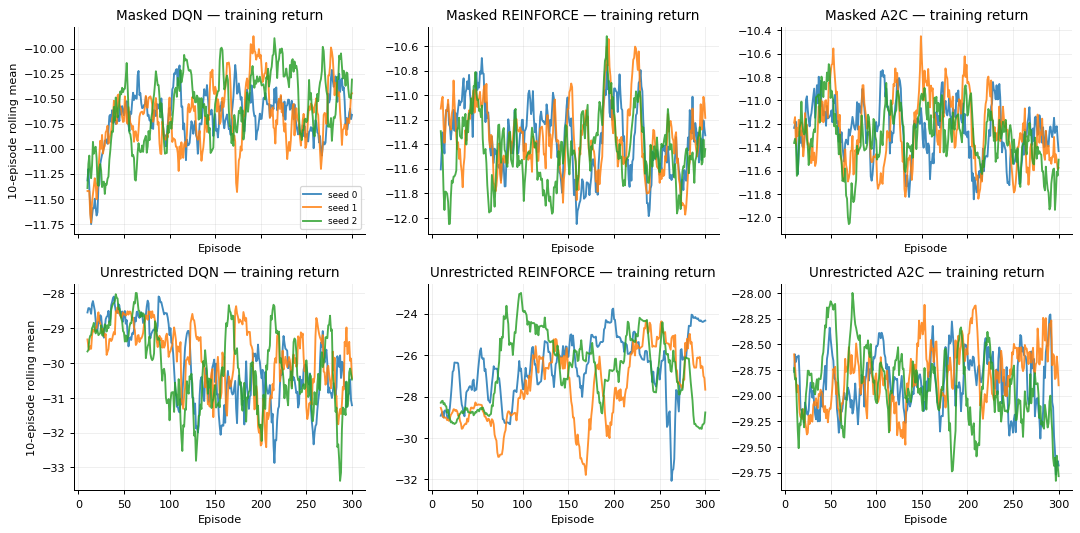

In [13]:
fig, axes = plt.subplots(2,3,figsize=(12,6),sharex=True)
for row, (label, folder) in enumerate([('Masked', HISTORICAL/'masked-study'),
                                      ('Unrestricted', HISTORICAL/'test/unmasked')]):
    for col, algorithm in enumerate(ALGORITHMS):
        ax = axes[row,col]
        for seed in range(3):
            history = pd.read_csv(folder/algorithm/f'seed-{seed}'/'training.csv')
            ax.plot(history['episode'], history['return'].rolling(10,min_periods=10).mean(),
                    label=f'seed {seed}',alpha=0.85)
        ax.set_title(f'{label} {algorithm.upper()} — training return')
        ax.set_xlabel('Episode'); ax.grid(alpha=0.2)
axes[0,0].set_ylabel('10-episode rolling mean'); axes[1,0].set_ylabel('10-episode rolling mean')
axes[0,0].legend(fontsize=7)
finish_plot(fig)

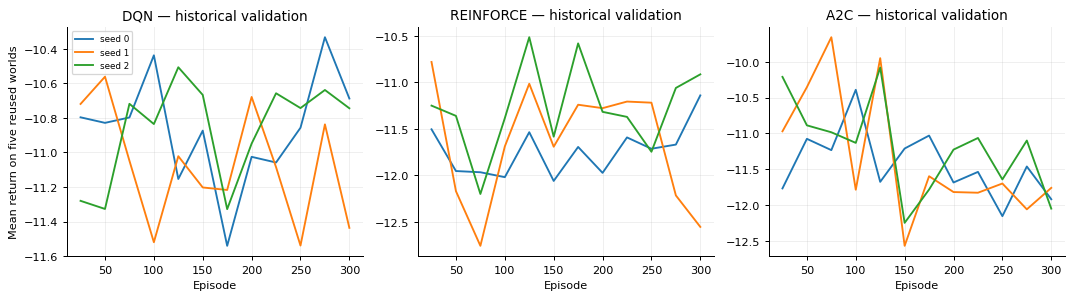

In [14]:
fig, axes = plt.subplots(1,3,figsize=(12,3.4))
for ax, algorithm in zip(axes, ALGORITHMS):
    for seed in range(3):
        v = pd.read_csv(HISTORICAL/'masked-study'/algorithm/f'seed-{seed}'/'validation.csv')
        curve = v.groupby('episode')['return'].mean()
        ax.plot(curve.index,curve.values,label=f'seed {seed}')
    ax.set_title(f'{algorithm.upper()} — historical validation'); ax.set_xlabel('Episode')
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Mean return on five reused worlds'); axes[0].legend(fontsize=7)
finish_plot(fig)

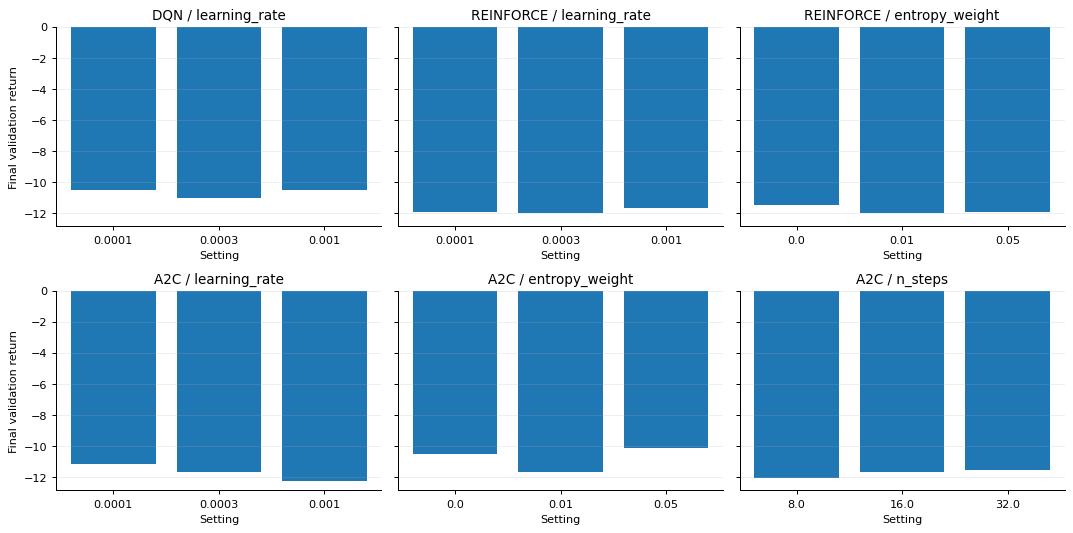

In [15]:
panels = list(tuning.groupby(['algorithm','parameter'],sort=False))
fig, axes = plt.subplots(2,3,figsize=(12,6),sharey=True)
for ax, ((algorithm, parameter),group) in zip(axes.flat,panels):
    ax.bar(group['value'].astype(str),group['final_validation_return'])
    ax.set_title(f'{algorithm.upper()} / {parameter}'); ax.set_xlabel('Setting')
    ax.grid(axis='y',alpha=0.2)
for ax in list(axes.flat)[len(panels):]: ax.set_visible(False)
axes[0,0].set_ylabel('Final validation return'); axes[1,0].set_ylabel('Final validation return')
finish_plot(fig)

### Historical sensitivity results

This is a one-fit sensitivity analysis of masked DQN, not three-seed robustness or retraining on every condition. Battery, recharge and spread change mission dynamics; returns across conditions need this context. Results suggest bottlenecks but do not identify a unique causal mechanism. The original reproduction command explicitly selects DQN:

```bash
python scripts/run_final_study.py sensitivity --algorithm dqn --seeds 0 --out runs/reproduced-historical-sensitivity
```

That command is provided for historical traceability and is not executed here. Reproducing the original study requires its original source and runtime, not merely substituting corrected code.

policy,all stay,greedy,masked dqn,masked random,planner,random,sweep
condition,,,,,,,
default,-15.3675,-5.2656,-10.9084,-11.3728,-5.2021,-29.0385,-11.8872
battery_capacity=120.0,-15.3675,-4.3387,-12.1196,-10.7491,-5.0751,-27.5623,-11.9477
battery_capacity=60.0,-15.3675,-4.6308,-10.5003,-11.0891,-5.2402,-29.7538,-11.8500
recharge_rate=3.0,-15.3675,-6.4897,-11.5975,-11.5961,-6.5866,-29.0505,-12.0670
recharge_rate=8.0,-15.3675,-4.8174,-10.3680,-10.9384,-4.4025,-29.0165,-11.7572
spread_probability=0.02,-15.3956,-5.7012,-10.6894,-11.5700,-5.3624,-29.0840,-11.9304
spread_probability=0.08,-15.3948,-6.5016,-11.1077,-11.5842,-5.1779,-28.9445,-11.8691


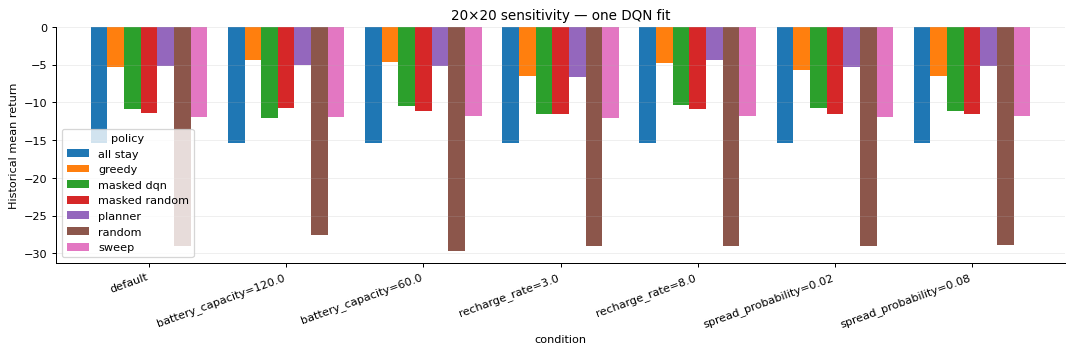

In [16]:
sensitivity_table = sens.pivot(index='condition',columns='policy',values='return_mean')
order = ['default']+[c for c in sensitivity_table.index if c!='default']
display(sensitivity_table.loc[order])
ax = sensitivity_table.loc[order].plot(kind='bar',figsize=(12,4),width=0.85)
ax.set_ylabel('Historical mean return'); ax.set_title('20×20 sensitivity — one DQN fit')
ax.grid(axis='y',alpha=0.2); plt.xticks(rotation=20,ha='right')
finish_plot(ax.figure)

## 7. Frozen 40×40 main study — design and training evidence

The main comparison is complete. The user froze the corrected implementation, complete settings and budget after stopping further loss tuning. It is a distinct fixed-budget RL study, independently initialized without supervised warm starts.

| Item | Frozen design |
| --- | --- |
| Algorithms and fits | DQN, REINFORCE, A2C × seeds 0,1,2 = nine main fits |
| Training | 300 episodes per fit; worlds 0–299 |
| Final evaluation | Fresh worlds 22000–22019; every final model and all four baselines |
| Checkpoint selection | Final checkpoint only; no validation split or best-seed selection |
| Reward and observations | Original reward, complete state, spatial location encoding |
| Mask | Feasible candidate actions plus emergency return fallback; shared with masked random |
| Budget | Equal episode budget; completed interactions and updates reported separately |
| Evaluation decisions | Deterministic masked first-index argmax for learners |
| Runtime | One PyTorch CPU thread; no claim that GPU improves learning |

All nine fits finished before final evaluation. Earlier draft targets of five seeds and 100 test worlds were reduced to three seeds and 20 worlds; this executed scope is disclosed. Twenty worlds per fitted model do not create twenty independent trained models. No 60×60 result or cross-grid transfer is claimed.

In [17]:
protocol = json.loads((MAIN/'launch.json').read_text())
audit = json.loads((MAIN/'audit.json').read_text())
completion = json.loads((MAIN/'completion.json').read_text())
assert protocol['source_revision'] == audit['source_revision'] == FROZEN_SOURCE
assert protocol['env_config'] == frozen['environment']
assert not set(range(300)) & set(frozen['evaluation_worlds'])
settings_table = pd.DataFrame(frozen['training']).loc[
    ['episodes','learning_rate','gamma','batch_size','replay_size','warmup_steps',
     'target_update_steps','epsilon_start','epsilon_end','epsilon_decay_steps','n_steps','entropy_weight','value_weight',
     'max_grad_norm','device','double_dqn','coordination_shaping_weight','validation_seeds']]
display(pd.DataFrame({'20×20 historical': EnvConfig(**development['environment']).to_dict(),
                      '40×40 main': frozen['environment']}))
display(settings_table)
fit_table = pd.DataFrame(audit['fits'])
display(fit_table)
assert len(fit_table)==9 and (fit_table['episodes']==300).all() and (fit_table['steps']==90000).all()
print('Total recorded training interactions:',int(fit_table['steps'].sum()))

,20×20 historical,40×40 main
grid_size,20.00,40.00
horizon,160.00,300.00
battery_capacity,80.00,160.00
move_cost,1.00,1.00
hover_cost,0.25,0.25
recharge_rate,5.00,8.00
sensor_radius,1.00,2.00
inspection_deadline,25.00,30.00
max_fuel,100.00,180.00
initial_fires,3.00,3.00


,dqn,reinforce,a2c
episodes,300,300,300
learning_rate,0.0001,0.001,0.0001
gamma,0.99,0.99,0.99
batch_size,32,32,32
replay_size,2000,2000,2000
warmup_steps,128,128,128
target_update_steps,100,100,100
epsilon_start,1.0,1.0,1.0
epsilon_end,0.05,0.05,0.05
epsilon_decay_steps,40000,40000,40000


,algorithm,seed,episodes,steps,updates,training_seconds
0,dqn,0,300,90000,89873,1133.6898
1,dqn,1,300,90000,89873,1460.6228
2,dqn,2,300,90000,89873,1449.9560
3,reinforce,0,300,90000,300,115.2797
4,reinforce,1,300,90000,300,216.1437
5,reinforce,2,300,90000,300,219.5033
6,a2c,0,300,90000,3000,215.8828
7,a2c,1,300,90000,3000,220.4090
8,a2c,2,300,90000,3000,221.3330


Total recorded training interactions: 810000


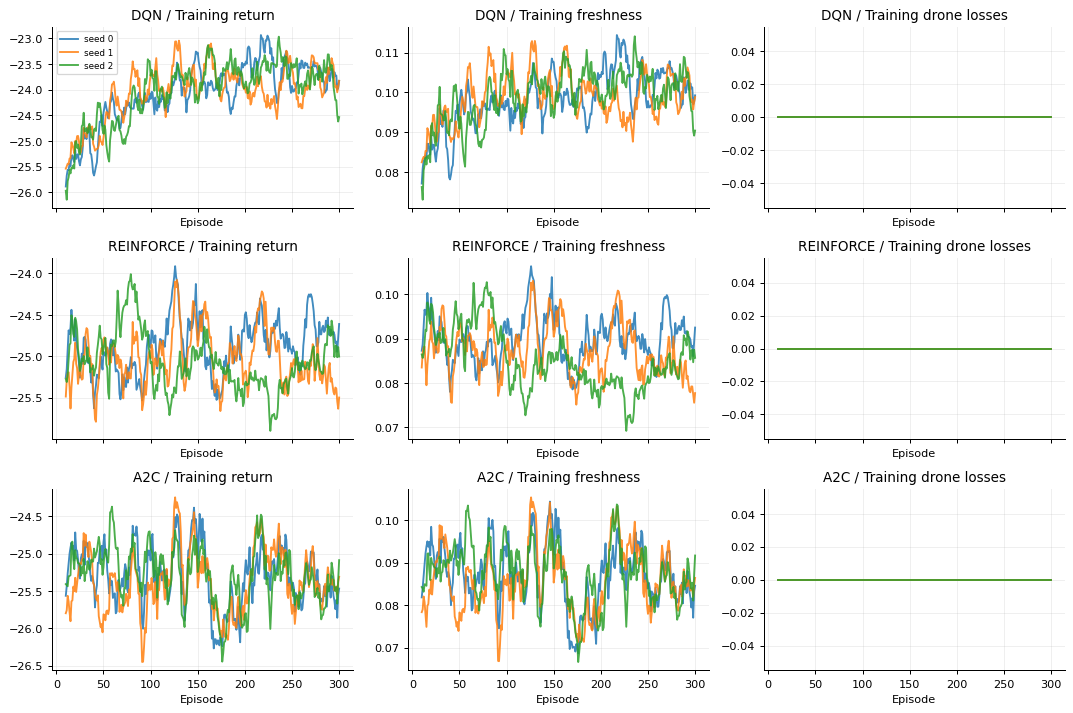

last 50 return  last 50 weighted_freshness  \
algorithm fit_seed                                               
a2c       0               -25.4559                      0.0846   
          1               -25.3687                      0.0856   
          2               -25.4304                      0.0850   
dqn       0               -23.6529                      0.1029   
          1               -23.8397                      0.0993   
          2               -23.9009                      0.0992   
reinforce 0               -24.6833                      0.0916   
          1               -25.2300                      0.0828   
          2               -25.0004                      0.0848   

                    last 50 total_losses  
algorithm fit_seed                        
a2c       0                          0.0  
          1                          0.0  
          2                          0.0  
dqn       0                          0.0  
          1                          0.0  
          2                          0.0  
reinforce 0                          0.0  
          1                          0.0  
          2                          0.0

Training curves describe sampled behavior on changing training worlds, not final generalization.


In [18]:
main_history = []
for algorithm in ALGORITHMS:
    for seed in range(3):
        frame = pd.read_csv(MAIN/'fits'/algorithm/f'seed-{seed}'/'training.csv')
        assert len(frame)==300 and frame['scenario_seed'].tolist()==list(range(300))
        main_history.append(frame.assign(algorithm=algorithm,fit_seed=seed))
main_history = pd.concat(main_history,ignore_index=True)
fig, axes = plt.subplots(3,3,figsize=(12,8),sharex=True)
metrics = [('return','Training return'),('weighted_freshness','Training freshness'),
           ('total_losses','Training drone losses')]
for row,algorithm in enumerate(ALGORITHMS):
    for col,(metric,label) in enumerate(metrics):
        ax = axes[row,col]
        for seed in range(3):
            frame = main_history.query('algorithm == @algorithm and fit_seed == @seed')
            ax.plot(frame['episode'],frame[metric].rolling(10,min_periods=10).mean(),
                    label=f'seed {seed}',alpha=0.85)
        ax.set_title(f'{algorithm.upper()} / {label}'); ax.set_xlabel('Episode')
        ax.grid(alpha=0.2)
axes[0,0].legend(fontsize=7)
finish_plot(fig)
last_window = main_history[main_history['episode']>250].groupby(['algorithm','fit_seed'])[
    ['return','weighted_freshness','total_losses']].mean()
display(last_window.rename(columns=lambda c:'last 50 '+c))
print('Training curves describe sampled behavior on changing training worlds, not final generalization.')

### What these curves establish

Each fit completed 90,000 interactions. DQN made 89,873 optimizer updates; REINFORCE made 300 episode updates; A2C made 3,000 segment updates. Equal interactions do not imply equal optimization work or CPU time. Return curves alone do not prove convergence, calibrated Q values or optimality. No additional fits are triggered by their shape.

Stochastic actor sampling during training and deterministic argmax at evaluation are different policies. Their mismatch is a plausible contributor to poor evaluation; the historical sampled-actor diagnostic also failed, so changing evaluation mode alone is not an established solution. Main final evaluation remains the frozen deterministic rule.

## 8. Fresh-world final evaluation, uncertainty and audit

We first average the 20 world outcomes within each fitted seed, then average the three fitted-seed means. Learner sample SD is across those three means. Baseline mean and sample SD are across 20 worlds. These units are different. No confidence intervals or statistical significance claims are inferred from the displayed SDs.

The paired table retains the same world for each learner/baseline difference. It is descriptive; repeated worlds across fit seeds do not turn 60 learner missions into 60 independent training replicates. Every final fitted policy is shown, not just the best seed.

In [19]:
episodes = pd.read_csv(MAIN/'episodes.csv')
archived_summary = pd.read_csv(MAIN/'summary.csv')
comparison = pd.read_csv(MAIN/'comparison.csv')
paired = pd.read_csv(MAIN/'paired.csv')
assert len(episodes)==260 and set(episodes['scenario_seed'])==set(frozen['evaluation_worlds'])
assert not episodes.duplicated(['policy','training_seed','scenario_seed']).any()
assert len(paired)==720
assert episodes.query('policy in @ALGORITHMS').shape[0]==180
assert episodes.query('policy not in @ALGORITHMS').shape[0]==80
metrics = ['return','weighted_freshness','overdue_fraction','total_losses',
           'fleet_failure','intact_fleet','energy_used','safe_returns','charge_completions',
           'collision_attempts','steps','decision_ms']
rows = []
for policy in POLICIES:
    frame = episodes[episodes['policy']==policy]
    units = frame.groupby('training_seed')[metrics].mean() if policy in ALGORITHMS else frame[metrics]
    if policy in ALGORITHMS:
        assert len(units)==3 and set(frame['training_seed'])=={0,1,2}
        assert frame.groupby('training_seed').size().eq(20).all()
    else:
        assert len(units)==20
    for metric in metrics:
        rows.append({'policy':policy,'metric':metric,'unit':'seed_means' if policy in ALGORITHMS
                     else 'worlds','units':len(units),'mean':units[metric].mean(),
                     'sample_sd':units[metric].std(ddof=1)})
recomputed_summary = pd.DataFrame(rows)
check = recomputed_summary.merge(archived_summary,on=['policy','metric'],suffixes=('_new','_archive'))
assert len(check)==len(archived_summary)==len(recomputed_summary)
assert np.allclose(check['mean_new'],check['mean_archive'],rtol=1e-12,atol=1e-12)
assert np.allclose(check['sample_sd_new'],check['sample_sd_archive'],rtol=1e-12,atol=1e-12)
main_means = recomputed_summary.pivot(index='policy',columns='metric',values='mean').loc[POLICIES]
main_sds = recomputed_summary.pivot(index='policy',columns='metric',values='sample_sd').loc[POLICIES]
display(main_means[['return','weighted_freshness','overdue_fraction','total_losses',
                    'intact_fleet','safe_returns','charge_completions','decision_ms']])
display(recomputed_summary[recomputed_summary['metric'].isin(
    ['return','weighted_freshness','overdue_fraction','total_losses'])])
print('All archived final means and sample SDs reproduced from 260 raw mission rows.')

metric,return,weighted_freshness,overdue_fraction,total_losses,intact_fleet,safe_returns,charge_completions,decision_ms
policy,,,,,,,,
dqn,-24.7857,0.0844,0.8687,0.0,1.0,4.6333,4.5667,0.4308
reinforce,-25.8105,0.0690,0.8940,0.0,1.0,4.0000,4.0000,0.6534
a2c,-24.8277,0.0843,0.8695,0.0,1.0,5.0667,5.0667,0.6925
greedy,-16.1001,0.2208,0.6556,0.0,1.0,3.1500,3.1500,3.1663
sweep,-26.0710,0.0649,0.9012,0.0,1.0,1.0000,1.0000,0.2051
random,-42.8711,0.0596,0.9210,3.0,0.0,3.4000,0.6500,0.0086
masked_random,-25.4615,0.0838,0.8860,0.0,1.0,9.8500,9.8000,0.2063


,policy,metric,unit,units,mean,sample_sd
0,dqn,return,seed_means,3,-24.7857,0.2499
1,dqn,weighted_freshness,seed_means,3,0.0844,0.0025
2,dqn,overdue_fraction,seed_means,3,0.8687,0.0063
3,dqn,total_losses,seed_means,3,0.0000,0.0000
12,reinforce,return,seed_means,3,-25.8105,0.5872
13,reinforce,weighted_freshness,seed_means,3,0.0690,0.0073
14,reinforce,overdue_fraction,seed_means,3,0.8940,0.0157
15,reinforce,total_losses,seed_means,3,0.0000,0.0000
24,a2c,return,seed_means,3,-24.8277,0.9171
25,a2c,weighted_freshness,seed_means,3,0.0843,0.0116


All archived final means and sample SDs reproduced from 260 raw mission rows.


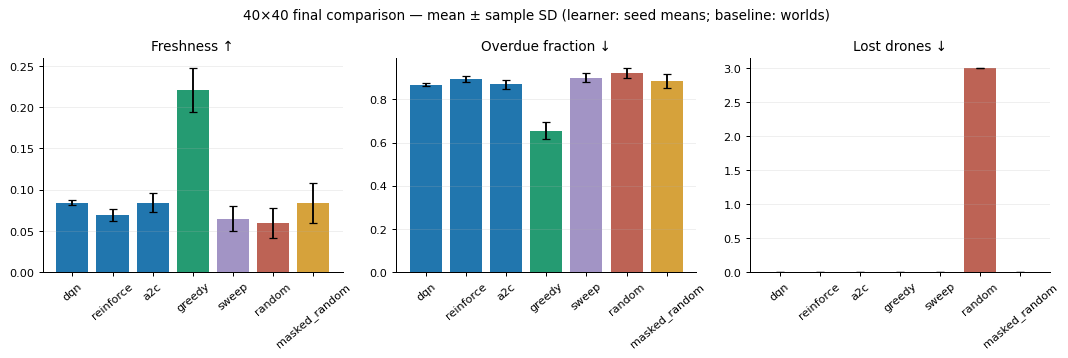

,policy,training_seed,worlds,return,weighted_freshness,overdue_fraction,total_losses,fleet_failure,intact_fleet
0,dqn,0.0,20,-24.5366,0.0871,0.8627,0.0,0.0,1.0
1,dqn,1.0,20,-24.7840,0.0839,0.8681,0.0,0.0,1.0
2,dqn,2.0,20,-25.0364,0.0821,0.8753,0.0,0.0,1.0
3,reinforce,0.0,20,-25.1431,0.0774,0.8764,0.0,0.0,1.0
4,reinforce,1.0,20,-26.2478,0.0644,0.9063,0.0,0.0,1.0
5,reinforce,2.0,20,-26.0407,0.0653,0.8994,0.0,0.0,1.0
6,a2c,0.0,20,-25.8860,0.0709,0.8953,0.0,0.0,1.0
7,a2c,1.0,20,-24.3326,0.0903,0.8575,0.0,0.0,1.0
8,a2c,2.0,20,-24.2646,0.0918,0.8557,0.0,0.0,1.0
9,greedy,NaN,20,-16.1001,0.2208,0.6556,0.0,0.0,1.0


In [20]:
fig,axes = plt.subplots(1,3,figsize=(12,4))
for ax,metric,title in zip(axes,['weighted_freshness','overdue_fraction','total_losses'],
                         ['Freshness ↑','Overdue fraction ↓','Lost drones ↓']):
    ax.bar(POLICIES,main_means[metric],yerr=main_sds[metric],capsize=3,
           color=['#2176ae']*3+['#259b72','#a294c5','#bd6355','#d6a23b'])
    ax.set_title(title); ax.tick_params(axis='x',rotation=40); ax.grid(axis='y',alpha=0.2)
fig.suptitle('40×40 final comparison — mean ± sample SD (learner: seed means; baseline: worlds)')
finish_plot(fig)
display(comparison[['policy','training_seed','worlds','return','weighted_freshness',
                    'overdue_fraction','total_losses','fleet_failure','intact_fleet']])

In [21]:
gates = pd.DataFrame([{'algorithm':r['algorithm'],'seed':r['seed'],
                       'learned contribution gate':r['learning_gate_passed'],
                       'Greedy capability gate':r['greedy_gate_passed'],
                       **{'mask: '+k:v for k,v in r['masked_random_checks'].items()},
                       **{'Greedy: '+k:v for k,v in r['greedy_checks'].items()}}
                      for r in completion['per_fit']])
display(gates)
assert len(gates)==9 and not gates['learned contribution gate'].any()
assert not gates['Greedy capability gate'].any()
survival = episodes.groupby('policy').agg(missions=('intact_fleet','size'),
    intact_fleet_missions=('intact_fleet','sum'),failed_fleet_missions=('fleet_failure','sum'),
    mean_lost_drones=('total_losses','mean')).loc[POLICIES]
display(survival)
print('Comparison completed:',completion['comparison_complete'])
print('Performance gates passed:',int(gates['learned contribution gate'].sum()),'of 9')

,algorithm,seed,learned contribution gate,Greedy capability gate,mask: freshness_ge_masked_random_plus_001,mask: return_ge_masked_random_plus_05,mask: losses_le_masked_random,mask: failures_le_masked_random,Greedy: freshness_ge_90pct_greedy,Greedy: overdue_le_greedy_plus_005,Greedy: losses_le_greedy_plus_01,Greedy: failures_le_greedy
0,dqn,0,False,False,False,True,True,True,False,False,True,True
1,dqn,1,False,False,False,True,True,True,False,False,True,True
2,dqn,2,False,False,False,False,True,True,False,False,True,True
3,reinforce,0,False,False,False,False,True,True,False,False,True,True
4,reinforce,1,False,False,False,False,True,True,False,False,True,True
5,reinforce,2,False,False,False,False,True,True,False,False,True,True
6,a2c,0,False,False,False,False,True,True,False,False,True,True
7,a2c,1,False,False,False,True,True,True,False,False,True,True
8,a2c,2,False,False,False,True,True,True,False,False,True,True


,missions,intact_fleet_missions,failed_fleet_missions,mean_lost_drones
policy,,,,
dqn,60,60,0,0.0
reinforce,60,60,0,0.0
a2c,60,60,0,0.0
greedy,20,20,0,0.0
sweep,20,20,0,0.0
random,20,0,20,3.0
masked_random,20,20,0,0.0


Comparison completed: True
Performance gates passed: 0 of 9


The learning gate requires every fit to achieve freshness ≥ masked random +0.01, return ≥ masked random +0.5 and no worse losses/fleet failures. The Greedy gate separately requires ≥90% of Greedy freshness, overdue ≤ Greedy +0.05, losses ≤ Greedy +0.1 and no worse fleet failures. These are predeclared project criteria, not assignment grading requirements. All nine fitted policies failed both complete gates.

All 180 learned missions retained the fleet. Masked random retained it in all 20 missions. Unrestricted random lost all three drones in all 20 missions. DQN and A2C mean freshness exceeded masked random by only about 0.0006; that small descriptive difference does not establish a useful learned contribution. Greedy has the best mean freshness and return in this final comparison.

In [22]:
display(pd.DataFrame([{'audit item':k,'recorded result':str(v)} for k,v in audit.items()
                     if k!='fits']))
assert audit['passed'] and audit['initial_tensors_verified']
assert audit['every_action_mask_hash_reward_exact'] and audit['negative_archives_unchanged']
assert audit['mission_episodes']==len(episodes)
assert audit['mission_steps']==int(episodes['steps'].sum())==75911
assert audit['paired_rows']==len(paired) and audit['max_score_drift']==0.0
print('Recorded independent replay: 75,911 steps, exact actions/masks/hashes/rewards, zero neural-score drift.')
print('This notebook checks records and aggregates; it does not claim to replay binary checkpoints here.')

,audit item,recorded result
0,passed,True
1,source_revision,855e5510ff46b16082ab7d551e7c228acab6f572
2,mission_episodes,260
3,mission_steps,75911
4,paired_rows,720
5,every_action_mask_hash_reward_exact,True
6,negative_archives_unchanged,True
7,initial_tensors_verified,True
8,max_score_drift,0.0
9,score_atol,1e-05


Recorded independent replay: 75,911 steps, exact actions/masks/hashes/rewards, zero neural-score drift.
This notebook checks records and aggregates; it does not claim to replay binary checkpoints here.


Independent replay checked initial tensors, source/configuration and checkpoint bytes, training counts, masks, action choices, hashes, rewards, compressed scores, aggregate tables and gates. Neural score tolerance was fixed at $10^{-5}$ absolute and $10^{-6}$ relative; selected actions and hashes stayed strict. Zero measured drift describes this replay, not guaranteed equality across arbitrary packages, devices or hardware.

The permanent Git archive retains numerical evidence, traces, scores and metadata. Raw initial/final weights were exported as Actions artifacts with **90-day retention**; retaining/downloaded weights is necessary for future full replay. Do not treat expiring artifacts as permanent checkpoint storage.

## 9. 20×20 versus 40×40 — clear historical comparison

The two columns describe different experiments. Horizon, battery, recharge, sensing radius, deadline, fuel, worlds and code revision change together. Historical 20×20 results predate corrections. They do not isolate a causal grid-size effect. A matched corrected rerun would be needed only to support that separate scaling claim.

Freshness measures recency weighted by location importance; the percentages below are scores, not land coverage. Zero losses means survival, not that all drones returned to base at mission end.

,20×20 freshness %,40×40 freshness %,20×20 return,40×40 return,20×20 mean losses,40×40 mean losses
controller,,,,,,
dqn,14.5851,8.4383,-10.9188,-24.7857,0.00,0.0
reinforce,13.3434,6.9014,-11.4903,-25.8105,0.00,0.0
a2c,13.6938,8.4347,-11.1970,-24.8277,0.00,0.0
greedy,32.2035,22.0769,-5.2656,-16.1001,0.15,0.0
sweep,11.6755,6.4858,-11.8872,-26.0710,0.00,0.0
random,9.4527,5.9562,-29.0385,-42.8711,3.00,3.0
masked_random,14.4976,8.3794,-11.3728,-25.4615,0.00,0.0


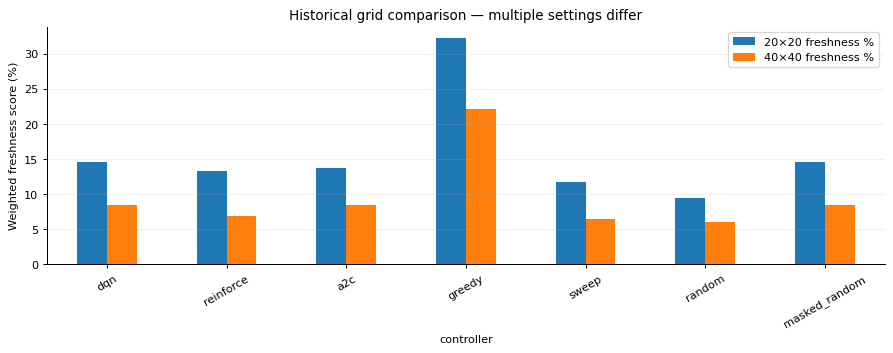

40×40 learner freshness minus masked random (percentage points):


policy
dqn          0.0589
reinforce   -1.4780
a2c          0.0553
Name: difference pp, dtype: float64

In [23]:
names20 = {'dqn':'masked dqn','reinforce':'masked reinforce','a2c':'masked a2c',
           'greedy':'greedy','sweep':'sweep','random':'random','masked_random':'masked random'}
historical_by_name = historical_summary.set_index('policy')
grid_rows = []
for policy in POLICIES:
    old = historical_by_name.loc[names20[policy]]
    new = main_means.loc[policy]
    grid_rows.append({'controller':policy,'20×20 freshness %':100*old['weighted_freshness_mean'],
                     '40×40 freshness %':100*new['weighted_freshness'],
                     '20×20 return':old['return_mean'],'40×40 return':new['return'],
                     '20×20 mean losses':old['total_losses_mean'],
                     '40×40 mean losses':new['total_losses']})
grid_comparison = pd.DataFrame(grid_rows).set_index('controller')
display(grid_comparison)
fig, ax = plt.subplots(figsize=(10,4))
grid_comparison[['20×20 freshness %','40×40 freshness %']].plot.bar(ax=ax)
ax.set_ylabel('Weighted freshness score (%)'); ax.set_title('Historical grid comparison — multiple settings differ')
ax.grid(axis='y',alpha=0.2); plt.xticks(rotation=30)
finish_plot(fig)
print('40×40 learner freshness minus masked random (percentage points):')
display(((main_means.loc[ALGORITHMS,'weighted_freshness']-
          main_means.loc['masked_random','weighted_freshness'])*100).rename('difference pp'))

## 10. Critical interpretation and limits

**What improved:** feasibility rules made the recorded learned missions safe, study-integrity fixes aligned checkpoints and targets with their metadata, and the final study has stronger provenance and replay evidence. Improved traceability is not improved learned surveillance. The historical masked study and final main study both remain close to masked random in freshness.

**What remains weak:** the final learners did not reach useful surveillance quality relative to Greedy. Increasing the problem size did not establish a learning advantage. Supervised fitting on training states could be excellent while fresh-state action ranking and complete missions remained poor. Drone-centered inputs and broader data improved specific development diagnostics; loss-only ranking tuning then reduced mission quality. Those results explain why we stopped that direction, not why every possible architecture or objective would fail.

| Observation | Supported conclusion | Unresolved explanation |
| --- | --- | --- |
| Masked random has zero losses | Feasibility rules supply substantial safety | How much additional recharge coordination the learner acquires |
| DQN/A2C freshness near masked random | Little useful learned inspection gain in this budget | Representation, exploration, target noise and objective mismatch may all contribute |
| Strong training label fit, weak fresh rankings | Fitting the training corpus is insufficient | Which distribution shifts dominate autonomous missions |
| Better exact-reference missions than fitted scores | Approximation/ranking error matters in that diagnostic | Whether better supervised rankings would help long-horizon RL |
| More updates / slower exploration / alternate targets often fail | These tested interventions did not solve the task | A larger, separately designed study might have a different outcome |
| Training actors sampled, final actors used argmax | Training and evaluation policies differ | Main-study evidence does not isolate the effect of this mismatch |

The reward optimizes incremental inspection gain plus penalties, whereas headline freshness evaluates continuous recency. Their alignment is incomplete. The masks also shrink the decision set and embed battery knowledge. These are reasons to interpret results carefully, not retrospective proof of a unique cause.

Three training seeds provide limited precision. Shared scenario sequences and repeated final worlds require respecting dependence. Historical selected-validation scores are biased. A fixed 300-episode budget is evidence of performance at that budget, not proof of convergence. Synthetic state/full observability and uncalibrated fire/energy scales limit operational relevance.

Potential future studies could test an objective aligned with persistent freshness, a structured fleet decision representation, uncertainty/partial observations, a different charging layout or a matched scaling protocol. These are hypotheses, not completed improvements. Any new study needs its own declared settings, budget and untouched test scenarios. No further loss tuning, longer fitting or 60×60 run is required to document the present negative findings.

## 11. Reproduction and evidence retention

Run All regenerates the displayed archive analysis and checks aggregate integrity. It does not depend on `runs/`, downloaded neural weights or GPU availability. Full training/replay is a separate workflow, not a notebook toggle.

For exact main-study replay, download the final results artifact from [Actions run 38134714083](https://github.com/SayuruRehan/wild-drone-appeared/actions/runs/38134714083), retain its checksum and extract its `runs/rl-main-2026-10-11` folder. Use the frozen source and compatible runtime, then replay to a **fresh** output folder:

```bash
python scripts/audit_scale_rl.py --run runs/rl-main-2026-10-11 --out runs/replayed-rl-main
```

Artifact: `frozen-40x40-rl-results-855e5510ff46b16082ab7d551e7c228acab6f572`, 90-day retention. The downloaded results ZIP checksum is `0576ffc451d84f42085bc385be9afb8eacd4f7715d6107aa5a1128fc4563c130`. The complete recipe is [docs/scale-rl-protocol.md](docs/scale-rl-protocol.md); all configuration is [configs/rl-main-frozen.json](configs/rl-main-frozen.json). Training commands in that protocol remain documentation and are not executed by this notebook.

The following manifest verifies the exact committed source and data bytes used for this consolidated analysis. Source changes must update the notebook intentionally; missing or stale records cause a failure instead of silently falling back to old outputs. This is not a replacement for the independent checkpoint replay.

In [24]:
ANALYSIS_INPUT_SHA256 = {'configs/development.json': 'b0c8b6e52a3b9b4db45e57ffc59ed581c02df4305a36adcb671c9a09d4a0ec2d', 'configs/rl-main-frozen.json': 'd6b6d38bf69cd34d1260ec48e042aa479996e27104a9da21b85b9670126b6fbf', 'docs/colab1000-results.md': '5e19c21fa5045dfae82018d265b3ec80aac1aadbc78992d7544d7b5886fea0d3', 'docs/experiments/action-2026-10-04/README.md': 'dcd4666a5d7fd99434c7961751e34bd66d276ced05a8d54fd54de8bca1b61e53', 'docs/experiments/centered-inspection-2026-10-10/README.md': '97dd6a1b2a6784a186062c65a162c80e6581e79864a4875428546c1a9e5b6acc', 'docs/experiments/colab-2026-10-03/README.md': '9245a4db708835c25087e661e7e5c6a39ab3a333bbf0fe4546dd1275ad1b8bc4', 'docs/experiments/colab-2026-10-03/raw/validation20-v2/a2c/seed-0/training.csv': '51741b373d8abc02e009af47aaa8f27f522f7c15b0ae74d776735f62e61f8722', 'docs/experiments/colab-2026-10-03/raw/validation20-v2/a2c/seed-1/training.csv': '447500fcc5489faa911d637098313d7cfc3c52a90dc12cbe9236e637692e3794', 'docs/experiments/colab-2026-10-03/raw/validation20-v2/a2c/seed-2/training.csv': '9a5849eb9517a273ba3bc0c31482058920a8ecd25f2b1cbb55bf3f9c33392c9e', 'docs/experiments/colab-2026-10-03/raw/validation20-v2/dqn/seed-0/training.csv': '1dc3445618a9dffc2a6872eff183b853273bb026c6b65e989be16b89ed01da53', 'docs/experiments/colab-2026-10-03/raw/validation20-v2/dqn/seed-1/training.csv': 'c5ac7484808e9c3c87f6c2d99835229f6cfc6061f9b940945fa60387c41f571a', 'docs/experiments/colab-2026-10-03/raw/validation20-v2/dqn/seed-2/training.csv': '9199fa99db5236a26ccbedd7032a285e20265742a81e1ca6609e31516693ecac', 'docs/experiments/colab-2026-10-03/raw/validation20-v2/reinforce/seed-0/training.csv': '510074a462d21e16c8185b12dc0f962bcdba71fb1054abc52925b938b0c467e3', 'docs/experiments/colab-2026-10-03/raw/validation20-v2/reinforce/seed-1/training.csv': '79c199ca13ae7e566ba6af5a07f6b168d440e16037a76c1d363bb633796572ae', 'docs/experiments/colab-2026-10-03/raw/validation20-v2/reinforce/seed-2/training.csv': '481cee879fdb95f631720b0343ee0d877bfd1c2fcbe511ff1ac307e099769697', 'docs/experiments/coordination-2026-10-10/README.md': 'ed4876d28f8854d8f4a316a32df93c170bba35df60d775d5ce30f422c59f96b5', 'docs/experiments/coverage-2026-10-04/README.md': '5526320431c40d926bda4da9f2de35132360e03782183a8d1db4bdfdf5b68889', 'docs/experiments/double-dqn-2026-10-10/README.md': '7661ea7d4bf7b5437288a18c5cda6e7f55f2cdcd1ed92d43f57e0284f2fb82ae', 'docs/experiments/dqn-rate-probe-2026-10-03/README.md': '9a0b967587e869fa135712a76e89257e78d50bad5622c9d3e4399283c5b496db', 'docs/experiments/dqn-stability-2026-10-03/README.md': 'e994e621d9c0a630e71e909c33dd3f5e3520e1c9be6449707f405931d0c3e97b', 'docs/experiments/exploration-2026-10-03/README.md': '11dfb47ec975b1b8abca03d383d511e992ac25463275ce5bdf74ae3038d94a08', 'docs/experiments/final-2026-10-05/masked-study/a2c/seed-0/training.csv': '3690ed34d30a5bde668f86bb88a2b29acd67554f7e432884b7dc3dd4c81a46c4', 'docs/experiments/final-2026-10-05/masked-study/a2c/seed-0/validation.csv': 'ba801a85508c55ee0bfa1a26014ccc5fe34515ad5a53d2f9e33d997a5b7a437f', 'docs/experiments/final-2026-10-05/masked-study/a2c/seed-1/training.csv': '45a302906c3c2a6a37d982ecc1f45b7b50b469ed2b9939d940a11936add13dab', 'docs/experiments/final-2026-10-05/masked-study/a2c/seed-1/validation.csv': 'c5d0950fca98d6d3c8027e45760f9d608da3510f36177167dce1305c8df24301', 'docs/experiments/final-2026-10-05/masked-study/a2c/seed-2/training.csv': 'e368b9b926ccac9519c1ff3185397d42703ea1994c3ae31dacda965164d00d16', 'docs/experiments/final-2026-10-05/masked-study/a2c/seed-2/validation.csv': '73d09a28c7849437dce9a1d48cc5940bc05d5e6bcdc2e35a9ad37073ba80df28', 'docs/experiments/final-2026-10-05/masked-study/dqn/seed-0/training.csv': '38fc2740521bda37e49582809a480d985cf8b3ac4e17726bd529575ef39db2c0', 'docs/experiments/final-2026-10-05/masked-study/dqn/seed-0/validation.csv': 'e61bd98b9d918fd4eee94ca9bfccbd3067a969e30336098bfea8cc92b03f7c9a', 'docs/experiments/final-2026-10-05/masked-study/dqn/seed-1/training.csv': '32fc8873de63898f964ca0a99d5c40d619688e95915e7a385f5008c467640fb5', 'docs/experiments/final-2026-10-05/masked-study/dqn/seed-1/validation.csv': '70097e40d602a7848521c760609c14e00566af1f7e8394331dcb81e7c0a02508', 'docs/experiments/final-2026-10-05/masked-study/dqn/seed-2/training.csv': 'f1a77f61f4417064287a3d2ee9c25060116eab8ed9bcff7010068092e0bea4f4', 'docs/experiments/final-2026-10-05/masked-study/dqn/seed-2/validation.csv': 'cd49b24ccb5c70168881b6e42a084d38a371304c7253c53964c4e62c40c4e574', 'docs/experiments/final-2026-10-05/masked-study/reinforce/seed-0/training.csv': '7a6b69e61cf22aea749a0697332285acde9cfe46c4f50ca148c35bbece70a27f', 'docs/experiments/final-2026-10-05/masked-study/reinforce/seed-0/validation.csv': 'cdce7ca47934ec1287690e4fceab2d86bb78d225e79debc058f20e18b593bf69', 'docs/experiments/final-2026-10-05/masked-study/reinforce/seed-1/training.csv': '340d27ee3ae8144c7d9277d8c97d296b5c8093a43c82ebb8bbb2bcb060ae58e2', 'docs/experiments/final-2026-10-05/masked-study/reinforce/seed-1/validation.csv': 'dc641176c8f877c2a7fbe72be8d5bc3cc501f864aedf9c3883c670bed019e196', 'docs/experiments/final-2026-10-05/masked-study/reinforce/seed-2/training.csv': '49f59205f297f4a151626c8b39aca06ece1b10e73b5fc7c3ae5ea41b3f7ecc29', 'docs/experiments/final-2026-10-05/masked-study/reinforce/seed-2/validation.csv': '7ee28aaf9619554fe071a63c4a4db5fe6ce46d28fd4f48e45c3757fee39a533b', 'docs/experiments/final-2026-10-05/sensitivity_summary.csv': '950b0dd28d592146318d38b35efe2111c29b655a83dad8bfda7973c846691c5b', 'docs/experiments/final-2026-10-05/test/unmasked/a2c/seed-0/training.csv': '252da2e1ed1196d932a8b6c4956204e416de13a82617e02d0264c72b93601acf', 'docs/experiments/final-2026-10-05/test/unmasked/a2c/seed-1/training.csv': '0e122be9020a79bcffe8d21e7997e76eb58ce6d549d80c647ff5ef6d50384fc1', 'docs/experiments/final-2026-10-05/test/unmasked/a2c/seed-2/training.csv': '291af0061cc07ca58f48f65433de6b74a5caadd46ce841cff90f450b3f8280b5', 'docs/experiments/final-2026-10-05/test/unmasked/dqn/seed-0/training.csv': '4ca3598a239dc41b240581a1dcd79ce9c2e81321a120022738ef25f7f46ddc1c', 'docs/experiments/final-2026-10-05/test/unmasked/dqn/seed-1/training.csv': '4be56fb9b37026d01d45621ff2a51d848ce9690b9e2ebc6515a520fd0d982cc2', 'docs/experiments/final-2026-10-05/test/unmasked/dqn/seed-2/training.csv': 'd3dc58a35944d89c3d24216ac435520be00e7b6a205cdcd50cd5ef1bab8a070b', 'docs/experiments/final-2026-10-05/test/unmasked/reinforce/seed-0/training.csv': 'aa1f6358153d315abede0d443353a6dbc1e01f51dcdc9c28ec607592fd72eb93', 'docs/experiments/final-2026-10-05/test/unmasked/reinforce/seed-1/training.csv': '384697d6aeaf8e092d618e10176f8c70dd0658d5363d7f47a2011086c99ec57a', 'docs/experiments/final-2026-10-05/test/unmasked/reinforce/seed-2/training.csv': '6103f0373e4787909906928b80417d13faede81d20f5bff2caf7e571447e1cf2', 'docs/experiments/final-2026-10-05/test_summary.csv': '3f7e99a59746ddd87896187158e296e9d41498338022b0c121afc250e600468a', 'docs/experiments/final-2026-10-05/tuning.csv': '59c9c46cfd2f979aa5f8d3a9519852aa951d31bcdfa33f7775f9e569dad5f796', 'docs/experiments/fitting-budget-2026-10-04/README.md': 'b6121e22b26f57bea0aa1c74c82d4e14b01a70a03f0411671ba4d18a20738f70', 'docs/experiments/imitation-2026-10-03/README.md': '876d8869326334503eb92311fb37cb0a52c4c8f49ab5ac86400cca3d79ddbe55', 'docs/experiments/inspection-targets-2026-10-10/README.md': 'a23ad597af273897601e9ea62ce7641713181ce98b19550ed84fc19f685ad920', 'docs/experiments/mission-validation-2026-10-10/README.md': '750d78d5ca9ac76e17ab9c66977c93c8c8efff9ec1d080ea4af735256b3277aa', 'docs/experiments/rankings-2026-10-10/README.md': 'c65528a065b61605c395a78f187f8cc390a830c24322740295ee472970c75f7f', 'docs/experiments/recovery-2026-10-04/README.md': '96c7c57050987631741313c9e936da6025dbf979daa7553eea03d1a0df474ddb', 'docs/experiments/representation-2026-10-04/README.md': '0b27f8c93b16b193216a6cbae7480fa859807a25454f85256ad34c736a47cbee', 'docs/experiments/rl-main-2026-10-11/README.md': 'f16c263a8dbb648e9cdf94d183eb3bda889e2af26c8a70fc8091e00de601c950', 'docs/experiments/rl-main-2026-10-11/audit.json': 'cb0594e61597f5d79395945696acdb48daa415788b7d5236b86f3646f2b98b92', 'docs/experiments/rl-main-2026-10-11/comparison.csv': '68906c1e436f7e169c7ca0a90897382b074eda372cc8c1c600bceaadccc502b0', 'docs/experiments/rl-main-2026-10-11/completion.json': '3465a4bc3ef87b07ac1864f3616b84f0e083dad1b7b7b182e770c93bbf6c6d81', 'docs/experiments/rl-main-2026-10-11/episodes.csv': 'f1f6b1122ea984a84eca6bf494a9d86284dd541611c22800d1d80ea769ec4f5e', 'docs/experiments/rl-main-2026-10-11/fits/a2c/seed-0/training.csv': '8b3d6a472782d8d113a98652eb33e602eb55e8fb98d4bbcedcacd483d6c5bff6', 'docs/experiments/rl-main-2026-10-11/fits/a2c/seed-1/training.csv': '0c89a65435e6851a353d2f851b93e66244557c29dec56ca2ed4a1df945d732c1', 'docs/experiments/rl-main-2026-10-11/fits/a2c/seed-2/training.csv': 'b127286f8026e2f61db4e602111584d738f1e87f10ec899c715f05d08ca0d4c6', 'docs/experiments/rl-main-2026-10-11/fits/dqn/seed-0/training.csv': 'b63611d1ed58508a4756dcb002730e0c794aa9c26c14fece320be5d7f5053821', 'docs/experiments/rl-main-2026-10-11/fits/dqn/seed-1/training.csv': '2ab3c7953033660360f7f3aed12b7d4cbc1d6485340be091b621e8e1949db2cd', 'docs/experiments/rl-main-2026-10-11/fits/dqn/seed-2/training.csv': '60bc0fc3b6f701deb34fd5cdef83e23763d978073ae7b3bdc3ef4c98c53e1946', 'docs/experiments/rl-main-2026-10-11/fits/reinforce/seed-0/training.csv': '713eedbf434e95c51415c4cdc0264f2e018dd979094bfb28748e965b53a4f36a', 'docs/experiments/rl-main-2026-10-11/fits/reinforce/seed-1/training.csv': '0dbe3609ae78318bcfd187b486c989f34937c3be08f57aa7bd0d0f07ecce2f47', 'docs/experiments/rl-main-2026-10-11/fits/reinforce/seed-2/training.csv': 'c6a7194ee6ee6531c2af5bacc913ad108802c10564af5796e1ea158ffb39e350', 'docs/experiments/rl-main-2026-10-11/launch.json': 'f4fb451dba5cec6a71e108b203e5c4cc837b87aa38e635e5518a25a57f2ca9e0', 'docs/experiments/rl-main-2026-10-11/paired.csv': '955181ebf498328df0aac3227ed94b18ecfb2f1d67701ffcd05462a4dd54b993', 'docs/experiments/rl-main-2026-10-11/summary.csv': 'bf0a48a25e3efde91e85bdbc256dd1319052f254b13d0e009f4057eed53e1c80', 'docs/experiments/scale-loss-2026-10-11/README.md': 'd974a2c20b92d1e46ef375e97f0166d51090136e65dbd17cbd7eb74facbc3104', 'docs/experiments/scale-pilot-2026-10-11/README.md': '54555bb6a84bd2d8aac6779c043e534134c750166f457888715e8059478a4d79', 'docs/experiments/scale-pilot-2026-10-11-diagnosis/README.md': 'b1afdf1f93a3ed641a32af978f5abe8f4b900ee5f4d73adb51f73101ef4a7ddf', 'docs/experiments/scale-reference-2026-10-11/README.md': '0b9f791e92b8d7ad8073cf26fbc9f730eae14b4e9cd54e3b3a30c60bcff89d7e', 'docs/experiments/training-coverage-2026-10-10/README.md': '89deeaccc8b02890b8666fb3b7bd58e4be48ae01f82ff0a09560bea55200980e', 'docs/references.md': 'f7a45d57d3719d66331968d4af82dfd709af5f209c0a505aecbe81b95e476b5f', 'docs/verification-2026-10-10.md': '31f7ba0d3938ea24778895864d8576d811c597b016d056e626731eb13a66eeb5', 'src/wild_drone/__init__.py': 'f954cd7fc0b7aa28d6f4d2e8fb07d0b2ad332b4e8f45c5348ca1948f6bf6b596', 'src/wild_drone/__main__.py': '1c4e9dbddc8f1703a3ed2bd8b21b8f3760c22d386eeaae667edb08dfb11356ad', 'src/wild_drone/action_probe.py': '79485731a75a2977c16d02f7ed3e0b83424819b4427c421bbad65271edae4eaa', 'src/wild_drone/baselines.py': 'adad63d5795b78645c12505fbaf24562ad2794165c3fd2ed7a01dde87c000bde', 'src/wild_drone/behavior.py': '58f96825b022e6578bb350a90f8190053a3de2dc42fd47e2050f31a4ad59169e', 'src/wild_drone/centered_inspection.py': '0a9fbee09aee8978c10f09e336cc79e8722ad8eb2a2f09dde16f243d05eef7ed', 'src/wild_drone/checkpoint_audit.py': '1245875888cee82749bac204ea560c6fa4818f02cea9980aae3f4b70db91af93', 'src/wild_drone/cli.py': '85dbcd5f93fff4f9248bd09384ed2647826587bcdc469b68c4a1351aebe94ed4', 'src/wild_drone/config.py': 'd67eb82bf188b16c36d5a334aa205fc3a13e4dc45e12f717b5c3415d0c4bcb19', 'src/wild_drone/coordination.py': 'c0e1bf2e5823b05ec50e606489c67acf77380325d438c4057e2f4e9f9d0f5ebd', 'src/wild_drone/coverage_probe.py': '339d83538b7f4d435172a730977cb0cf6246c9335fe7e3b84f3dcebe7de79f84', 'src/wild_drone/diagnostics.py': '061469945c5a10267c3c21e5fd6326e4231a35cf4dd739b0a797a1d1f65a875e', 'src/wild_drone/environment.py': '433c0549acfaf4665ad93c0b7a2ebb7b898a9ebb94be3f910a3e878a152323cd', 'src/wild_drone/experiments.py': '3ffe489e194a0e024540eb112fcb06e17fdeabff7ff308b2ad9f2fb56c08a81f', 'src/wild_drone/imitation_probe.py': '7c7769aef573a4a257340ce973e247f7775834afccbc54a431aff4531caa3545', 'src/wild_drone/inspection_targets.py': '36dfa742b21ffab9d8e661122d2023557ef1257df81c949da1e3d6d67eb5757c', 'src/wild_drone/learning.py': '42f8b5ec1f31a7b66c2d7e3aac12b1c52938df075def719a8c6edbc75d9e28f3', 'src/wild_drone/masked_learning.py': 'ecb9a07eafbe92474a3b5ac681ebfa9614dc242827b522edda4242672121f5f9', 'src/wild_drone/notebook_runtime.py': '712144d5e4d27679b8d53f486381712f6e2fadf513441843464c5e9da2943267', 'src/wild_drone/ranking_probe.py': '8305f13edc6c5d06f711093c86a5ca6813432b4053835bc097e48df06d2e6a76', 'src/wild_drone/recovery_probe.py': '841465f06a6196619a32cd8cececc8b3d78cb26027f8b79ca94006562614f1f5', 'src/wild_drone/rendering.py': '39e5c3d0e44346d7df6e628c4048cc4b9218c756ddaa787a1c3626da701eabd0', 'src/wild_drone/representation_probe.py': '60fd3927bc2c7e6535f4b1292dfe30c32d034a0440d45143e095148fe72ee77d', 'src/wild_drone/study_cache.py': '3c02cd566c1e727ce40879439171825ba95f77d95a519a1d28bac8d922ea05f5', 'src/wild_drone/training_io.py': 'b2661faeb7531dd156c555a19c0a03d693498f78a02bae22b2c5b6152536953b'}
verified = []
for relative, expected in ANALYSIS_INPUT_SHA256.items():
    path = REPO/relative
    actual = hashlib.sha256(path.read_bytes()).hexdigest()
    assert actual == expected, f'Analysis input changed: {relative}'
    verified.append({'file':relative,'sha256':actual})
print('Verified source and analysis inputs:',len(verified))
display(pd.DataFrame(verified).head(12))

Verified source and analysis inputs: 107


,file,sha256
0,configs/development.json,b0c8b6e52a3b9b4db45e57ffc59ed581c02df4305a36ad...
1,configs/rl-main-frozen.json,d6b6d38bf69cd34d1260ec48e042aa479996e27104a9da...
2,docs/colab1000-results.md,5e19c21fa5045dfae82018d265b3ec80aac1aadbc78992...
3,docs/experiments/action-2026-10-04/README.md,dcd4666a5d7fd99434c7961751e34bd66d276ced05a8d5...
4,docs/experiments/centered-inspection-2026-10-1...,97dd6a1b2a6784a186062c65a162c80e6581e79864a487...
5,docs/experiments/colab-2026-10-03/README.md,9245a4db708835c25087e661e7e5c6a39ab3a333bbf0fe...
6,docs/experiments/colab-2026-10-03/raw/validati...,51741b373d8abc02e009af47aaa8f27f522f7c15b0ae74...
7,docs/experiments/colab-2026-10-03/raw/validati...,447500fcc5489faa911d637098313d7cfc3c52a90dc12c...
8,docs/experiments/colab-2026-10-03/raw/validati...,9a5849eb9517a273ba3bc0c31482058920a8ecd25f2b1c...
9,docs/experiments/colab-2026-10-03/raw/validati...,1dc3445618a9dffc2a6872eff183b853273bb026c6b65e...


## 12. Complete executable implementation appendix

The complete source below is saved inside the notebook outputs for inspection. It is read from the repository, so there is one maintained implementation rather than a diverging notebook copy. The training loop visibly implements all three update methods; source listings do not execute fitting. Expand the listings in Jupyter or the HTML preview.

The baseline-candidate wording in the masked module's original docstring is qualified by Section 3: emergency fallback and native Greedy/sweep preferences matter. The formulas and resolved mappings above describe the final implementation precisely.

In [25]:
for relative in ['src/wild_drone/config.py','src/wild_drone/environment.py',
                 'src/wild_drone/baselines.py','src/wild_drone/learning.py',
                 'src/wild_drone/masked_learning.py','src/wild_drone/experiments.py']:
    source = (REPO/relative).read_text()
    numbered = ''.join(f'{i:4d}  {line}' for i,line in enumerate(source.splitlines(True),1))
    display(HTML(f'<details><summary>Complete implementation: {relative}</summary>'
                 f'<pre>{html.escape(numbered)}</pre></details>'))

## 13. References and remaining deliverables

References retain their documented role; background papers are not evidence that our models solved this synthetic task.

*Preserved dated record: [docs/references.md](docs/references.md). Statements and commands below describe that archived experiment, not new runs.*

## References and their role

1. Farama Foundation. [Create a Custom Environment](https://gymnasium.farama.org/introduction/create_custom_env/)
   and [environment API](https://gymnasium.farama.org/api/env/). Basis for reset/step/seeding
   and Gymnasium checks; no existing PettingZoo wildfire environment is claimed.
2. Mnih et al. (2015). [Human-level control through deep reinforcement learning](https://www.nature.com/articles/nature14236).
   Nature 518, 529–533, doi:10.1038/nature14236. DQN algorithm foundation.
3. Williams (1992). [Simple statistical gradient-following algorithms for connectionist reinforcement learning](https://doi.org/10.1007/BF00992696).
   Machine Learning 8, 229–256. REINFORCE foundation.
4. Mnih et al. (2016). [Asynchronous Methods for Deep Reinforcement Learning](https://proceedings.mlr.press/v48/mniha16.html).
   ICML/PMLR 48. n-step advantage actor–critic background. Our implementation is synchronous
   single-environment A2C, not the paper's asynchronous A3C architecture.
5. Viseras, Meissner and Marchal Gomez (2021). Wildfire front monitoring with multiple UAVs
   using deep Q-learning. IEEE Access. [doi:10.1109/ACCESS.2021.3055651](https://doi.org/10.1109/ACCESS.2021.3055651).
   Wildfire-fleet context from the approved proposal; not evidence that our synthetic dynamics
   are realistic or our fully observable setting will outperform planning.
6. Khoshdel, Luo and Afghah (2024). [PyroTrack](https://arxiv.org/abs/2403.11095).
   Belief-based deep reinforcement learning path planning for aerial wildfire monitoring in
   partially observable environments. Related work; this project's complete-state controller
   deliberately has a different observation assumption.
7. Julian and Kochenderfer (2019). [Distributed wildfire surveillance with autonomous aircraft using deep reinforcement learning](https://arxiv.org/abs/1810.04244).
   Journal of Guidance, Control, and Dynamics 42(8), 1768–1778. Related fleet/planning work,
   not a validation of this project's outcome or novelty.
8. van Hasselt, Guez and Silver (2016). [Deep Reinforcement Learning with Double Q-learning](https://arxiv.org/abs/1509.06461).
   AAAI. Basis for the optional Double DQN target: online action selection and target-network
   evaluation. Its reported overestimation reduction does not establish stability here.

The fire model is a deliberately simple stochastic cellular automaton. These references do
not calibrate its probabilities, physical cell size, wind or battery rates. Literature review
and measured/calibrated settings are still needed for practical deployment or publication.

### Notebook completion and assignment preparation

This consolidated technical notebook includes the MDP, three source-linked algorithms, archived tuning, diagnostics, training curves, the frozen main comparison, uncertainty units, safety analysis, audit and historical grid comparison. Its saved outputs come from a fresh review execution. It does not claim that the complete assignment is finished.

| Remaining item | Required action |
| --- | --- |
| Contributor attribution | Name each section's contributor(s); record contribution percentages or agreed equal contribution |
| Presentation | Independently prepare and record the ≤20-minute presentation; use results already in this notebook |
| IEEE report | Independently prepare the eight-page main report, appendices and contributions |
| Improvements / extensions | Justify at least one improvement and one distinct extension per member with ≥6 academic sources overall; hyperparameter changes alone do not count |
| Administrative records | Retain actual topic approval and check any Blackboard amendments |
| Evidence preservation | Download expiring checkpoint artifacts and preserve their checksums |

The supplied brief lists 23 October 2026 for code/presentation and 30 October for the report. It permits scientifically explained negative learners and does not prescribe a 60×60 experiment. A larger grid or additional GPU fitting remains an optional new research question, not a prerequisite for finishing the present evidence record.